# 02 · 苍穹外卖：员工管理、分类管理

来源：本地 `讲义.rar / 讲义/day02/苍穹外卖-day02.md` 与 `PPT.rar / PPT/day02-员工管理、分类管理.pptx`，压缩包位于 `D:/baidudisk/BaiduNetdiskDownload`。整理日期：2026-10-09。

本章接着第一章已搭建的工程，完成员工新增、分页、启用禁用、信息回显和编辑，再导入分类管理的六个接口。按讲义顺序保留原代码、表格和配图，使用PPT核对知识点，补充与勘误单独标注。配图已内嵌，可离线阅读。

需要已有 `sky-common`、`sky-pojo`、`sky-server` 工程、初始化数据库，以及第一章的登录、JWT拦截器和文档页面。笔记中的Java、SQL、XML和请求示例用于跟练，未在你的电脑上运行后端或修改数据库。

> **重要勘误。** 讲义第5.2.2节介绍分类Service时，贴出的是完整 `EmployeeServiceImpl`，没有提供 `CategoryServiceImpl`。原文保留，后面单独补齐分类实现及所需对象说明。部分原代码用省略号展示修改位置，不能把这些片段当成独立完整类编译。


## 本章跟练路线与接口速查（补充）

| 顺序 | 功能 | 要完成的业务规则 |
| --- | --- | --- |
| 1 | 新增员工 | 用户名唯一，默认启用，课程默认密码123456，记录真实创建人 |
| 2 | 员工分页 | 页码、页大小与姓名筛选，返回total和records |
| 3 | 员工启禁用 | 状态1启用、0禁用，禁用账号不能再次登录 |
| 4 | 编辑员工 | 先按id回显，再保存修改，保留创建信息和原密码 |
| 5 | 分类管理 | 类型1菜品、2套餐，新增默认禁用，关联菜品或套餐时禁止删除 |

### 后端接口与参数来源

| 功能 | 方法与后端路径 | 参数来源 |
| --- | --- | --- |
| 新增员工 | `POST /admin/employee` | JSON EmployeeDTO |
| 员工分页 | `GET /admin/employee/page` | Query：page、pageSize、name |
| 员工启禁用 | `POST /admin/employee/status/{status}` | Path：status；Query：id |
| 员工回显 | `GET /admin/employee/{id}` | Path：id |
| 编辑员工 | `PUT /admin/employee` | JSON EmployeeDTO，包含id |
| 新增分类 | `POST /admin/category` | JSON：name、type、sort |
| 分类分页 | `GET /admin/category/page` | Query：page、pageSize、name、type |
| 删除分类 | `DELETE /admin/category` | Query：id |
| 修改分类 | `PUT /admin/category` | JSON CategoryDTO，包含id |
| 分类启禁用 | `POST /admin/category/status/{status}` | Path：status；Query：id |
| 可用分类列表 | `GET /admin/category/list` | Query：type可选；仅返回启用分类 |

这些路径由Controller映射与讲义接口截图核对。浏览器管理端仍通过Nginx的 `/api/...` 入口访问，代理转成后端 `/admin/...`。

```text
前端/Knife4j发送请求并携带token
    JWT拦截器校验签名与过期时间，提取empId
    BaseContext保存本次线程中的员工id
    Controller接收DTO或Query参数
    Service校验规则、设置状态与审计字段
    Mapper访问employee或category表
    Result封装响应，消息转换器生成JSON
请求结束后清理BaseContext
```

第一章登录返回token后，才能测试本章受保护接口。先验证接口与数据库结果，再验证页面操作。


## 课程内容

> **PPT对照：** 第1—3页。

- 新增员工
- 员工分页查询
- 启用禁用员工账号
- 编辑员工
- 导入分类模块功能代码


**功能实现：**员工管理、菜品分类管理。

**员工管理效果：**

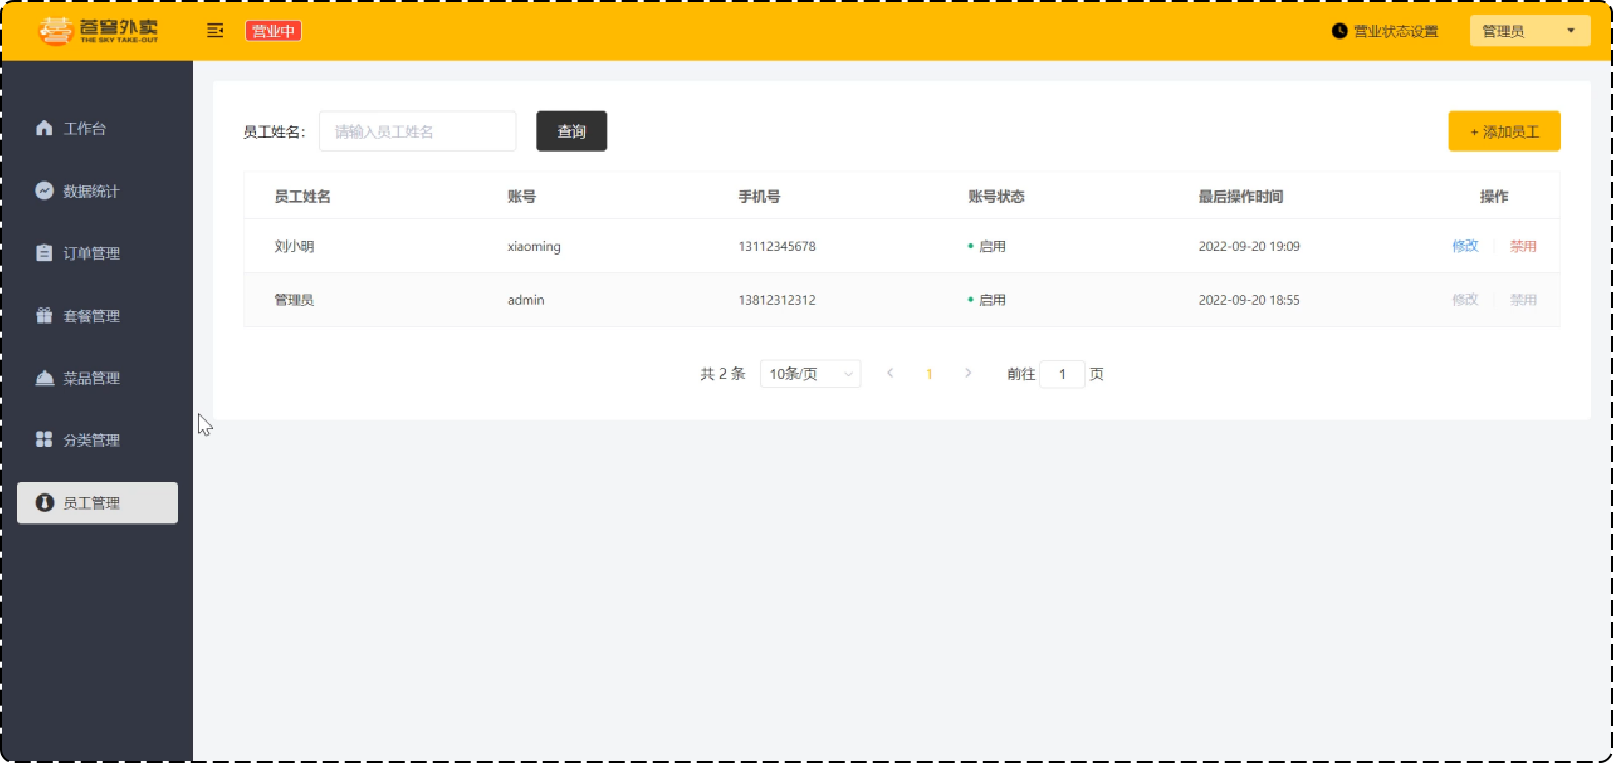 


**菜品分类管理效果：**

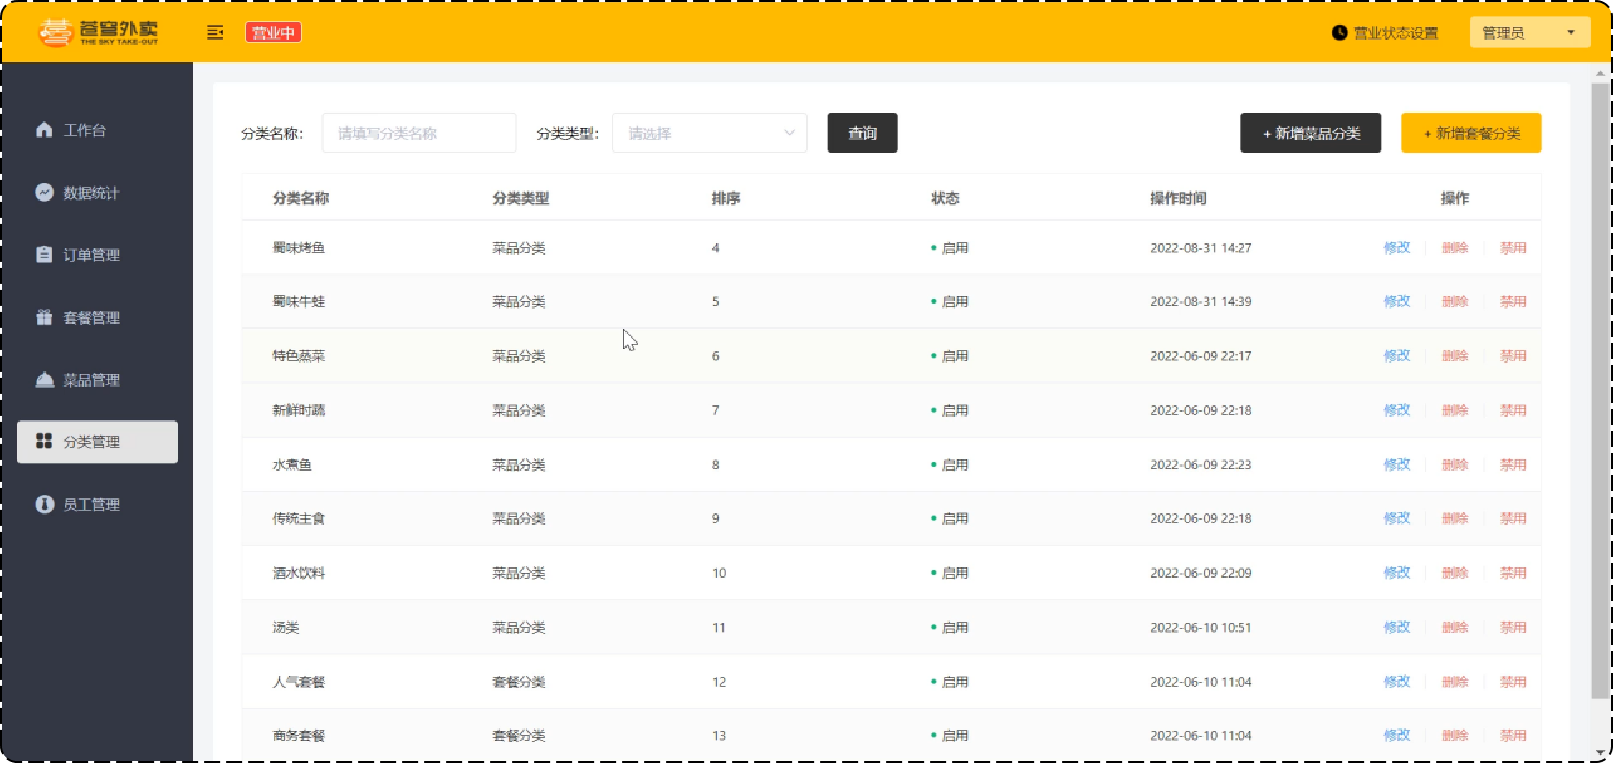


## 1. 新增员工

> **PPT对照：** 第4—30页。


### 1.1 需求分析和设计

> **PPT对照：** 第5—7页。

#### 1.1.1 产品原型

一般在做需求分析时，往往都是对照着产品原型进行分析，因为产品原型比较直观，便于我们理解业务。

后台系统中可以管理员工信息，通过新增员工来添加后台系统用户。

**新增员工原型：**

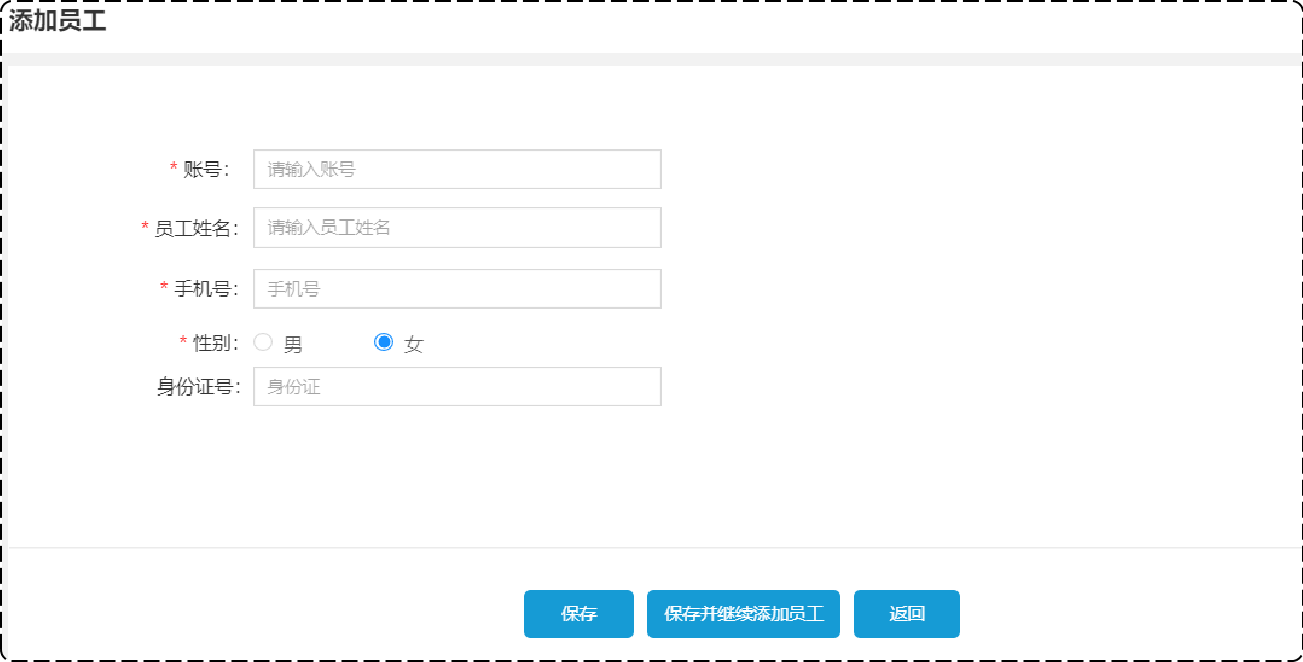 


当填写完表单信息, 点击"保存"按钮后, 会提交该表单的数据到服务端, 在服务端中需要接受数据, 然后将数据保存至数据库中。

**注意事项：**

1. 账号必须是唯一的
2. 手机号为合法的11位手机号码
3. 身份证号为合法的18位身份证号码
4. 密码默认为123456


#### 1.1.2 接口设计

找到资料-->项目接口文档-->苍穹外卖-管理端接口.html

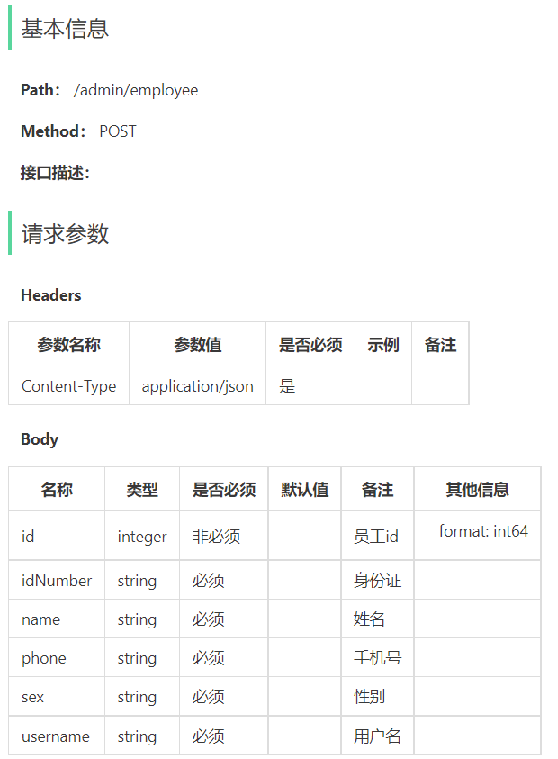 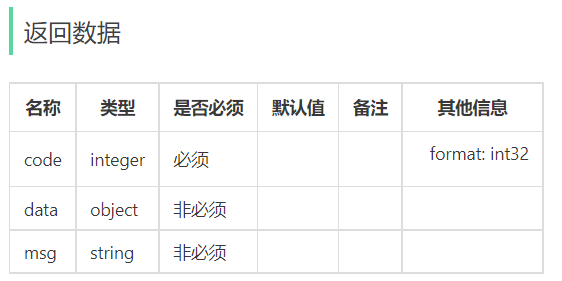

明确新增员工接口的**请求路径、请求方式、请求参数、返回数据**。


本项目约定：

- **管理端**发出的请求，统一使用**/admin**作为前缀。
- **用户端**发出的请求，统一使用**/user**作为前缀。


#### 1.1.3 表设计

新增员工，其实就是将我们新增页面录入的员工数据插入到employee表。

**employee表结构：**

| **字段名**  | **数据类型** | **说明**     | **备注**    |
| ----------- | ------------ | ------------ | ----------- |
| id          | bigint       | 主键         | 自增        |
| name        | varchar(32)  | 姓名         |             |
| username    | varchar(32)  | 用户名       | 唯一        |
| password    | varchar(64)  | 密码         |             |
| phone       | varchar(11)  | 手机号       |             |
| sex         | varchar(2)   | 性别         |             |
| id_number   | varchar(18)  | 身份证号     |             |
| status      | Int          | 账号状态     | 1正常 0锁定 |
| create_time | Datetime     | 创建时间     |             |
| update_time | datetime     | 最后修改时间 |             |
| create_user | bigint       | 创建人id     |             |
| update_user | bigint       | 最后修改人id |             |

其中，employee表中的status字段已经设置了默认值1，表示状态正常。

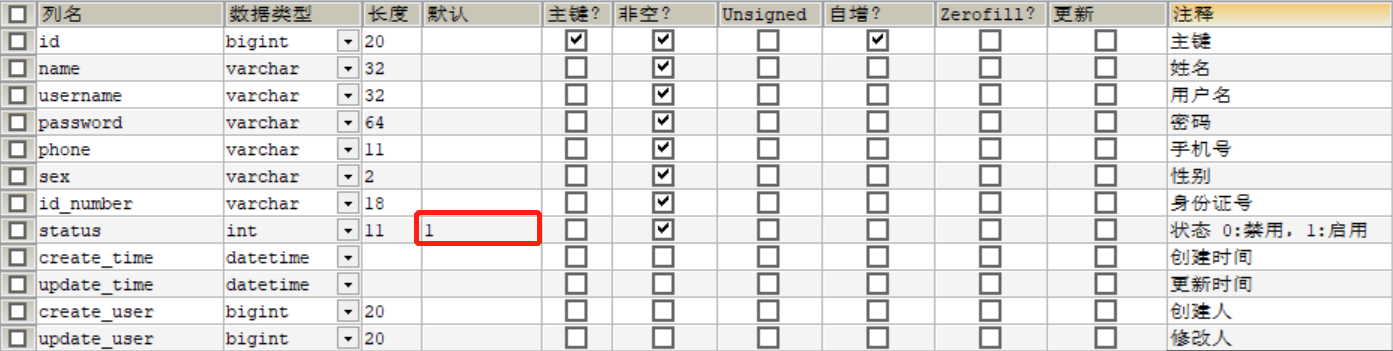


### 新增时由谁决定字段（补充）

DTO接收用户名、姓名、手机号、性别和身份证号。id由数据库生成，密码、启用状态、创建与修改时间、操作人id由后端确定；不能信任前端传来的审计字段。DTO中的id供后续编辑复用，不表示新增时需要传入id。

用户名唯一约束是最终保证。只在Service里“先查询再插入”仍可能遇到并发重复，因此还要处理数据库唯一键冲突。前端表单校验便于提示，后端校验才能覆盖直接调用接口的请求。

11位或18位长度只是校验的一部分，不能把任意18位字符认作合法身份证号。讲义测试JSON中的身份证号为演示值。真实规则应检查格式、出生日期和校验位；手机号规则按业务要求维护。


### 1.2 代码开发

> **PPT对照：** 第9—13页。

#### 1.2.1 设计DTO类

**根据新增员工接口设计对应的DTO**

前端传递参数列表：

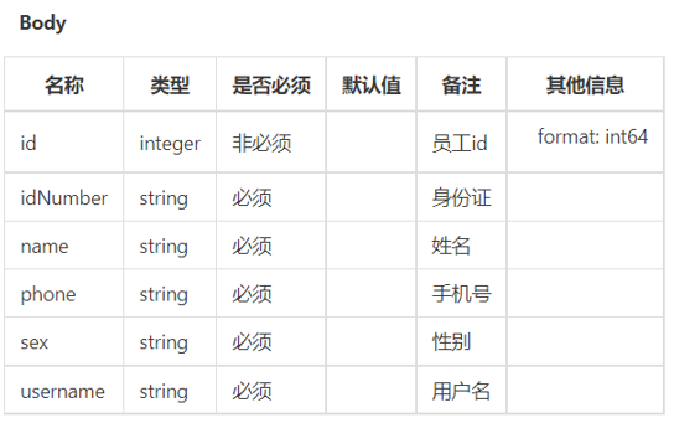 

**思考：**是否可以使用对应的实体类来接收呢？

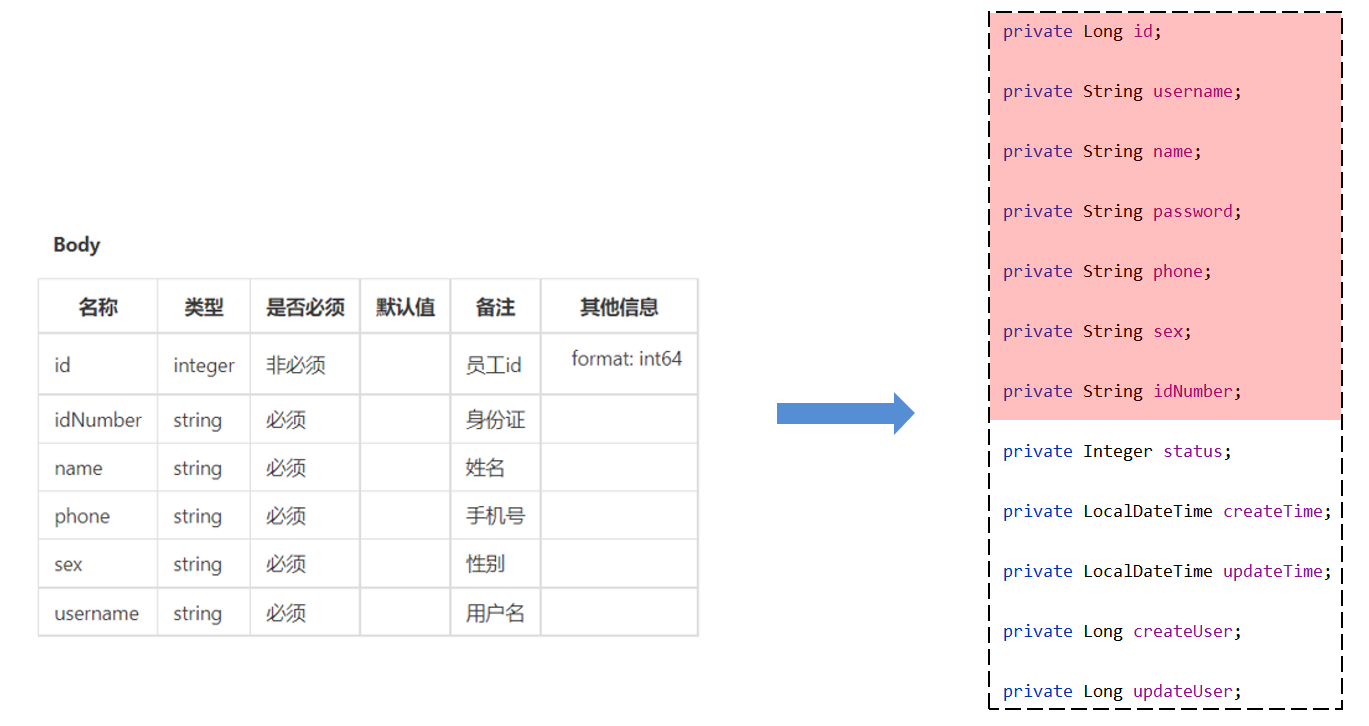 

**注意：**当前端提交的数据和实体类中对应的属性差别比较大时，建议使用DTO来封装数据

由于上述传入参数和实体类有较大差别，所以自定义DTO类。

进入sky-pojo模块，在com.sky.dto包下，已定义EmployeeDTO

```java
package com.sky.dto;

import lombok.Data;

import java.io.Serializable;

@Data
public class EmployeeDTO implements Serializable {

    private Long id;

    private String username;

    private String name;

    private String phone;

    private String sex;

    private String idNumber;

}
```


#### 1.2.2 Controller层

 **EmployeeController中创建新增员工方法**

进入到sky-server模块中，在com.sky.controller.admin包下，在EmployeeController中创建新增员工方法，接收前端提交的参数。

```java
	/**
     * 新增员工
     * @param employeeDTO
     * @return
     */
    @PostMapping
    @ApiOperation("新增员工")
    public Result save(@RequestBody EmployeeDTO employeeDTO){
        log.info("新增员工：{}",employeeDTO);
        employeeService.save(employeeDTO);//该方法后续步骤会定义
        return Result.success();
    }
```

**注：**Result类定义了后端统一返回结果格式。

进入sky-common模块，在com.sky.result包下定义了Result.java

```java
package com.sky.result;

import lombok.Data;

import java.io.Serializable;

/**
 * 后端统一返回结果
 * @param <T>
 */
@Data
public class Result<T> implements Serializable {

    private Integer code; //编码：1成功，0和其它数字为失败
    private String msg; //错误信息
    private T data; //数据

    public static <T> Result<T> success() {
        Result<T> result = new Result<T>();
        result.code = 1;
        return result;
    }

    public static <T> Result<T> success(T object) {
        Result<T> result = new Result<T>();
        result.data = object;
        result.code = 1;
        return result;
    }

    public static <T> Result<T> error(String msg) {
        Result result = new Result();
        result.msg = msg;
        result.code = 0;
        return result;
    }

}
```


#### 1.2.3 Service层接口

**在EmployeeService接口中声明新增员工方法**

进入到sky-server模块中,com.sky.server.EmployeeService

```java
	/**
     * 新增员工
     * @param employeeDTO
     */
    void save(EmployeeDTO employeeDTO);
```


#### 1.2.4 Service层实现类

**在EmployeeServiceImpl中实现新增员工方法**

com.sky.server.impl.EmployeeServiceImpl中创建方法

```java
	/**
     * 新增员工
     *
     * @param employeeDTO
     */
    public void save(EmployeeDTO employeeDTO) {
        Employee employee = new Employee();

        //对象属性拷贝
        BeanUtils.copyProperties(employeeDTO, employee);

        //设置账号的状态，默认正常状态 1表示正常 0表示锁定
        employee.setStatus(StatusConstant.ENABLE);

        //设置密码，默认密码123456
        employee.setPassword(DigestUtils.md5DigestAsHex(PasswordConstant.DEFAULT_PASSWORD.getBytes()));

        //设置当前记录的创建时间和修改时间
        employee.setCreateTime(LocalDateTime.now());
        employee.setUpdateTime(LocalDateTime.now());

        //设置当前记录创建人id和修改人id
        employee.setCreateUser(10L);//目前写个假数据，后期修改
        employee.setUpdateUser(10L);

        employeeMapper.insert(employee);//后续步骤定义
    }
```


在sky-common模块com.sky.constants包下已定义StatusConstant.java

```java
package com.sky.constant;

/**
 * 状态常量，启用或者禁用
 */
public class StatusConstant {

    //启用
    public static final Integer ENABLE = 1;

    //禁用
    public static final Integer DISABLE = 0;
}

```


#### 1.2.5 Mapper层

**在EmployeeMapper中声明insert方法**

com.sky.EmployeeMapper中添加方法

```java
	/**
     * 插入员工数据
     * @param employee
     */
    @Insert("insert into employee (name, username, password, phone, sex, id_number, create_time, update_time, create_user, update_user,status) " +
            "values " +
            "(#{name},#{username},#{password},#{phone},#{sex},#{idNumber},#{createTime},#{updateTime},#{createUser},#{updateUser},#{status})")
    void insert(Employee employee);
```


在application.yml中已开启驼峰命名，故id_number和idNumber可对应。

```yaml
mybatis:
  configuration:
    #开启驼峰命名
    map-underscore-to-camel-case: true
```


### 新增员工实现要点（补充与勘误）

- `BeanUtils.copyProperties`按属性名进行浅拷贝，不会完成业务校验、密码哈希或类型转换。拷贝后设置服务端字段，再执行插入。
- 新增默认 `StatusConstant.ENABLE`；课程密码使用 `PasswordConstant.DEFAULT_PASSWORD` 的MD5，沿用第一章的教学方案。实际产品应有首次改密与合适的密码哈希策略。
- 可以用同一个 `LocalDateTime now` 设置创建和更新时间，避免同一次新增产生细微时间差。
- SQL中的 `#{idNumber}`取Java属性值；`map-underscore-to-camel-case`主要帮助查询结果中的 `id_number` 映射到 `idNumber`，不是把任意错误的参数名自动修正。
- 日志记录整个EmployeeDTO会包含手机号、身份证号等敏感信息。常规日志只保留操作类型和必要的非敏感标识。

讲义中的包名说明有笔误：Service对应 `com.sky.service` / `com.sky.service.impl`，Mapper对应 `com.sky.mapper`，常量对应 `com.sky.constant`。以代码中的package和初始工程为准。

```java
LocalDateTime now = LocalDateTime.now();
employee.setCreateTime(now);
employee.setUpdateTime(now);
employee.setCreateUser(BaseContext.getCurrentId());
employee.setUpdateUser(BaseContext.getCurrentId());
```

`BaseContext`需要完成第1.4节的拦截器设置之后才有值，不再硬编码 `10L`。


### 1.3 功能测试

> **PPT对照：** 第15—20页。

代码已经发开发完毕，对新增员工功能进行测试。

**功能测试实现方式：**

- 通过接口文档测试
- 通前后端联调测试

接下来我们使用上述两种方式分别测试。


#### 1.3.1 接口文档测试

**启动服务：**访问http://localhost:8080/doc.html，进入新增员工接口

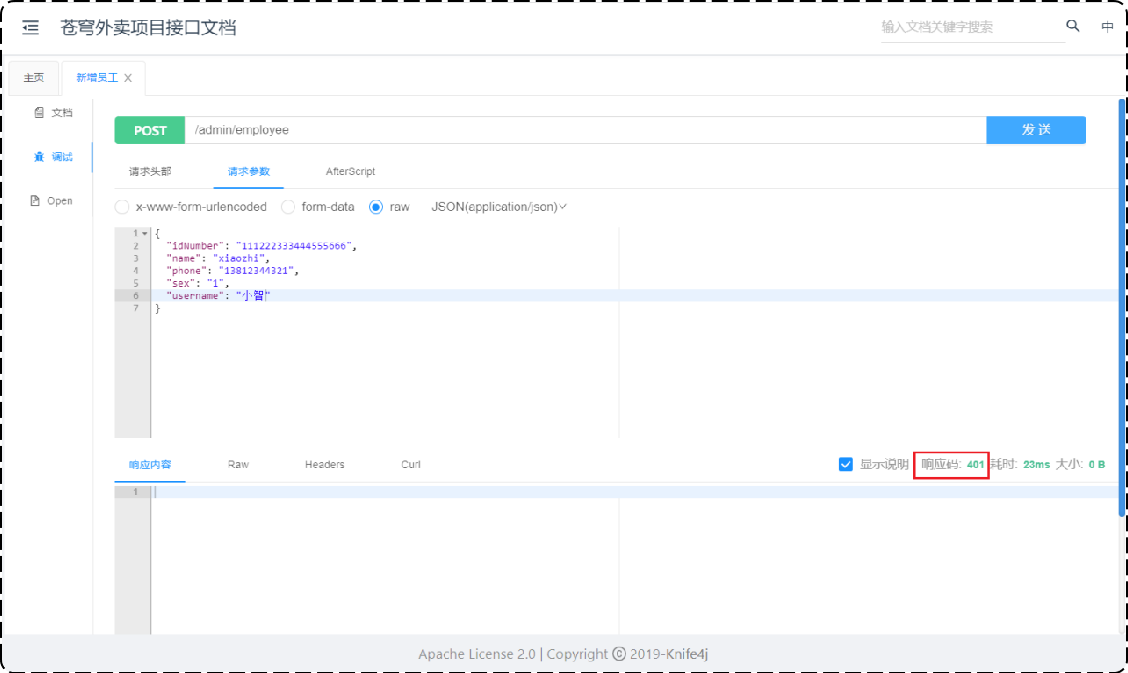   

json数据：

```json
{
  "id": 0,
  "idNumber": "111222333444555666",
  "name": "xiaozhi",
  "phone": "13812344321",
  "sex": "1",
  "username": "小智"
}
```

响应码：401 报错

**通过断点调试：**进入到JwtTokenAdminInterceptor拦截器

```java
 	/**
     * 校验jwt
     *
     * @param request
     * @param response
     * @param handler
     * @return
     * @throws Exception
     */
    public boolean preHandle(HttpServletRequest request, HttpServletResponse response, Object handler) throws Exception {
        //判断当前拦截到的是Controller的方法还是其他资源
        if (!(handler instanceof HandlerMethod)) {
            //当前拦截到的不是动态方法，直接放行
            return true;
        }

        //1、从请求头中获取令牌 jwtProperties.getAdminTokenName()获取为token
        String token = request.getHeader(jwtProperties.getAdminTokenName());

        //2、校验令牌
        try {
            log.info("jwt校验:{}", token);
            Claims claims = JwtUtil.parseJWT(jwtProperties.getAdminSecretKey(), token);
            Long empId = Long.valueOf(claims.get(JwtClaimsConstant.EMP_ID).toString());
            log.info("当前员工id：", empId);
            //3、通过，放行
            return true;
        } catch (Exception ex) {
            //4、不通过，响应401状态码
            response.setStatus(401);
            return false;
        }
    }
```

**报错原因：**由于JWT令牌校验失败，导致EmployeeController的save方法没有被调用

**解决方法：**调用员工登录接口获得一个合法的JWT令牌

使用admin用户登录获取令牌

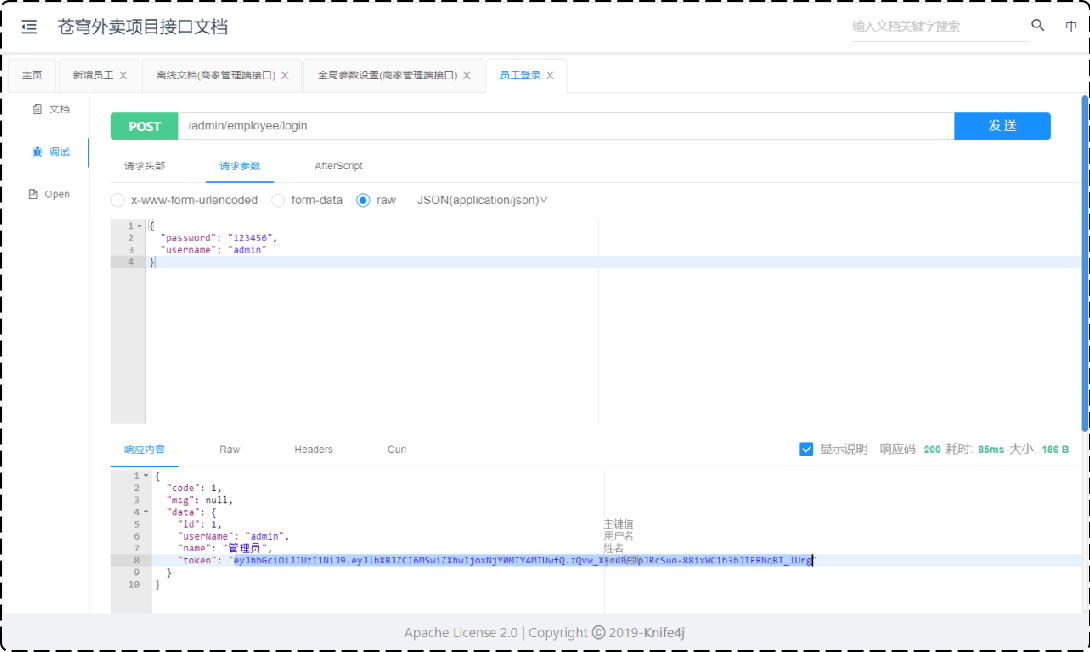 

**添加令牌：**

将合法的JWT令牌添加到全局参数中

文档管理-->全局参数设置-->添加参数

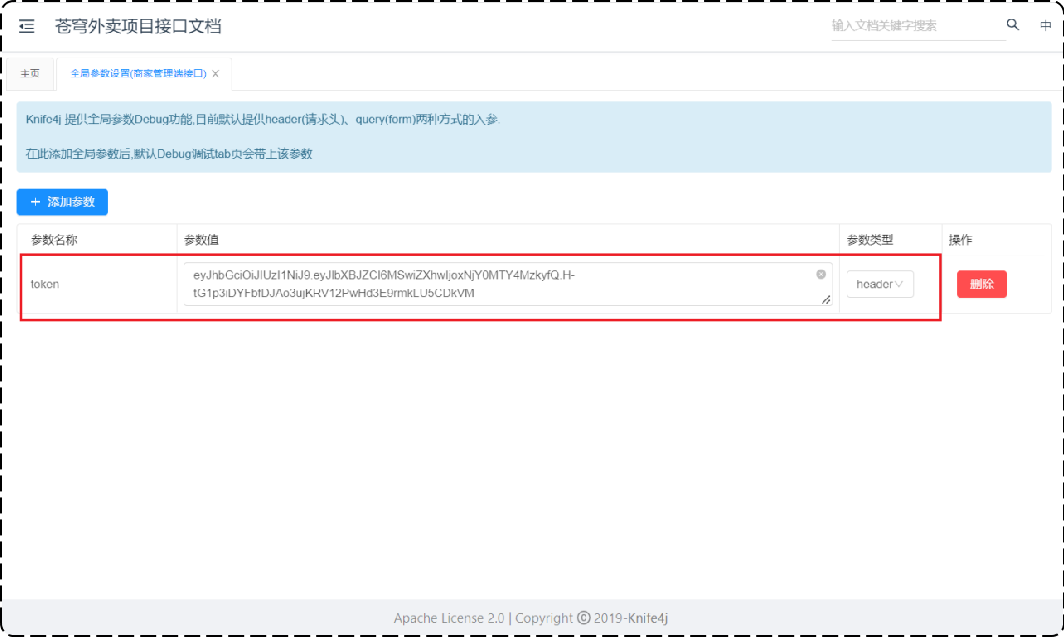 

**接口测试：**

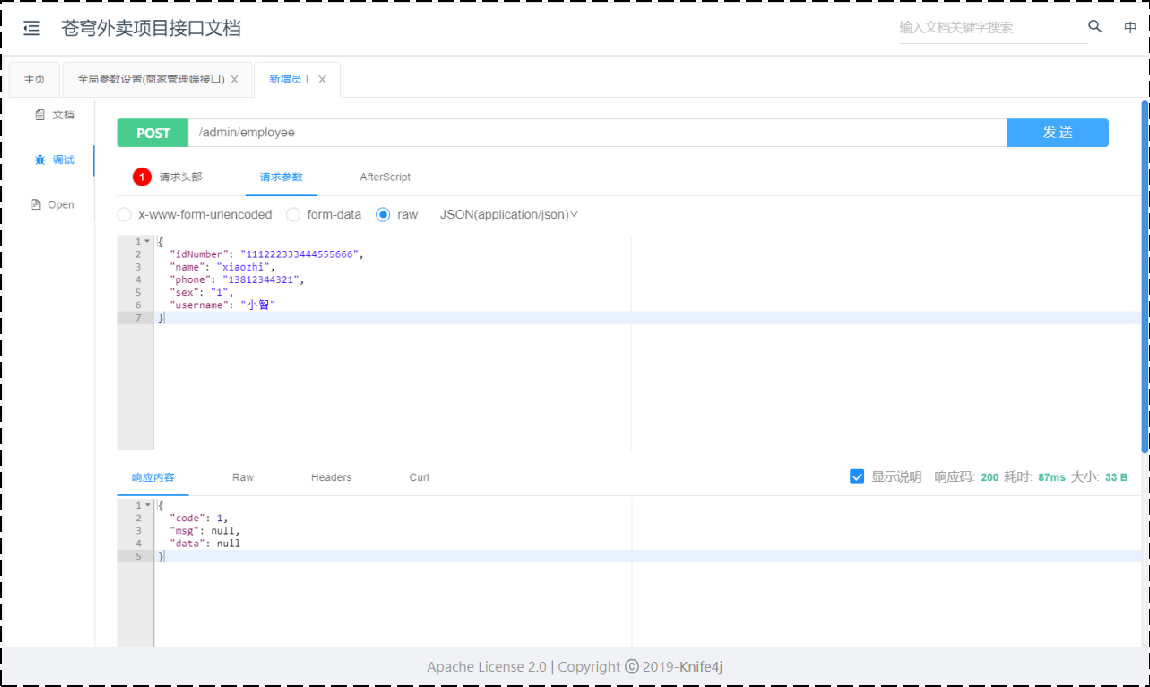 

其中，请求头部含有JWT令牌

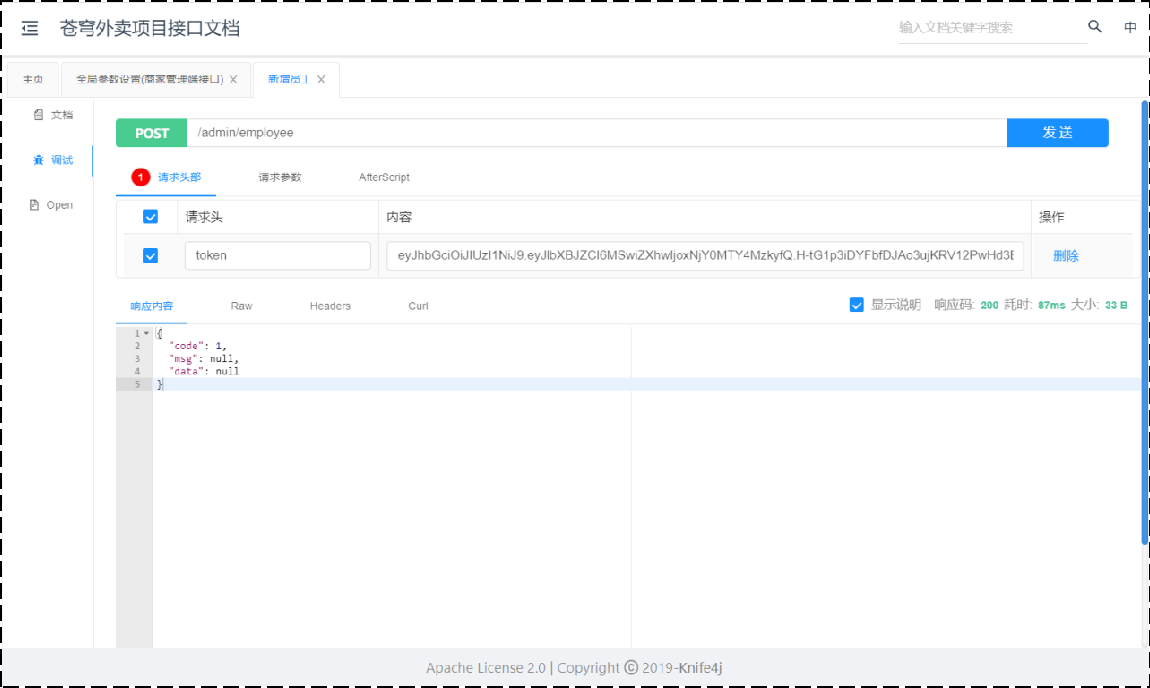 

**查看employee表：**

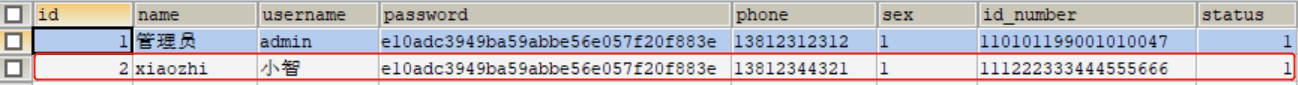

测试成功。


#### 1.3.2 前后端联调测试

启动nginx,访问 http://localhost

登录-->员工管理-->添加员工

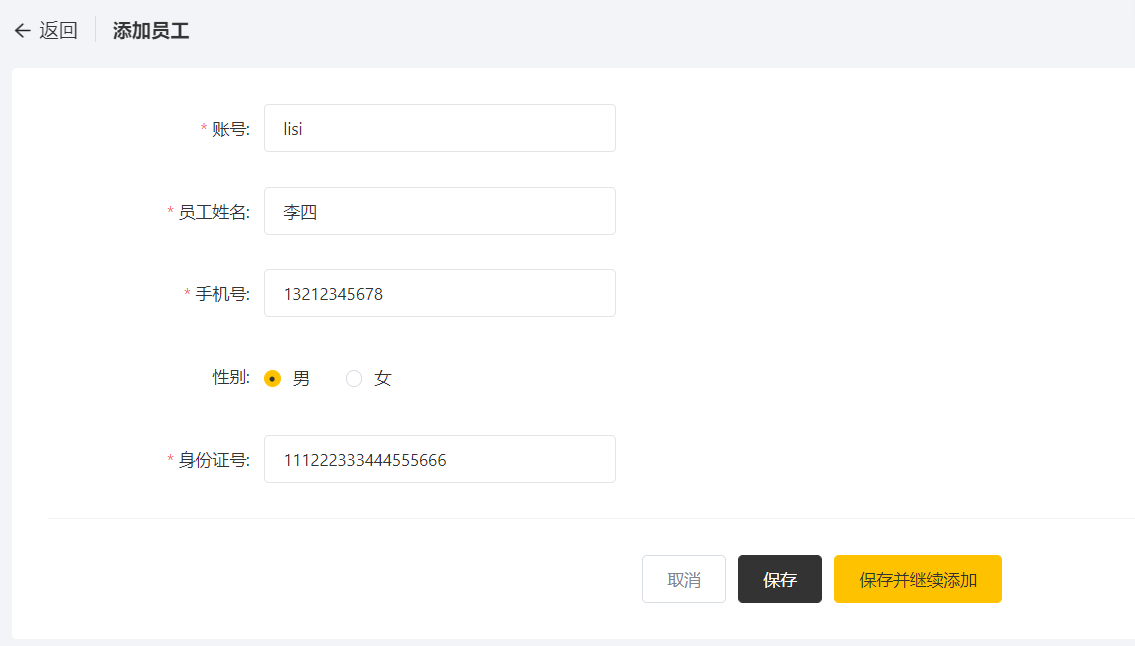 

保存后，查看employee表

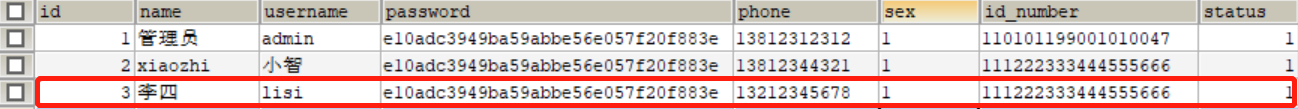 

测试成功。


**注意：**由于开发阶段前端和后端是并行开发的，后端完成某个功能后，此时前端对应的功能可能还没有开发完成，
导致无法进行前后端联调测试。所以在开发阶段，后端测试主要以接口文档测试为主。


### 401与业务错误分开看（补充）

401表示请求没有通过认证，Controller可能根本没有执行。先调用登录取得token，再以 `jwtProperties.getAdminTokenName()` 指定的请求头携带它；讲义配置是 `token`。不要自动改成 `Authorization: Bearer ...`，除非项目拦截器采用这种格式。

| 现象 | 应检查的位置 |
| --- | --- |
| 无token、伪造token或token过期，返回401 | 请求头、JWT拦截器与密钥配置 |
| token有效但用户名重复 | 数据库唯一约束与异常处理 |
| 响应成功但数据未按预期变化 | 实际库名、SQL、插入参数和事务日志 |
| 数据创建人总是10 | Service仍用固定id，或没有完成BaseContext接入 |

本章 `Result` 约定 `code=1` 成功、`code=0` 失败，它与HTTP状态码是不同层面的信号。客户端应同时处理认证状态与业务结果。

讲义 `log.info("当前员工id：", empId)` 缺少占位符，应为 `log.info("当前员工id：{}", empId)`。不要打印完整token；日志里保留必要的认证结果即可。


### 1.4 代码完善

> **PPT对照：** 第22—30页。

目前，程序存在的问题主要有两个：

- 录入的用户名已存，抛出的异常后没有处理
- 新增员工时，创建人id和修改人id设置为固定值

接下来，我们对上述两个问题依次进行分析和解决。


#### 1.4.1 问题一

**描述：**录入的用户名已存，抛出的异常后没有处理

**分析：**

新增username=zhangsan的用户，若employee表中之前已存在。

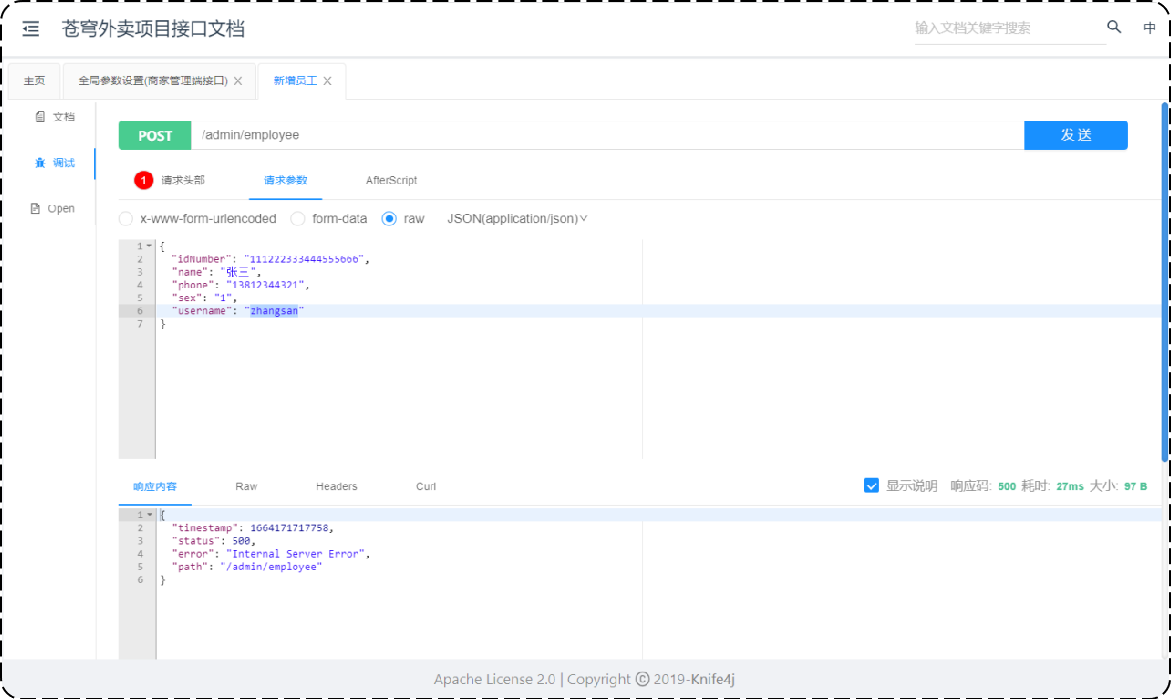 

后台报错信息：

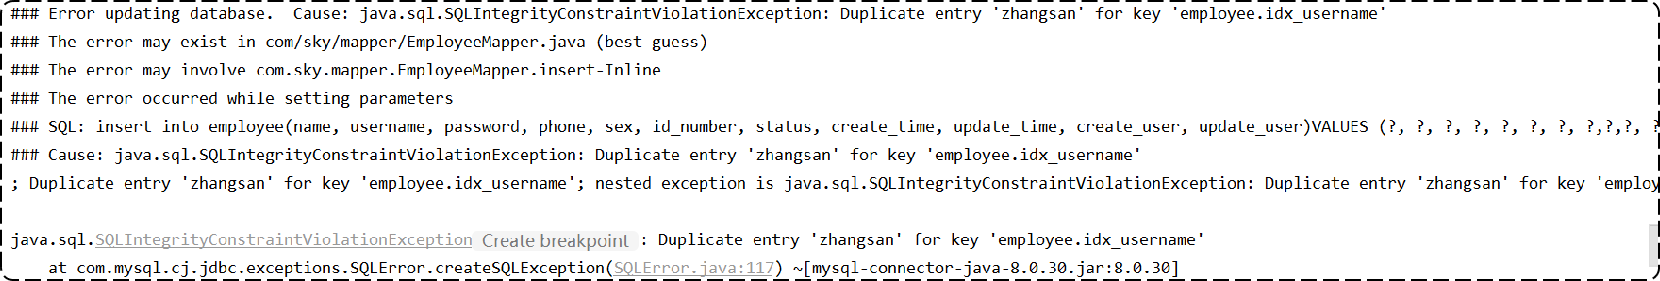 

查看employee表结构：

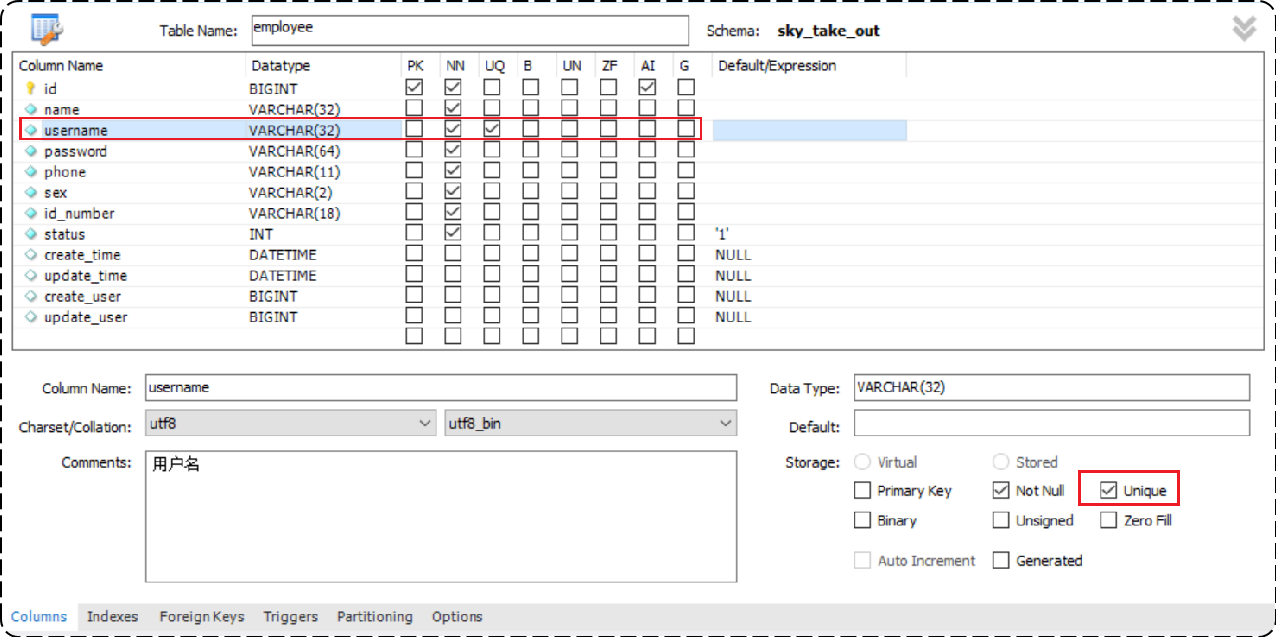 

发现，username已经添加了唯一约束，不能重复。

**解决：**

通过全局异常处理器来处理。

进入到sky-server模块，com.sky.hander包下，GlobalExceptionHandler.java添加方法

```java
	/**
     * 处理SQL异常
     * @param ex
     * @return
     */
    @ExceptionHandler
    public Result exceptionHandler(SQLIntegrityConstraintViolationException ex){
        //Duplicate entry 'zhangsan' for key 'employee.idx_username'
        String message = ex.getMessage();
        if(message.contains("Duplicate entry")){
            String[] split = message.split(" ");
            String username = split[2];
            String msg = username + MessageConstant.ALREADY_EXISTS;
            return Result.error(msg);
        }else{
            return Result.error(MessageConstant.UNKNOWN_ERROR);
        }
    }
```

进入到sky-common模块，在MessageConstant.java添加

```java
public static final String ALREADY_EXISTS = "已存在";
```

再次，接口测试：

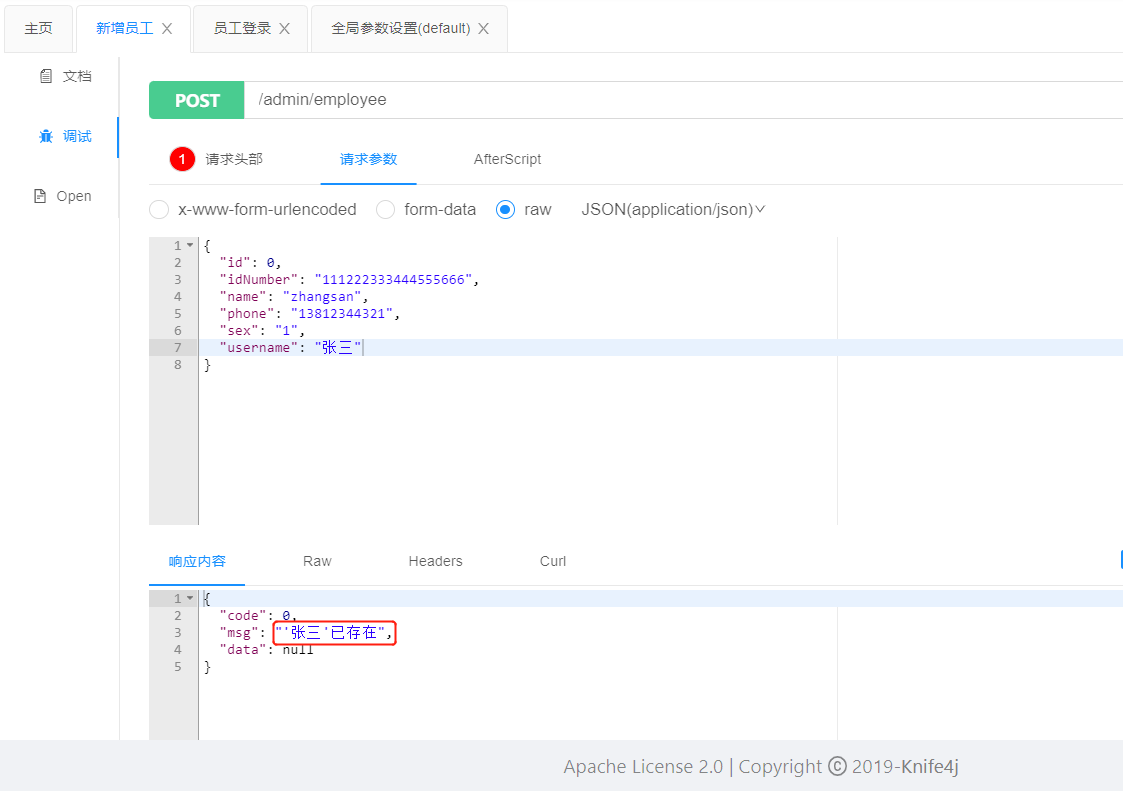 


####  1.4.2 问题二

**描述**：新增员工时，创建人id和修改人id设置为固定值

**分析：**

```java
	/**
     * 新增员工
     *
     * @param employeeDTO
     */
    public void save(EmployeeDTO employeeDTO) {
        Employee employee = new Employee();
        //................
        //////////当前设置的id为固定值10//////////
        employee.setCreateUser(10L);
        employee.setUpdateUser(10L);
        //////////////////////////////////////
        //.................................

        employeeMapper.insert(employee);//后续步骤定义
    }
```

**解决：**

通过某种方式动态获取当前登录员工的id。

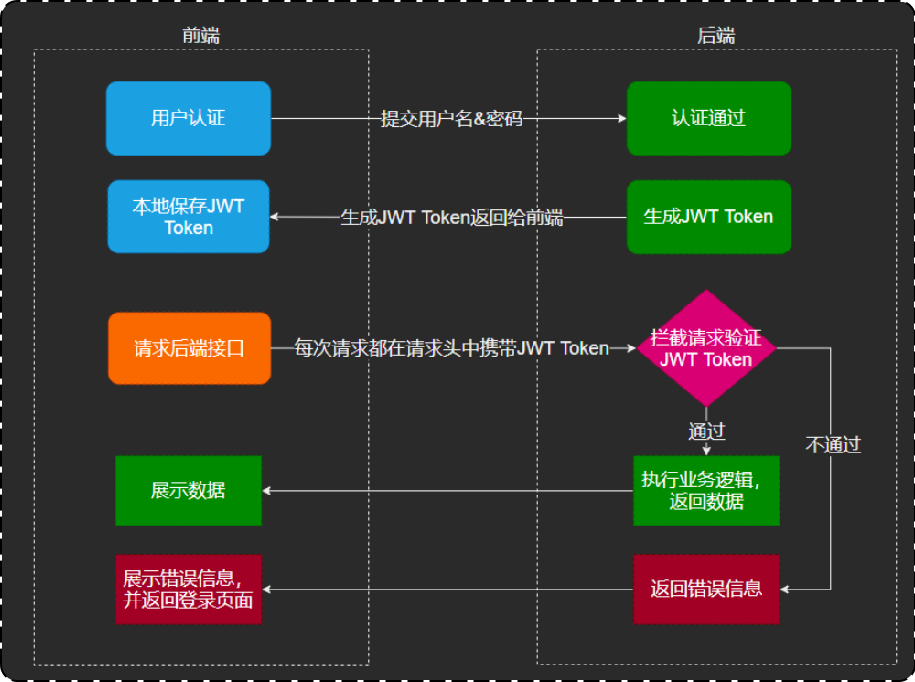 

员工登录成功后会生成JWT令牌并响应给前端：

在sky-server模块

```java
package com.sky.controller.admin;
/**
 * 员工管理
 */
@RestController
@RequestMapping("/admin/employee")
@Slf4j
@Api(tags = "员工相关接口")
public class EmployeeController {

    @Autowired
    private EmployeeService employeeService;
    @Autowired
    private JwtProperties jwtProperties;

    /**
     * 登录
     *
     * @param employeeLoginDTO
     * @return
     */
    @PostMapping("/login")
    @ApiOperation(value = "员工登录")
    public Result<EmployeeLoginVO> login(@RequestBody EmployeeLoginDTO employeeLoginDTO) {
        //.........

        //登录成功后，生成jwt令牌
        Map<String, Object> claims = new HashMap<>();
        claims.put(JwtClaimsConstant.EMP_ID, employee.getId());
        String token = JwtUtil.createJWT(
                jwtProperties.getAdminSecretKey(),
                jwtProperties.getAdminTtl(),
                claims);

        //............

        return Result.success(employeeLoginVO);
    }

}
```

后续请求中，前端会携带JWT令牌，通过JWT令牌可以解析出当前登录员工id：

JwtTokenAdminInterceptor.java

```java
package com.sky.interceptor;

/**
 * jwt令牌校验的拦截器
 */
@Component
@Slf4j
public class JwtTokenAdminInterceptor implements HandlerInterceptor {

    @Autowired
    private JwtProperties jwtProperties;

    /**
     * 校验jwt
     *
     * @param request
     * @param response
     * @param handler
     * @return
     * @throws Exception
     */
    public boolean preHandle(HttpServletRequest request, HttpServletResponse response, Object handler) throws Exception {
       
		//..............
        
        //1、从请求头中获取令牌
        String token = request.getHeader(jwtProperties.getAdminTokenName());

        //2、校验令牌
        try {
            log.info("jwt校验:{}", token);
            Claims claims = JwtUtil.parseJWT(jwtProperties.getAdminSecretKey(), token);
            Long empId = Long.valueOf(claims.get(JwtClaimsConstant.EMP_ID).toString());
            log.info("当前员工id：", empId);
            //3、通过，放行
            return true;
        } catch (Exception ex) {
            //4、不通过，响应401状态码
            response.setStatus(401);
            return false;
        }
    }
}
```

**思考：**解析出登录员工id后，如何传递给Service的save方法？

通过ThreadLocal进行传递。


#### 1.4.3 ThreadLocal

**介绍：**

ThreadLocal 并不是一个Thread，而是Thread的局部变量。
ThreadLocal为每个线程提供单独一份存储空间，具有线程隔离的效果，只有在线程内才能获取到对应的值，线程外则不能访问。

**常用方法：**

- public void set(T value)  设置当前线程的线程局部变量的值
- public T get()  返回当前线程所对应的线程局部变量的值
- public void remove()        移除当前线程的线程局部变量

对ThreadLocal有了一定认识后，接下来继续解决**问题二**

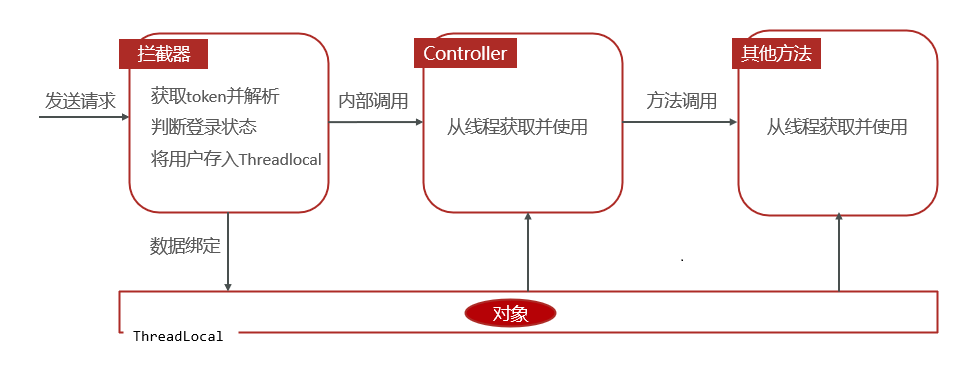 

初始工程中已经封装了 ThreadLocal 操作的工具类：

在sky-common模块

```java
package com.sky.context;

public class BaseContext {

    public static ThreadLocal<Long> threadLocal = new ThreadLocal<>();

    public static void setCurrentId(Long id) {
        threadLocal.set(id);
    }

    public static Long getCurrentId() {
        return threadLocal.get();
    }

    public static void removeCurrentId() {
        threadLocal.remove();
    }

}
```

在拦截器中解析出当前登录员工id，并放入线程局部变量中：

在sky-server模块中，拦截器：

```java
package com.sky.interceptor;

/**
 * jwt令牌校验的拦截器
 */
@Component
@Slf4j
public class JwtTokenAdminInterceptor implements HandlerInterceptor {

    @Autowired
    private JwtProperties jwtProperties;

    /**
     * 校验jwt
     *
     * @param request
     * @param response
     * @param handler
     * @return
     * @throws Exception
     */
    public boolean preHandle(HttpServletRequest request, HttpServletResponse response, Object handler) throws Exception {
        
		//.............................
       
        //2、校验令牌
        try {
            //.................
            Claims claims = JwtUtil.parseJWT(jwtProperties.getAdminSecretKey(), token);
            Long empId = Long.valueOf(claims.get(JwtClaimsConstant.EMP_ID).toString());
            log.info("当前员工id：", empId);
            /////将用户id存储到ThreadLocal////////
            BaseContext.setCurrentId(empId);
            ////////////////////////////////////
            //3、通过，放行
            return true;
        } catch (Exception ex) {
            //......................
        }
    }
}
```

在Service中获取线程局部变量中的值：

```java
	/**
     * 新增员工
     *
     * @param employeeDTO
     */
    public void save(EmployeeDTO employeeDTO) {
        //.............................

        //设置当前记录创建人id和修改人id
        employee.setCreateUser(BaseContext.getCurrentId());//目前写个假数据，后期修改
        employee.setUpdateUser(BaseContext.getCurrentId());

        employeeMapper.insert(employee);
    }
```

测试：使用admin(id=1)用户登录后添加一条记录

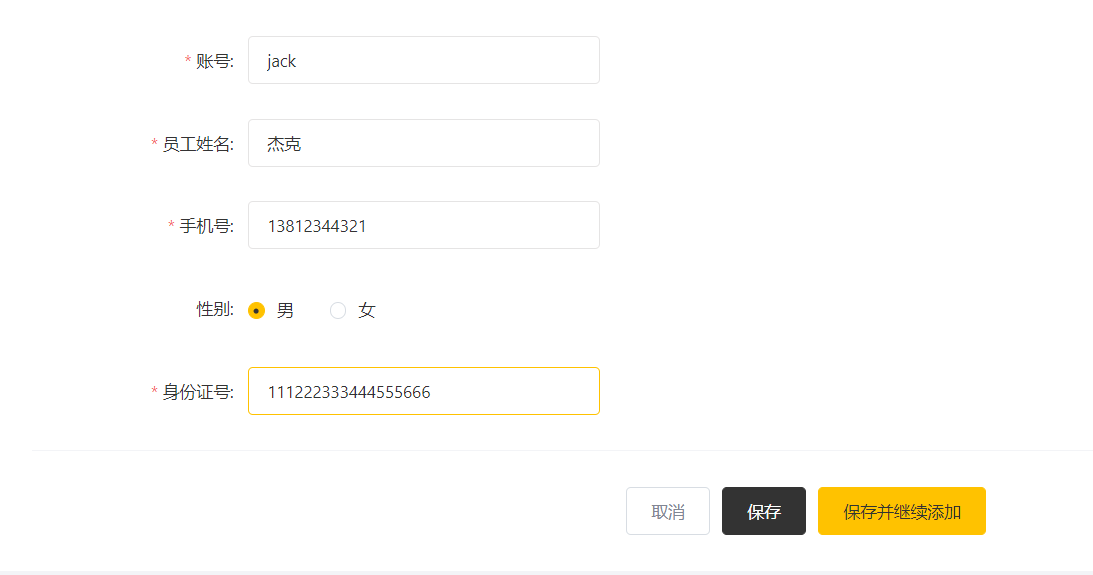 

查看employee表记录

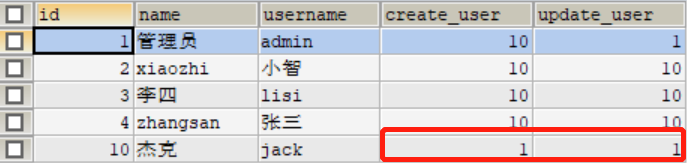


### 唯一约束异常与线程上下文（补充）

#### 唯一键冲突处理

讲义按异常文本 `Duplicate entry` 和空格拆分用户名，只适合解释流程。数据库驱动消息、用户名包含空格、不同唯一索引都可能让这一写法失效；此外MyBatis与Spring可能将异常转换为 `DuplicateKeyException`。

可以在现有全局异常处理器内增加针对Spring异常的处理，不直接向用户输出SQL、表名或原始异常。下面是补充写法，需与工程已有异常处理方法合并。

```java
@ExceptionHandler(org.springframework.dao.DuplicateKeyException.class)
public Result<Void> handleDuplicateKey(org.springframework.dao.DuplicateKeyException ex) {
    return Result.error("存在重复的唯一字段，请检查用户名或分类名称");
}
```

如果仍使用原SQL异常处理，必须核对实际抛出的异常类型与cause链。统一处理器返回业务JSON，内部日志保留必要的诊断信息。

#### ThreadLocal要清理

`ThreadLocal`给每个线程保存独立值。课程的同步MVC链路中，拦截器与Service通常在同一请求线程上工作，所以能用它传递empId。Tomcat使用线程池，后续请求可能复用线程，不是每次请求创建一个永久独占的新线程。

仅调用 `set` / `get` 会留下旧值。在已有拦截器里补充请求结束清理：

```java
@Override
public void afterCompletion(HttpServletRequest request,
                            HttpServletResponse response,
                            Object handler,
                            Exception ex) {
    BaseContext.removeCurrentId();
}
```

这些Servlet类型使用与初始工程相同的imports。还可在 `preHandle` 开始清除旧值，在验签成功后 `setCurrentId`；失败返回false的分支也应清理，因为当前拦截器自身的 `preHandle` 返回false时，不会触发自己的 `afterCompletion`。异步任务、线程切换场景不能假设上下文自动传播。

| 步骤 | 谁处理 | 保存的数据 |
| --- | --- | --- |
| 登录成功 | EmployeeController | 在签名JWT中写入empId |
| 受保护请求到达 | JwtTokenAdminInterceptor | 验签后解析empId |
| 执行业务 | Service读取BaseContext | 写create_user / update_user |
| 请求结束 | 拦截器清理 | remove当前线程的值 |

**认证与授权。** 有效token证明身份，不自动证明有权新增或修改员工。实际产品还要校验操作权限；管理端URL前缀不能代替授权逻辑。


### 1.5 代码提交

点击提交：

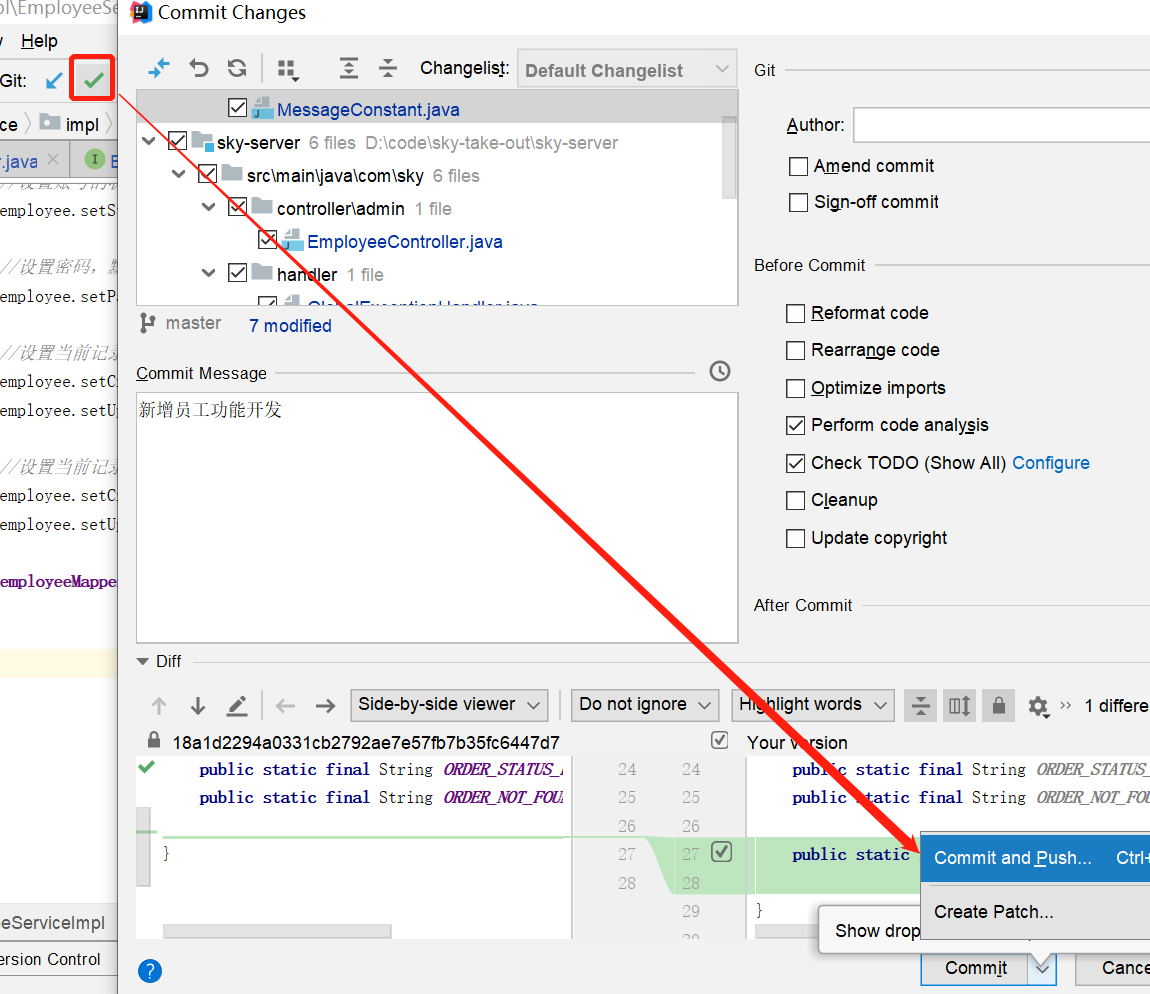 

提交过程中，出现提示：

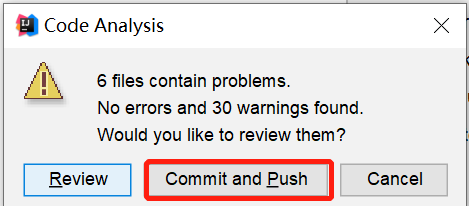 

继续push:

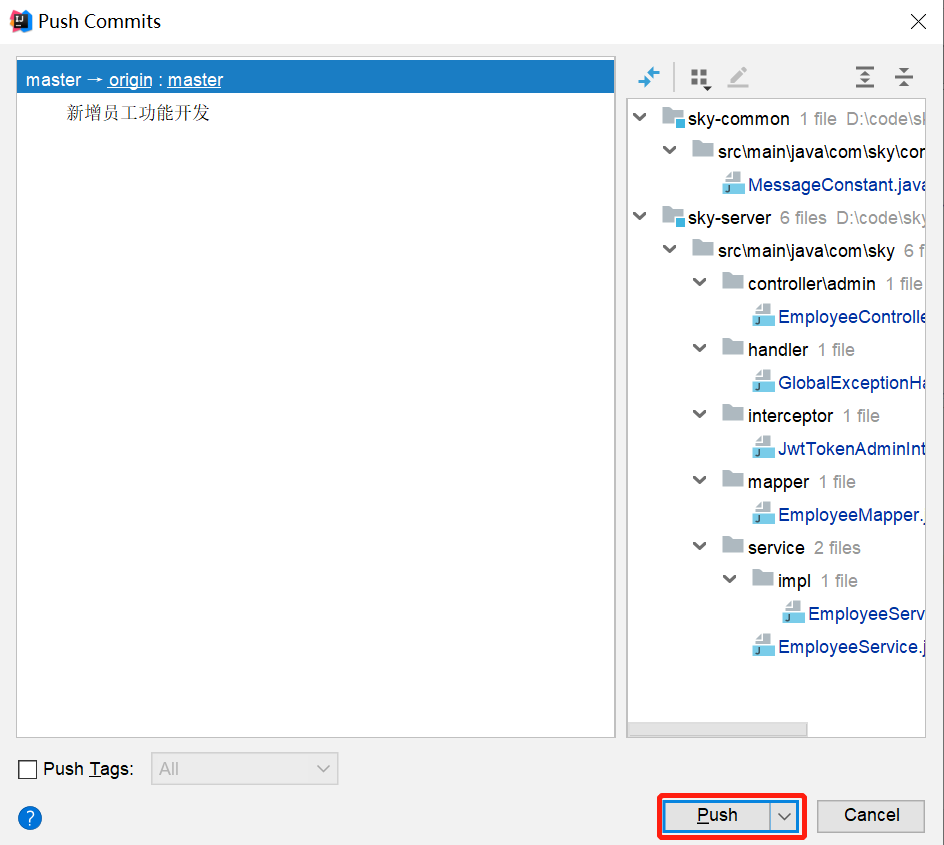 

推送成功：

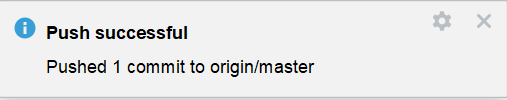


### 功能完成后的提交（补充）

把DTO、Controller、Service、Mapper与XML、异常处理和必要配置一起检查，再在业务代码仓库提交。按功能记录变更，排除生成文件、密钥、测试token和个人本地配置。本次写笔记没有执行源码仓库的Git提交或推送。


## 2. 员工分页查询

> **PPT对照：** 第32—48页。


### 2.1 需求分析和设计

> **PPT对照：** 第33—34页。

#### 2.1.1 产品原型

系统中的员工很多的时候，如果在一个页面中全部展示出来会显得比较乱，不便于查看，所以一般的系统中都会以分页的方式来展示列表数据。而在我们的分页查询页面中, 除了分页条件以外，还有一个查询条件 "员工姓名"。

**查询员工原型：**

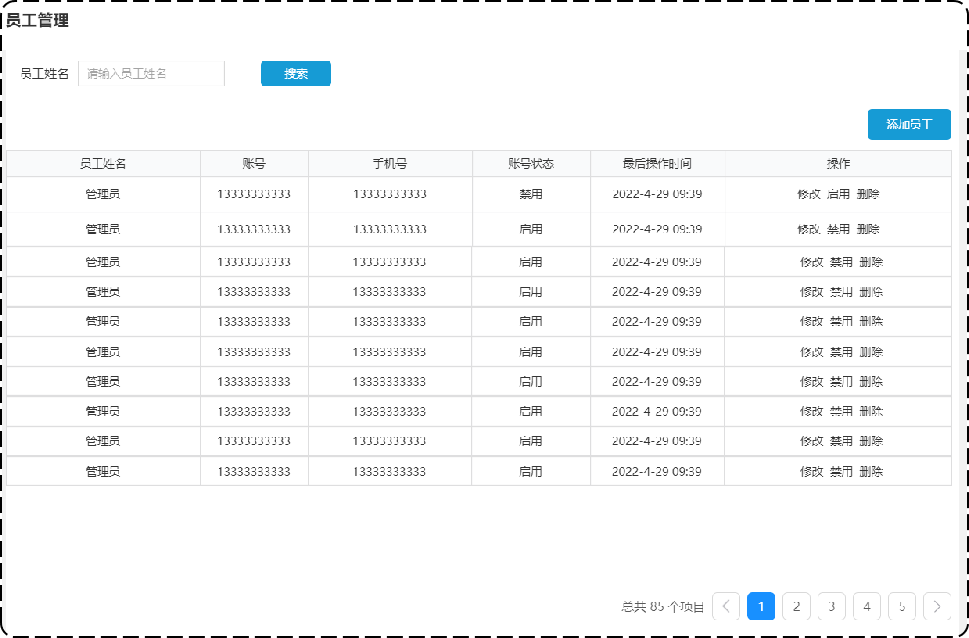 

**业务规则**：

- 根据页码展示员工信息
- 每页展示10条数据
- 分页查询时可以根据需要，输入员工姓名进行查询


#### 2.1.2 接口设计

找到资料-->项目接口文档-->苍穹外卖-管理端接口.html

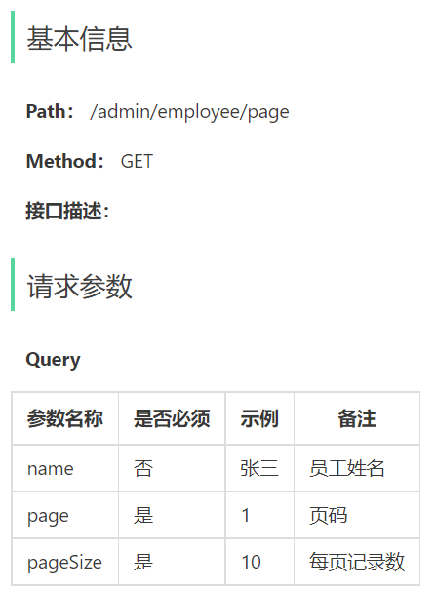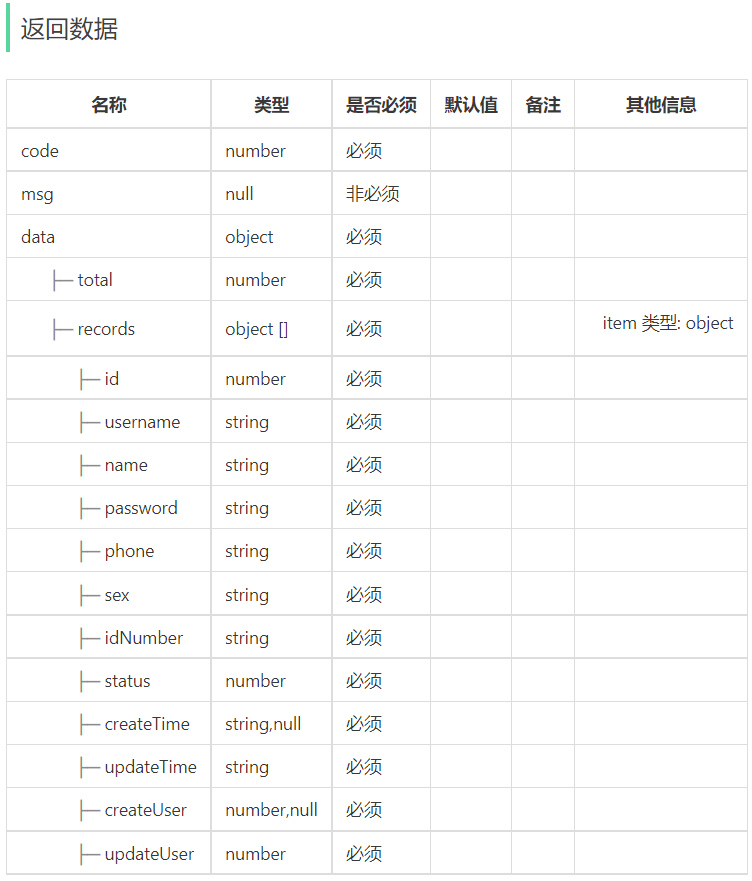

**注意事项：**

- 请求参数类型为Query，不是json格式提交，在路径后直接拼接。/admin/employee/page?name=zhangsan
- 返回数据中records数组中使用Employee实体类对属性进行封装。


### 分页请求与响应（补充）

```http
GET /admin/employee/page?page=1&pageSize=10&name=张
token: <登录后取得的token>
```

GET参数来自查询字符串，不是JSON body。`EmployeePageQueryDTO`通过属性名接收page、pageSize和name；这里不添加 `@RequestBody`。

成功响应结构是 `Result<PageResult>`：`data.total`为满足筛选条件的总记录数，`data.records`为当前页数据。不能用 `records.size()`替代total。数据不足一页、没有匹配结果、页码超过末页都应明确预期。


### 2.2 代码开发

> **PPT对照：** 第36—43页。

#### 2.2.1 设计DTO类

根据请求参数进行封装，在sky-pojo模块中

```java
package com.sky.dto;

import lombok.Data;

import java.io.Serializable;

@Data
public class EmployeePageQueryDTO implements Serializable {

    //员工姓名
    private String name;

    //页码
    private int page;

    //每页显示记录数
    private int pageSize;

}

```


#### 2.2.2 封装PageResult

后面所有的分页查询，统一都封装为PageResult对象。

在sky-common模块

```java
package com.sky.result;

import lombok.AllArgsConstructor;
import lombok.Data;
import lombok.NoArgsConstructor;

import java.io.Serializable;
import java.util.List;

/**
 * 封装分页查询结果
 */
@Data
@AllArgsConstructor
@NoArgsConstructor
public class PageResult implements Serializable {

    private long total; //总记录数

    private List records; //当前页数据集合

}

```

员工信息分页查询后端返回的对象类型为: Result<PageResult>

```java
package com.sky.result;

import lombok.Data;

import java.io.Serializable;

/**
 * 后端统一返回结果
 * @param <T>
 */
@Data
public class Result<T> implements Serializable {

    private Integer code; //编码：1成功，0和其它数字为失败
    private String msg; //错误信息
    private T data; //数据

    public static <T> Result<T> success() {
        Result<T> result = new Result<T>();
        result.code = 1;
        return result;
    }

    public static <T> Result<T> success(T object) {
        Result<T> result = new Result<T>();
        result.data = object;
        result.code = 1;
        return result;
    }

    public static <T> Result<T> error(String msg) {
        Result result = new Result();
        result.msg = msg;
        result.code = 0;
        return result;
    }

}
```


#### 2.2.3 Controller层

在sky-server模块中，com.sky.controller.admin.EmployeeController中添加分页查询方法。

```java
	/**
     * 员工分页查询
     * @param employeePageQueryDTO
     * @return
     */
    @GetMapping("/page")
    @ApiOperation("员工分页查询")
    public Result<PageResult> page(EmployeePageQueryDTO employeePageQueryDTO){
        log.info("员工分页查询，参数为：{}", employeePageQueryDTO);
        PageResult pageResult = employeeService.pageQuery(employeePageQueryDTO);//后续定义
        return Result.success(pageResult);
    }
```


#### 2.2.4 Service层接口

在EmployeeService接口中声明pageQuery方法：

```java
	/**
     * 分页查询
     * @param employeePageQueryDTO
     * @return
     */
    PageResult pageQuery(EmployeePageQueryDTO employeePageQueryDTO);
```


#### 2.2.5 Service层实现类

在EmployeeServiceImpl中实现pageQuery方法：

```java
	/**
     * 分页查询
     *
     * @param employeePageQueryDTO
     * @return
     */
    public PageResult pageQuery(EmployeePageQueryDTO employeePageQueryDTO) {
        // select * from employee limit 0,10
        //开始分页查询
        PageHelper.startPage(employeePageQueryDTO.getPage(), employeePageQueryDTO.getPageSize());

        Page<Employee> page = employeeMapper.pageQuery(employeePageQueryDTO);//后续定义

        long total = page.getTotal();
        List<Employee> records = page.getResult();

        return new PageResult(total, records);
    }
```

**注意：**此处使用 mybatis 的分页插件 PageHelper 来简化分页代码的开发。底层基于 mybatis 的拦截器实现。

故在pom.xml文中添加依赖(初始工程已添加)

```xml
<dependency>
   <groupId>com.github.pagehelper</groupId>
   <artifactId>pagehelper-spring-boot-starter</artifactId>
   <version>${pagehelper}</version>
</dependency>
```


#### 2.2.6 Mapper层

在 EmployeeMapper 中声明 pageQuery 方法：

```java
	/**
     * 分页查询
     * @param employeePageQueryDTO
     * @return
     */
    Page<Employee> pageQuery(EmployeePageQueryDTO employeePageQueryDTO);
```

在 src/main/resources/mapper/EmployeeMapper.xml 中编写SQL：

```sql
<select id="pageQuery" resultType="com.sky.entity.Employee">
        select * from employee
        <where>
            <if test="name != null and name != ''">
                and name like concat('%',#{name},'%')
            </if>
        </where>
        order by create_time desc
    </select>
```


### PageHelper与动态SQL（补充）

```text
page=1，pageSize=10：从第0条取10条
page=2，pageSize=10：从第10条取10条
offset = (page - 1) * pageSize
```

`PageHelper.startPage` 设置分页条件，紧接着的MyBatis查询消费该设置。不要在两者之间插入另一条查询；不要为了分页再给同一SQL手写一次 `limit`。验证page至少为1，并限制pageSize，不能任由客户端请求极大页。

`<where>`在有条件时添加WHERE并处理开头AND，`#{name}`使用绑定参数。`concat('%',#{name},'%')`表示包含查询；如果姓名输入包含 `%` 或 `_`，它们可能成为LIKE通配符，是否按字面匹配需明确规则。

讲义只按 `create_time desc` 排序，时间相同时结果顺序可能变化。可补充稳定的次级排序：

```xml
order by create_time desc, id desc
```

**返回字段。** 原文 `select *` 加 `List<Employee>` 可能把password哈希一并返回。生产接口应使用不含密码的分页VO，或明确限制查询与序列化字段；仅靠前端不显示不能防止泄露。

讲义把Mapper XML片段标为 `sql`，实际仍要放在XML mapper中。`namespace`对应Mapper接口全名、`id=pageQuery`对应方法名，资源路径必须被MyBatis扫描。不要重新定义多份Result或PageResult，复用公共模块。


### 2.3 功能测试

> **PPT对照：** 第45页。

可以通过接口文档进行测试，也可以进行前后端联调测试。

接下来使用两种方式分别测试：


#### 2.3.1 接口文档测试

**重启服务：**访问http://localhost:8080/doc.html，进入员工分页查询

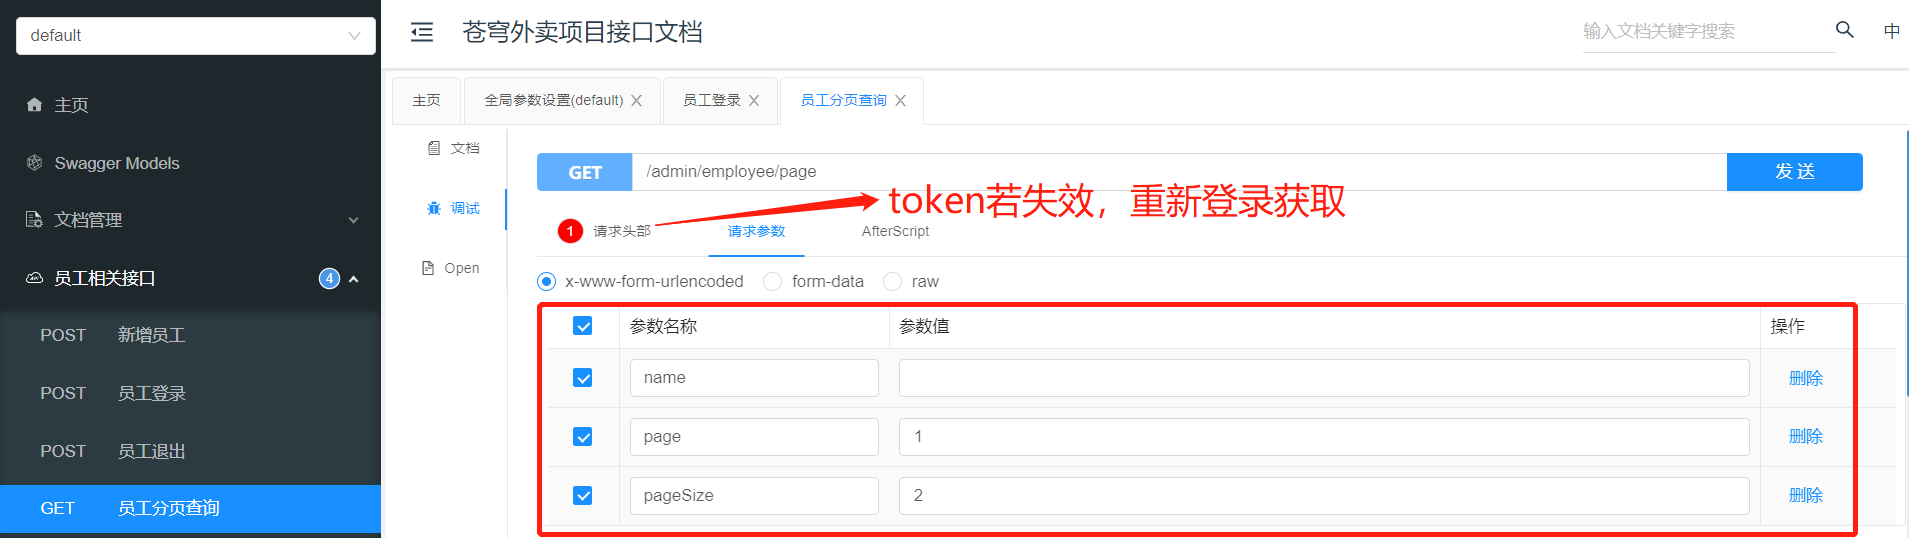 

**响应结果：**

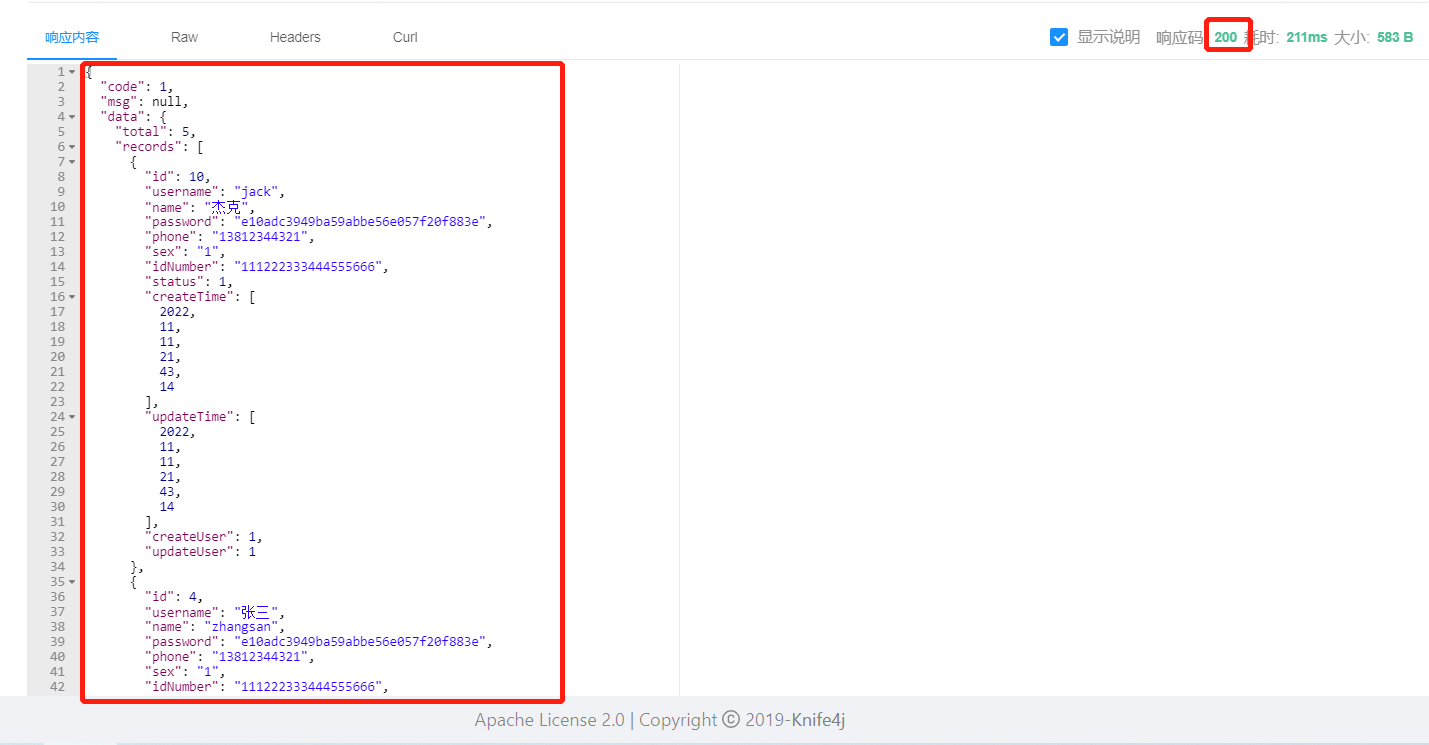 


#### 2.3.2 前后端联调测试

**点击员工管理**

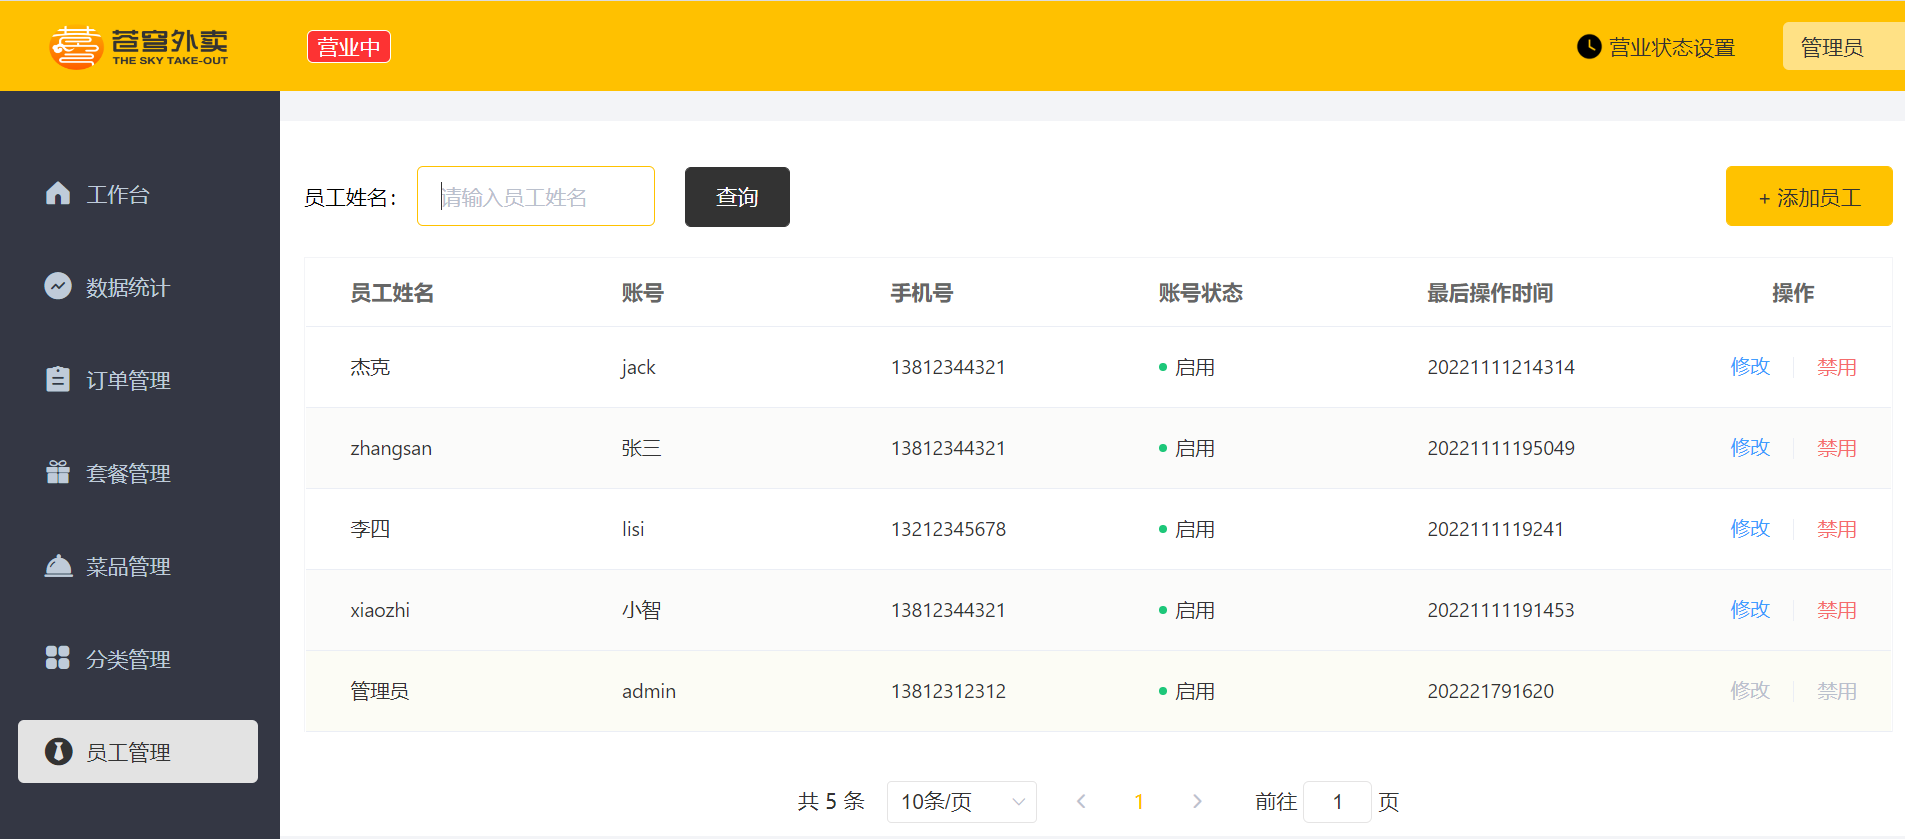  


**输入员工姓名为zhangsan**

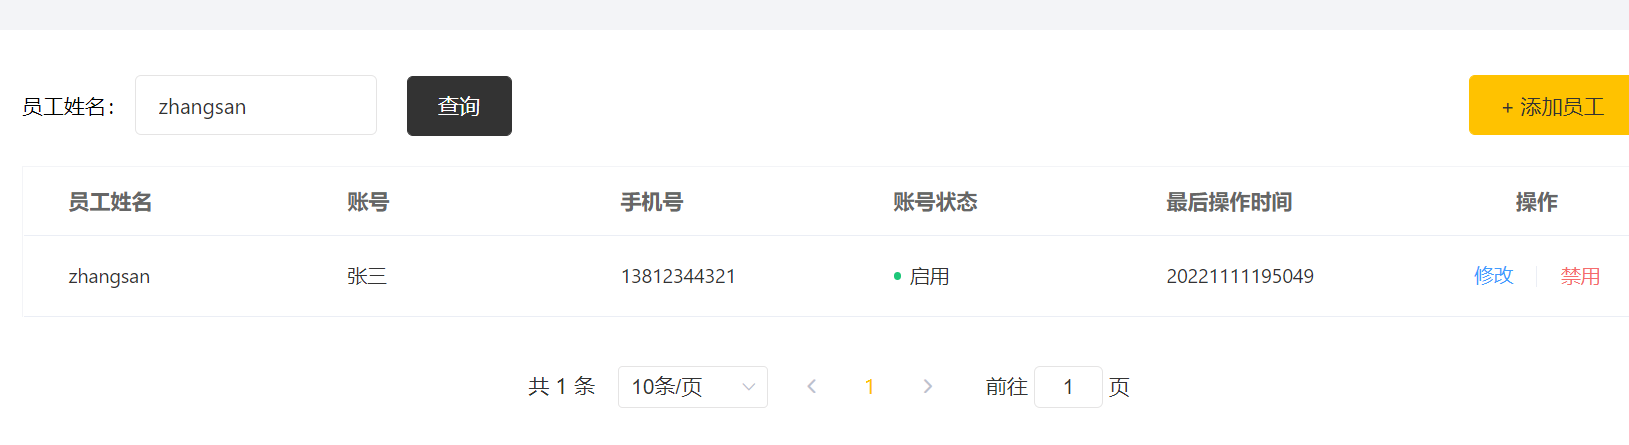 

不难发现，**最后操作时间格式**不清晰，在**代码完善**中解决。

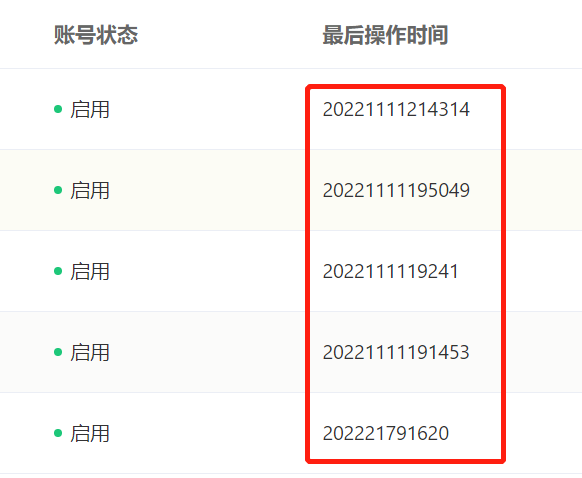


### 分页测试覆盖点（补充）

空姓名返回全部员工的分页结果；输入部分姓名验证筛选；第1页与第2页验证翻页；空结果验证 `total=0` 和空records；超出末页验证total保留但当前页为空。

页面显示“最后操作时间”异常时，先看实际响应JSON。数据库存储时间、Java日期对象、JSON格式、前端展示是四个不同环节，先定位再修改。


### 2.4 代码完善

> **PPT对照：** 第47—48页。

**问题描述：**操作时间字段显示有问题。

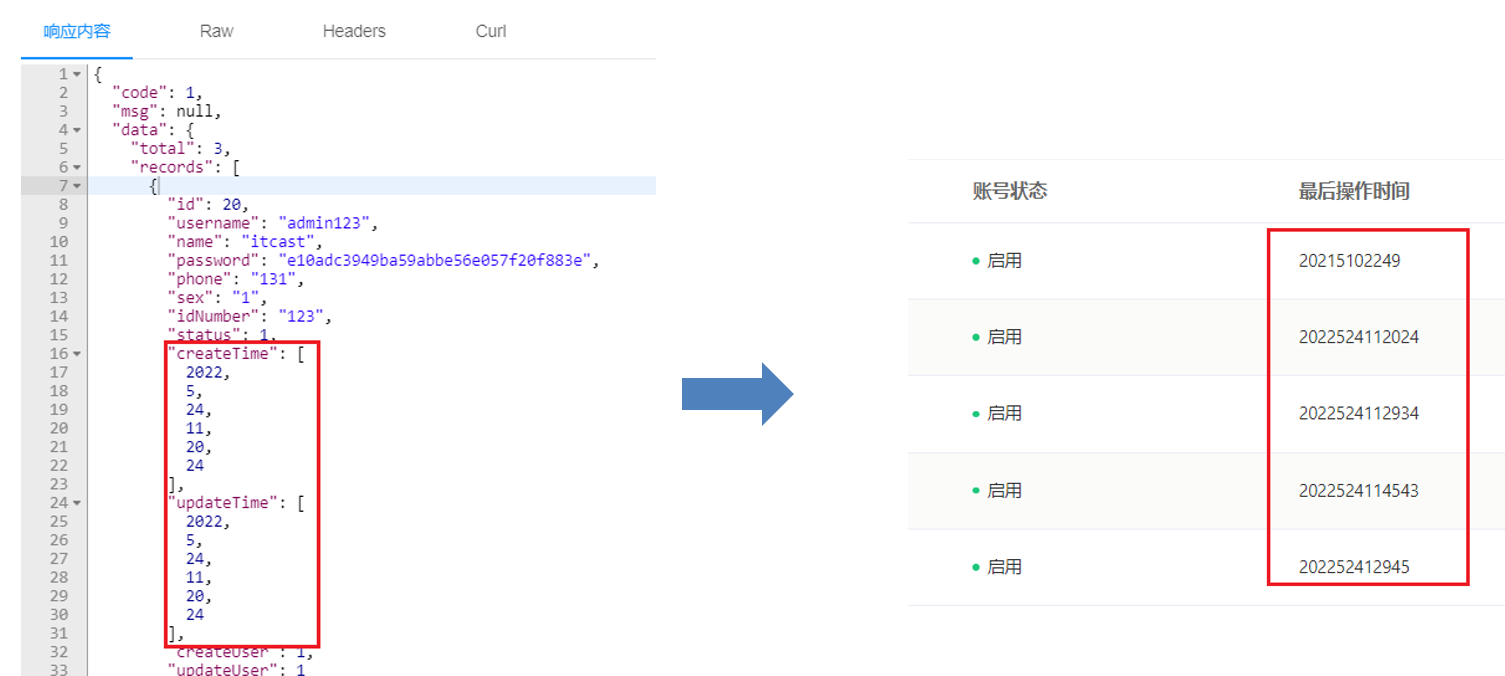 


**解决方式：**

**1).  方式一**

在属性上加上注解，对日期进行格式化

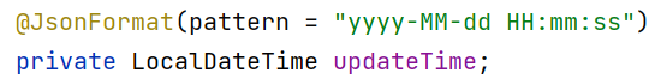 

但这种方式，需要在每个时间属性上都要加上该注解，使用较麻烦，不能全局处理。


**2).  方式二（推荐 )**

在WebMvcConfiguration中扩展SpringMVC的消息转换器，统一对日期类型进行格式处理

```java
	/**
     * 扩展Spring MVC框架的消息转化器
     * @param converters
     */
    protected void extendMessageConverters(List<HttpMessageConverter<?>> converters) {
        log.info("扩展消息转换器...");
        //创建一个消息转换器对象
        MappingJackson2HttpMessageConverter converter = new MappingJackson2HttpMessageConverter();
        //需要为消息转换器设置一个对象转换器，对象转换器可以将Java对象序列化为json数据
        converter.setObjectMapper(new JacksonObjectMapper());
        //将自己的消息转化器加入容器中
        converters.add(0,converter);
    }
```

添加后，再次测试

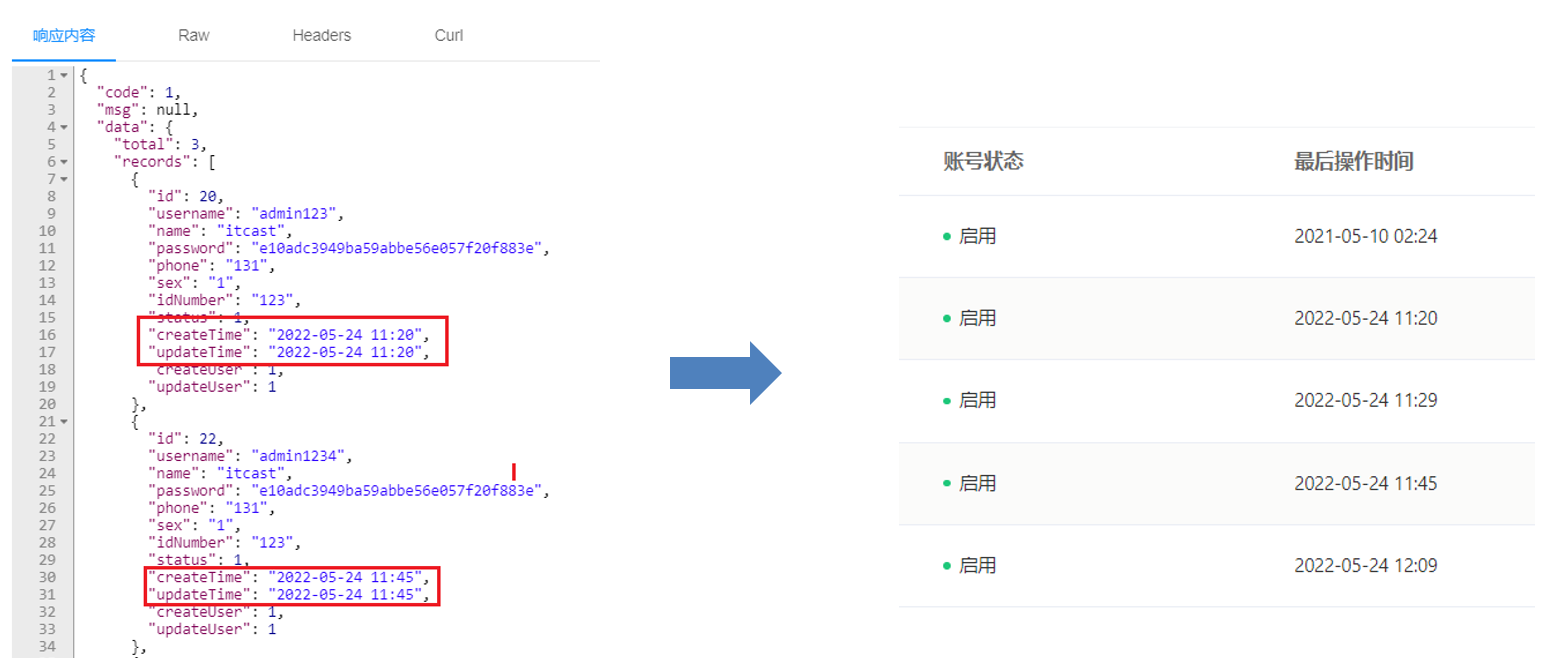 

时间格式定义，sky-common模块中

```java
package com.sky.json;

public class JacksonObjectMapper extends ObjectMapper {

	//.......
    public static final String DEFAULT_DATE_TIME_FORMAT = "yyyy-MM-dd HH:mm";
    //.......

    }
}
```


### 日期序列化与原文勘误（补充）

截图中的字段级示例是：

```java
@JsonFormat(pattern = "yyyy-MM-dd HH:mm:ss")
private LocalDateTime updateTime;
```

讲义 `JacksonObjectMapper` 片段的 `DEFAULT_DATE_TIME_FORMAT` 是 `yyyy-MM-dd HH:mm`，不含秒；两处格式不一致。按接口约定统一即可，不能认为加了转换器就必然采用带秒格式。该类片段还保留了省略号与不完整括号，只需阅读实际工程类并修改相关配置。

`MappingJackson2HttpMessageConverter`负责Java对象与JSON转换；`JacksonObjectMapper`负责具体序列化。将自定义转换器放在列表前端让它优先被选中。针对LocalDateTime要确认JavaTime相关模块和格式器已经注册，只有一个字符串常量不够。

格式化影响HTTP响应，不会修改数据库时间。LocalDateTime不含时区，跨时区系统还需另外约定时间含义。本章已有课程Mapper配置时复用它，并测试登录、分页等响应没有受到意外影响。


### 2.5 代码提交

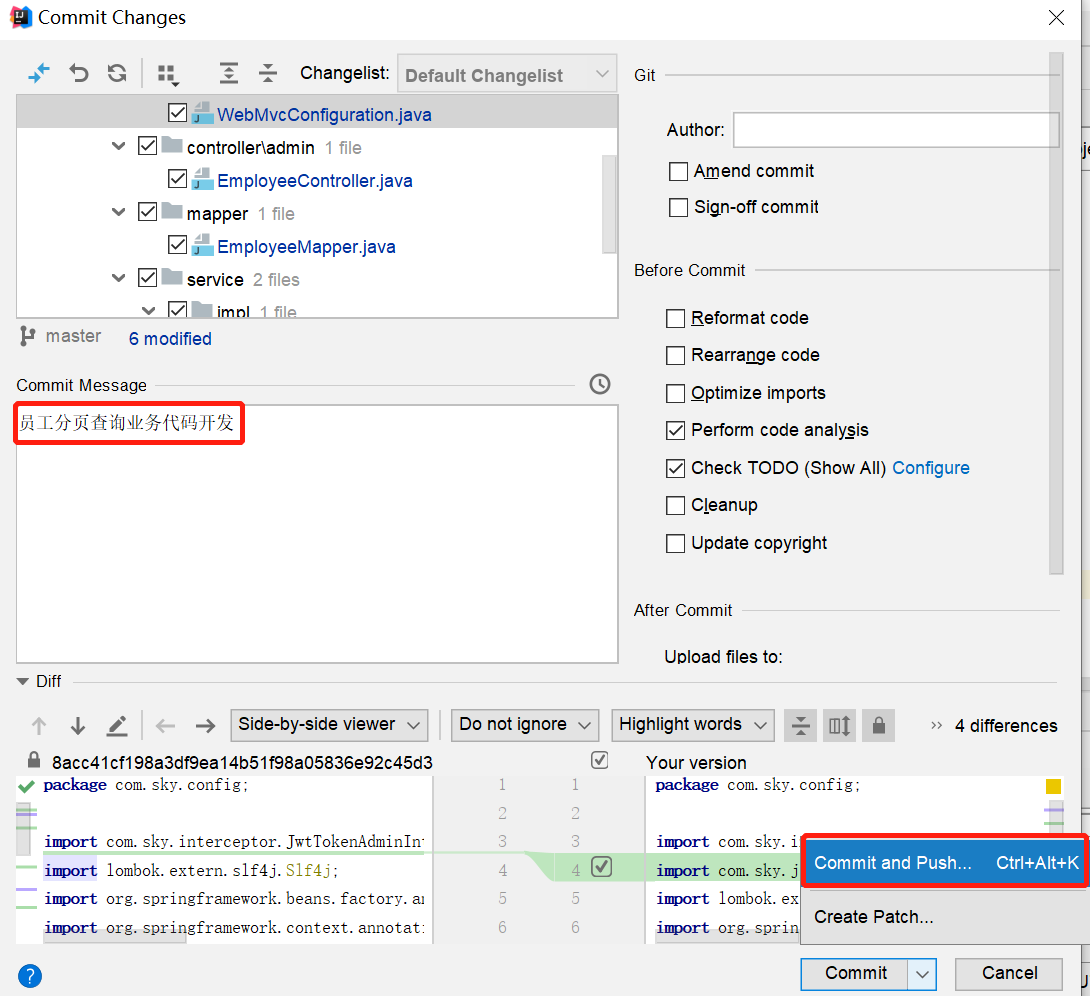 

后续步骤和新增员工代码提交一致，不再赘述。


## 3. 启用禁用员工账号

> **PPT对照：** 第50—61页。


### 3.1 需求分析与设计

> **PPT对照：** 第51—53页。

#### 3.1.1 产品原型

在员工管理列表页面，可以对某个员工账号进行启用或者禁用操作。账号禁用的员工不能登录系统，启用后的员工可以正常登录。如果某个员工账号状态为正常，则按钮显示为 "禁用"，如果员工账号状态为已禁用，则按钮显示为"启用"。

**启禁用员工原型：**

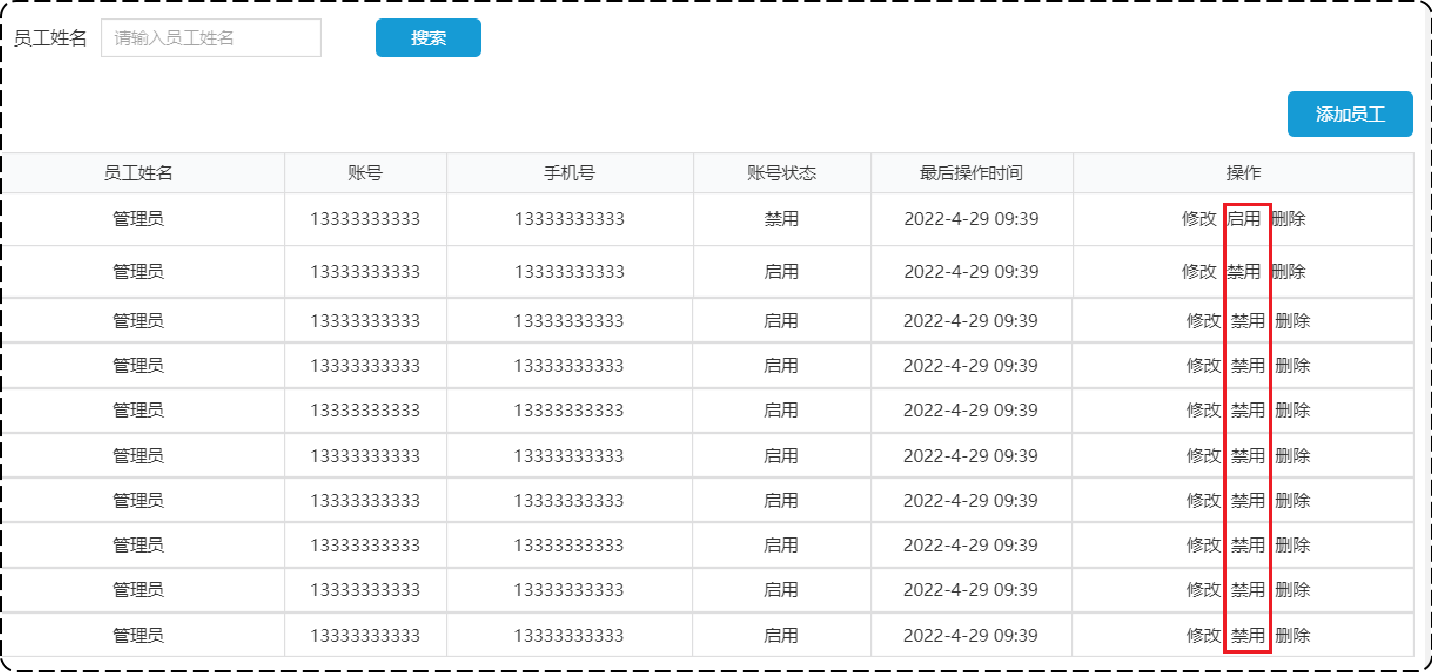 

**业务规则：**

- 可以对状态为“启用” 的员工账号进行“禁用”操作
- 可以对状态为“禁用”的员工账号进行“启用”操作
- 状态为“禁用”的员工账号不能登录系统


#### 3.1.2 接口设计

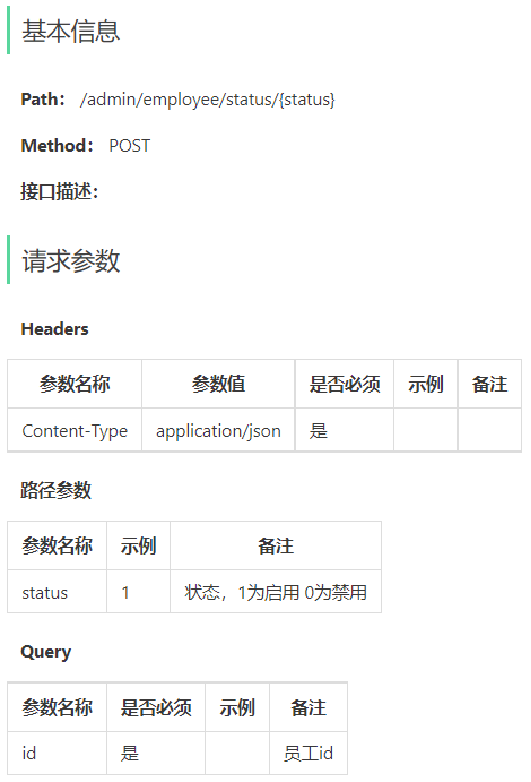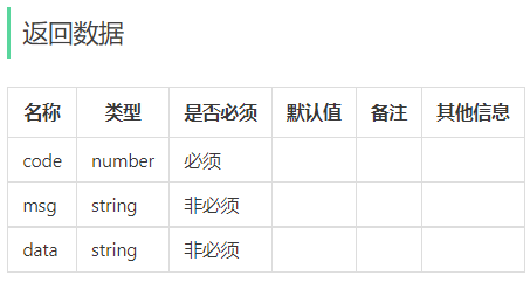


1). 路径参数携带状态值。

2). 同时，把id传递过去，明确对哪个用户进行操作。

3). 返回数据code状态是必须，其它是非必须。


### 状态切换与令牌边界（补充）

例如 `POST /admin/employee/status/0?id=4`：状态来自路径，目标员工id来自Query。`status=0`表示禁用，`status=1`表示启用；操作目标id和BaseContext中的当前操作者id是两个不同概念。

本章登录Service会检查员工状态，所以禁用账号不能再次登录。但已经签发的JWT不会因为修改数据库状态而自动失效。若业务要求立即停止已有会话，需要在认证时校验当前状态，或增加可撤销会话/令牌版本策略。


### 3.2 代码开发

> **PPT对照：** 第55—59页。

#### 3.2.1 Controller层

在sky-server模块中，根据接口设计中的请求参数形式对应的在 EmployeeController 中创建启用禁用员工账号的方法：

```java
	/**
     * 启用禁用员工账号
     * @param status
     * @param id
     * @return
     */
    @PostMapping("/status/{status}")
    @ApiOperation("启用禁用员工账号")
    public Result startOrStop(@PathVariable Integer status,Long id){
        log.info("启用禁用员工账号：{},{}",status,id);
        employeeService.startOrStop(status,id);//后绪步骤定义
        return Result.success();
    }
```


#### 3.2.2 Service层接口

在 EmployeeService 接口中声明启用禁用员工账号的业务方法：

```java
	/**
     * 启用禁用员工账号
     * @param status
     * @param id
     */
    void startOrStop(Integer status, Long id);
```


#### 3.2.3 Service层实现类

在 EmployeeServiceImpl 中实现启用禁用员工账号的业务方法：

```java
	/**
     * 启用禁用员工账号
     *
     * @param status
     * @param id
     */
    public void startOrStop(Integer status, Long id) {
        Employee employee = Employee.builder()
                .status(status)
                .id(id)
                .build();

        employeeMapper.update(employee);
    }
```


#### 3.2.4 Mapper层

在 EmployeeMapper 接口中声明 update 方法：

```java
	/**
     * 根据主键动态修改属性
     * @param employee
     */
    void update(Employee employee);
```

在 EmployeeMapper.xml 中编写SQL：

```sql
<update id="update" parameterType="Employee">
        update employee
        <set>
            <if test="name != null">name = #{name},</if>
            <if test="username != null">username = #{username},</if>
            <if test="password != null">password = #{password},</if>
            <if test="phone != null">phone = #{phone},</if>
            <if test="sex != null">sex = #{sex},</if>
            <if test="idNumber != null">id_Number = #{idNumber},</if>
            <if test="updateTime != null">update_Time = #{updateTime},</if>
            <if test="updateUser != null">update_User = #{updateUser},</if>
            <if test="status != null">status = #{status},</if>
        </set>
        where id = #{id}
    </update>
```


### 动态UPDATE的边界（补充）

`Employee.builder().id(id).status(status).build()`只设置待修改字段，Mapper `<set>`只拼接非null属性，并去掉多余逗号。null表示“不更新”，不能靠这一写法把数据库字段清空为NULL。

`status=0`是有效值，应判断 `status != null`，不要把0当作“没传”。在Controller可显式写 `@RequestParam("id") Long id`，同时校验id与状态范围；`where id = #{id}`必须保留。

课程启禁用实现没有设置updateTime/updateUser。可在Service补充：

```java
Employee employee = Employee.builder()
        .id(id)
        .status(status)
        .updateTime(LocalDateTime.now())
        .updateUser(BaseContext.getCurrentId())
        .build();
employeeMapper.update(employee);
```

实际项目应校验目标存在、是否有权限，以及是否允许操作自己或受保护管理员。原Mapper返回void，无法判断更新影响的行数；若要求不存在的id必须报错，应修改返回值为int或提前检查，不能仅返回成功。


### 3.3 功能测试

> **PPT对照：** 第61页。

#### 3.3.1 接口文档测试

**测试前，**查询employee表中员工账号状态

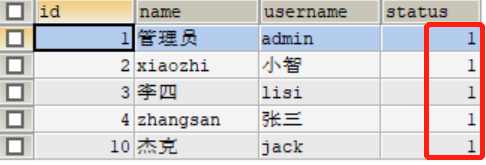 

**开始测试**

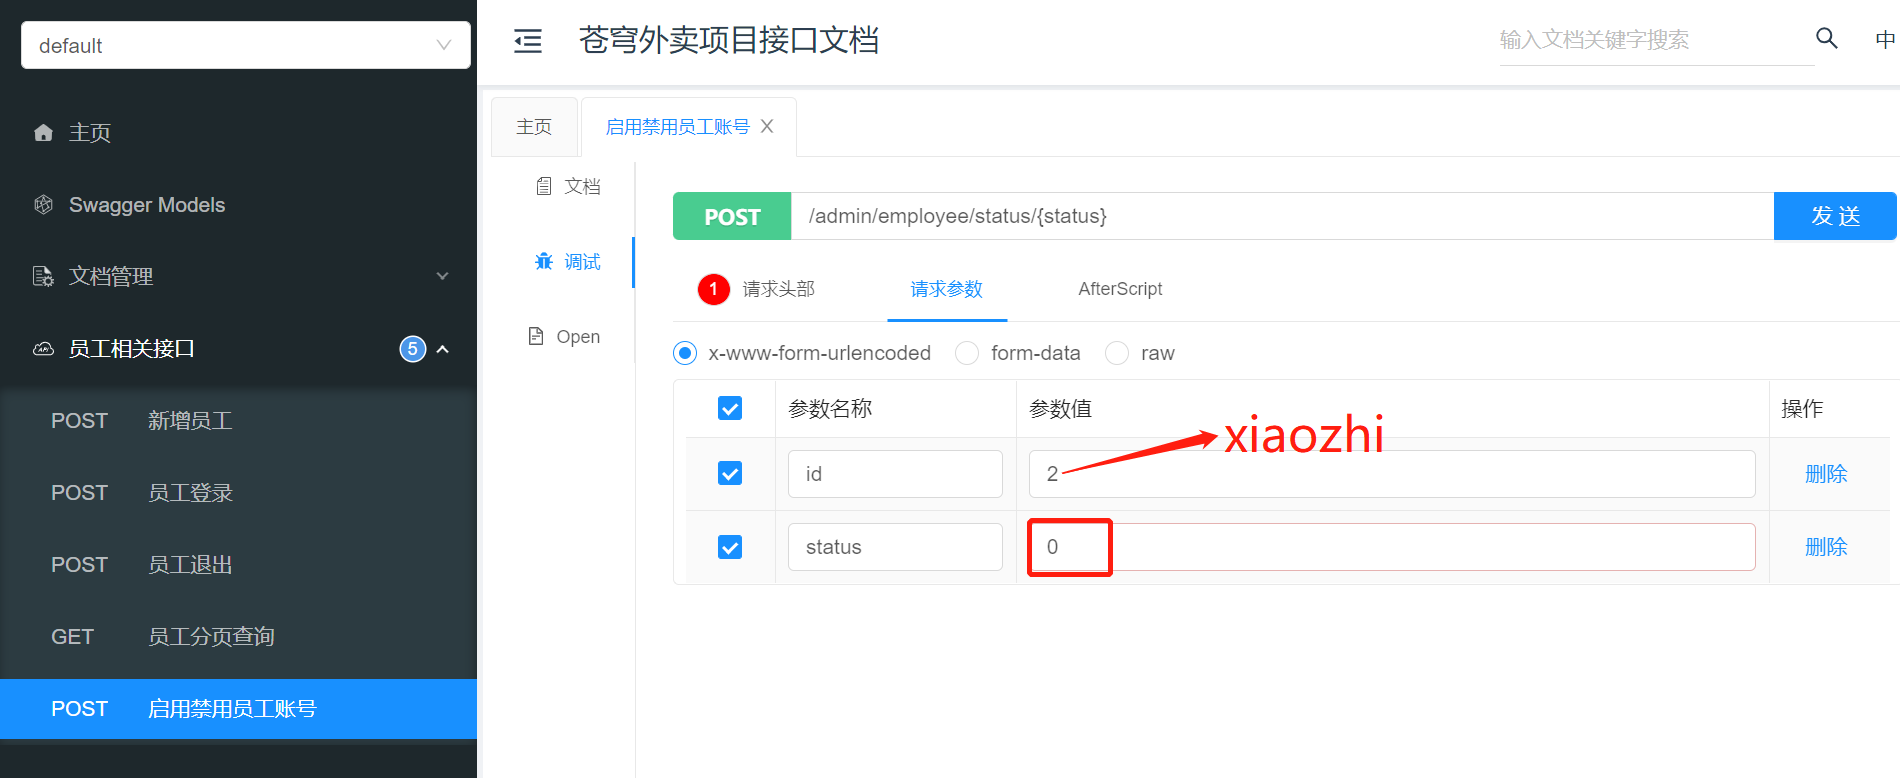 

**测试完毕后**，再次查询员工账号状态

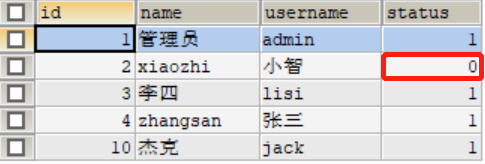 


#### 3.3.2 前后端联调测试

**测试前：**

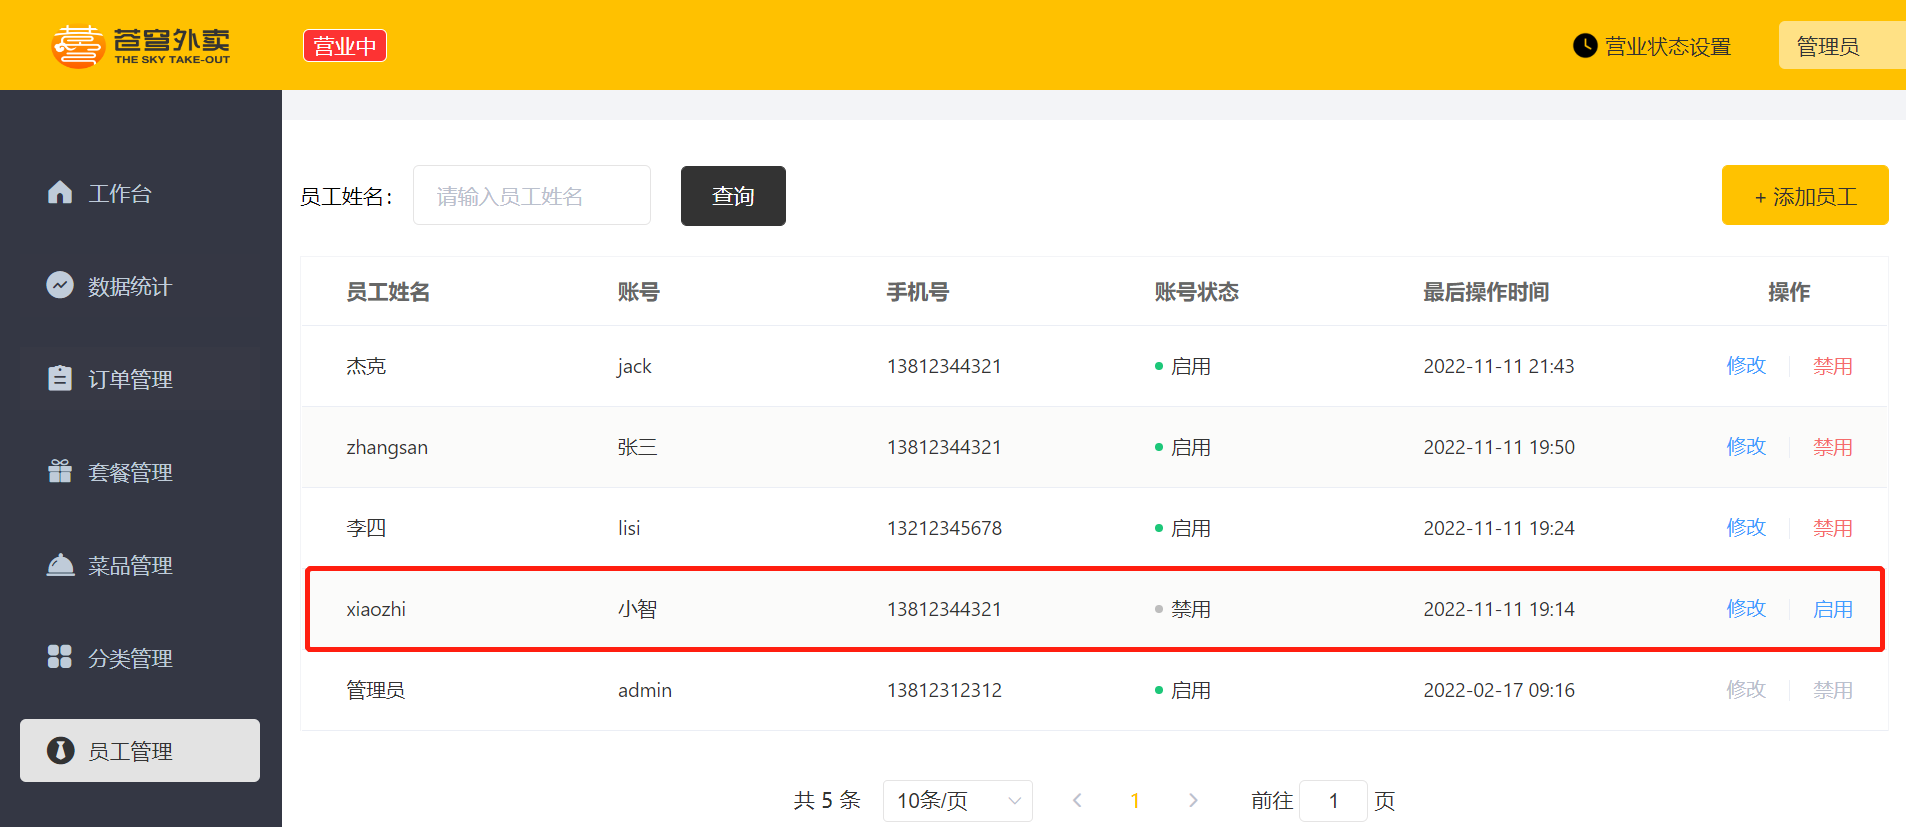 

**点击启用:**

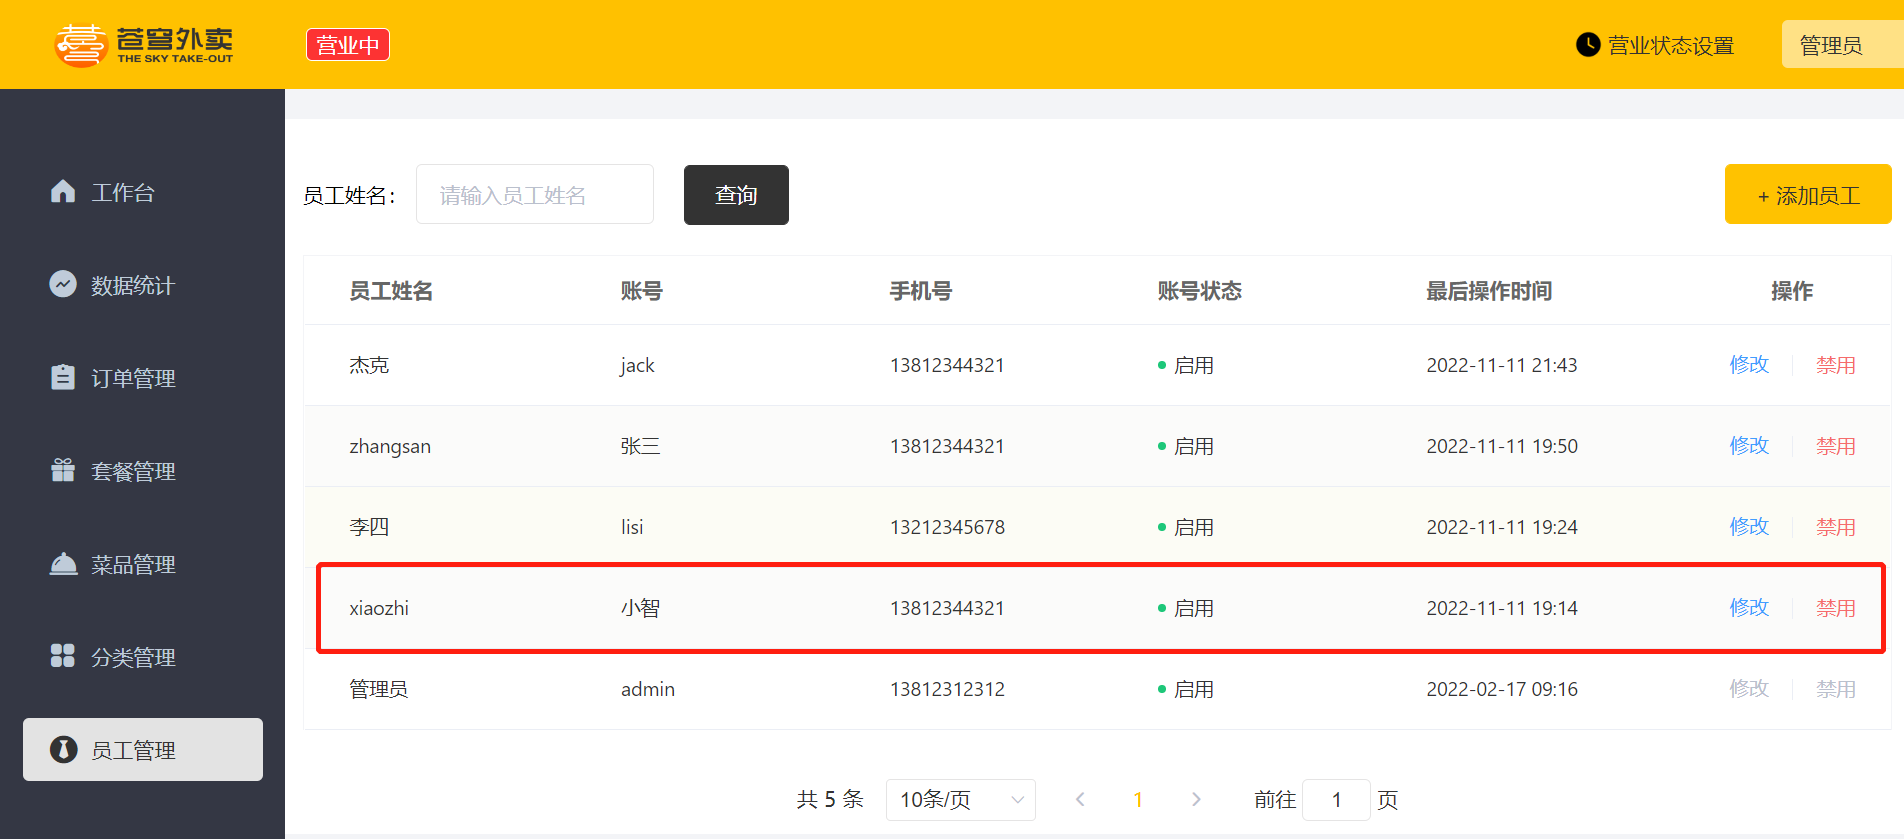


### 启禁用验收（补充）

测试启用到禁用、禁用到启用；分别核对数据库status、页面按钮文字和新登录结果。还要测试非法状态、缺少id、不存在id及无权限操作，避免只验证按钮变色。使用当前测试数据库实际存在的id，不照搬截图中的id。


### 3.4 代码提交

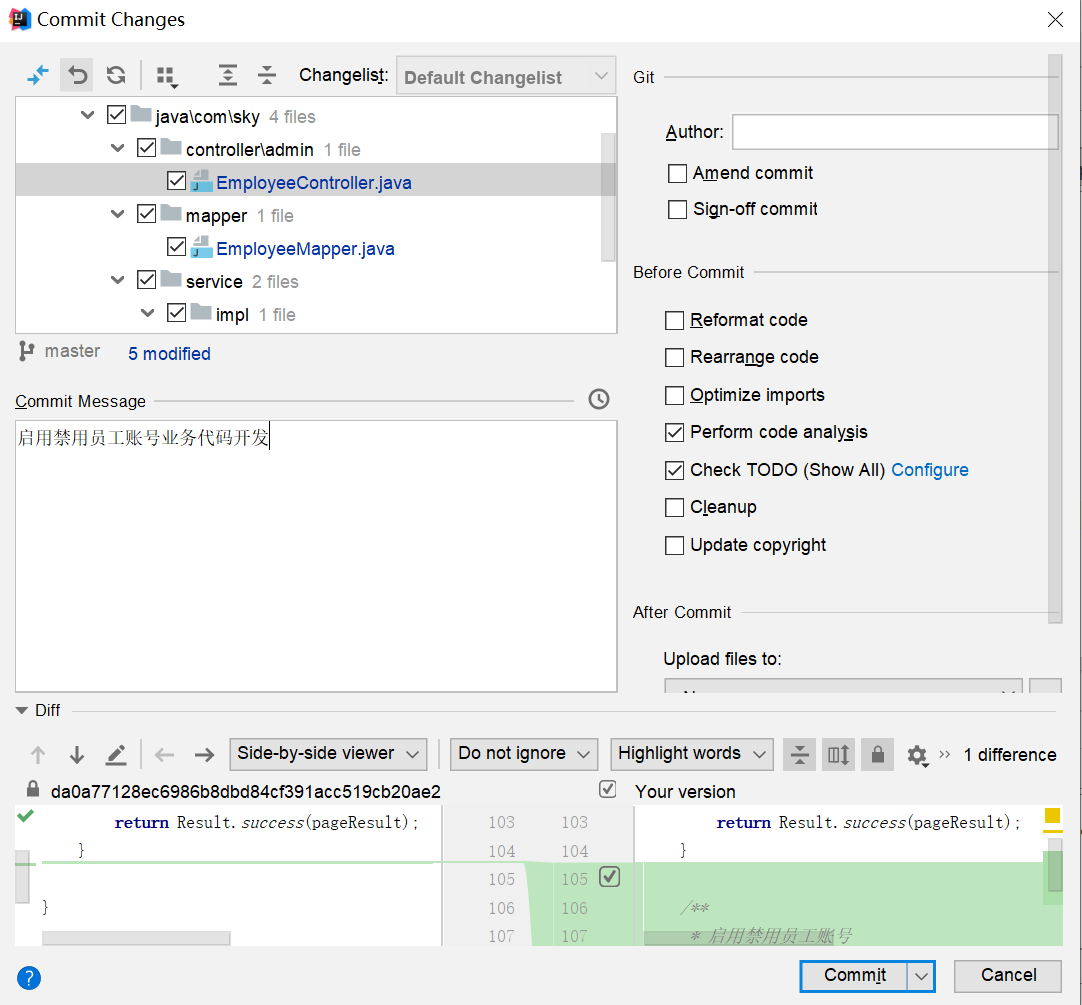 

后续步骤和上述功能代码提交一致，不再赘述。


## 4. 编辑员工

> **PPT对照：** 第63—75页。


### 4.1 需求分析与设计

> **PPT对照：** 第64—65页。

#### 4.1.1 产品原型

在员工管理列表页面点击 "编辑" 按钮，跳转到编辑页面，在编辑页面回显员工信息并进行修改，最后点击 "保存" 按钮完成编辑操作。

**员工列表原型：**

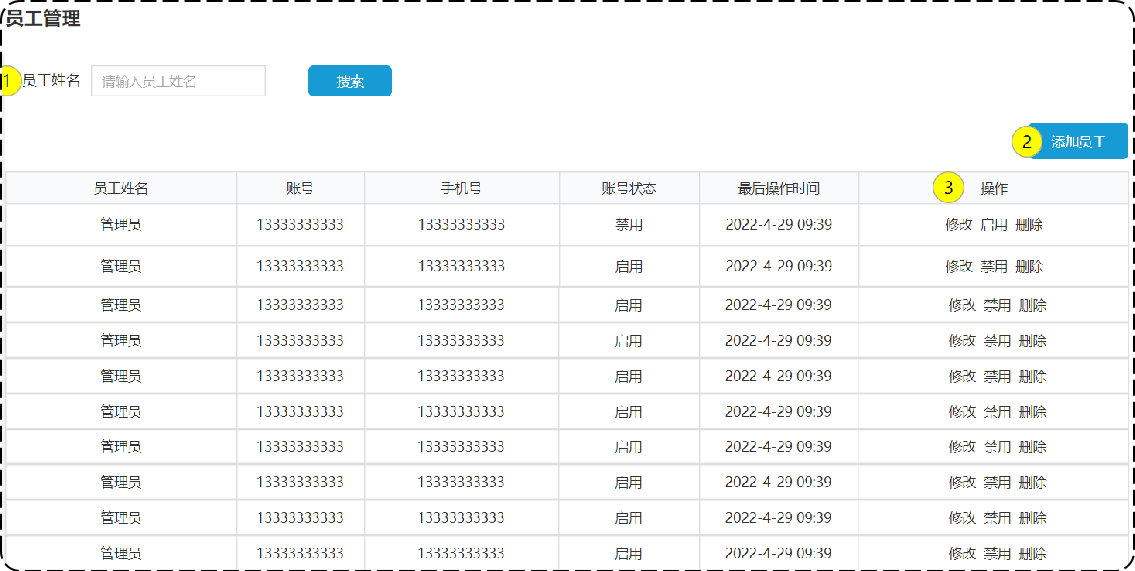 

**修改页面原型**：

注：点击修改时，数据应该正常回显到修改页面。

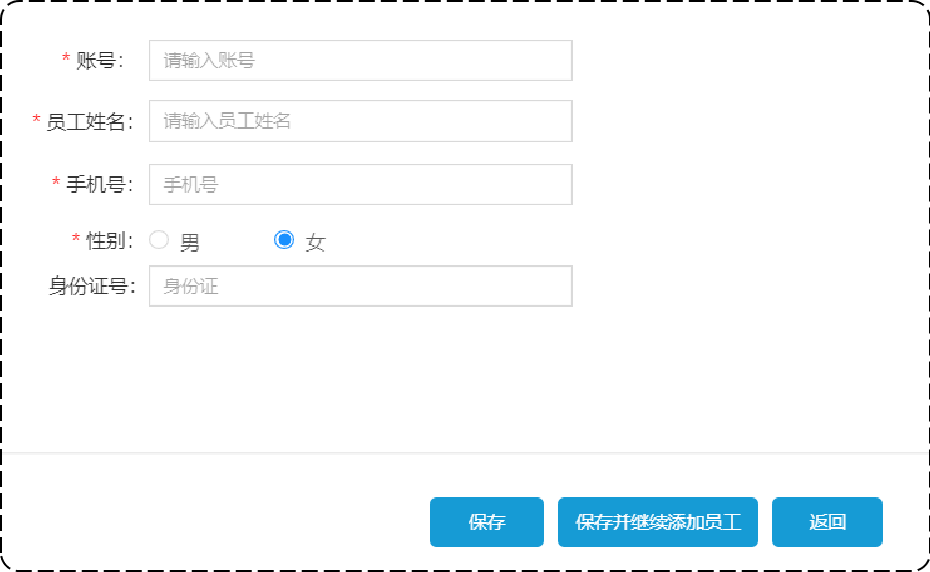 


#### 4.1.2 接口设计

根据上述原型图分析，编辑员工功能涉及到两个接口：

- 根据id查询员工信息
- 编辑员工信息

**1). 根据id查询员工信息**

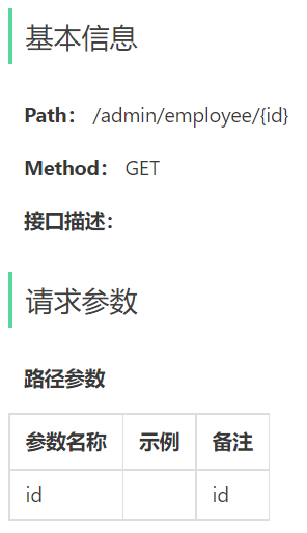 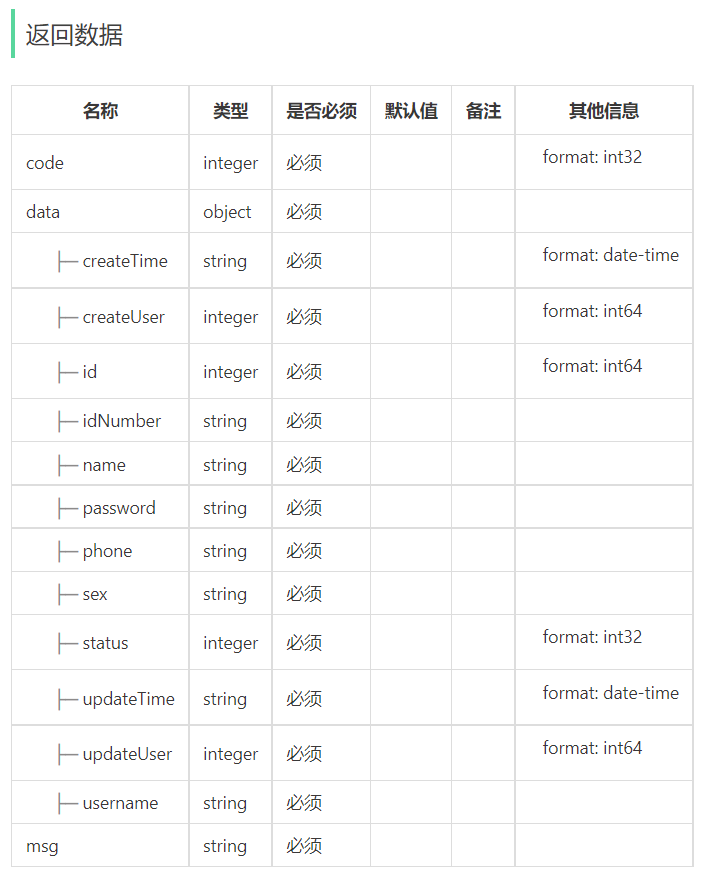


**2). 编辑员工信息**

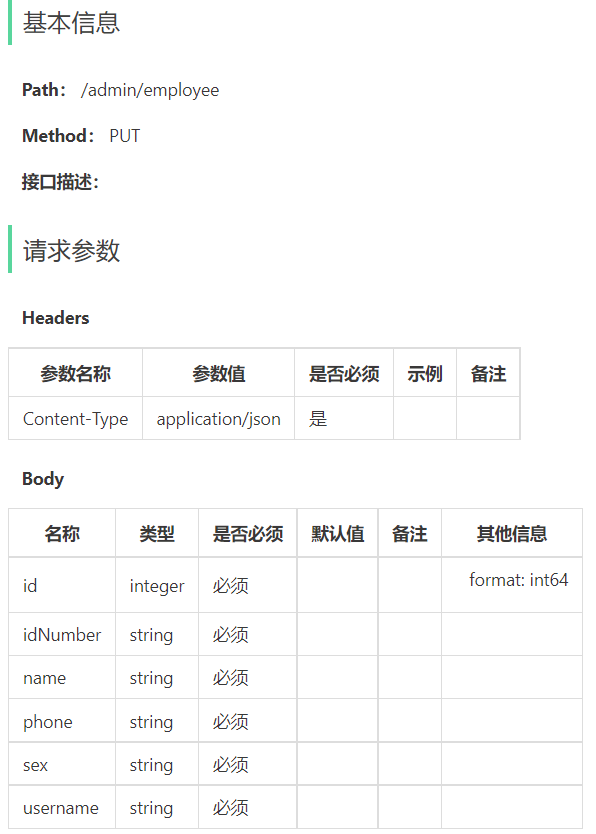 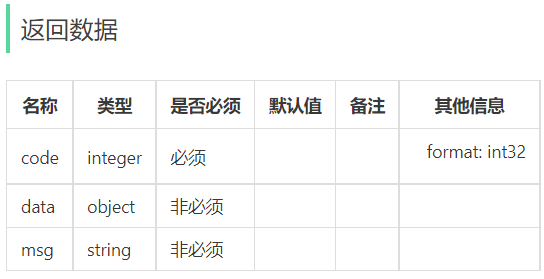

**注:因为是修改功能，请求方式可设置为PUT。**


### 编辑拆成回显与保存（补充）

先 `GET /admin/employee/{id}` 取原记录，填入表单；保存时 `PUT /admin/employee` 提交包含id的JSON。回显接口与保存接口的用途不同，不能点击编辑就直接更新。

EmployeeDTO没有password、status和创建审计字段，普通编辑不应顺带重置密码、修改账号状态或覆盖创建信息。


### 4.2 代码开发

> **PPT对照：** 第67—73页。

#### 4.2.1 回显员工信息功能

**1). Controller层**

在 EmployeeController 中创建 getById 方法：

```java
	/**
     * 根据id查询员工信息
     * @param id
     * @return
     */
    @GetMapping("/{id}")
    @ApiOperation("根据id查询员工信息")
    public Result<Employee> getById(@PathVariable Long id){
        Employee employee = employeeService.getById(id);
        return Result.success(employee);
    }
```


**2). Service层接口**

在 EmployeeService 接口中声明 getById 方法：

```java
    /**
     * 根据id查询员工
     * @param id
     * @return
     */
    Employee getById(Long id);
```


**3). Service层实现类**

在 EmployeeServiceImpl 中实现 getById 方法：

```java
 	/**
     * 根据id查询员工
     *
     * @param id
     * @return
     */
    public Employee getById(Long id) {
        Employee employee = employeeMapper.getById(id);
        employee.setPassword("****");
        return employee;
    }
```


**4). Mapper层**

在 EmployeeMapper 接口中声明 getById 方法：

```java
	/**
     * 根据id查询员工信息
     * @param id
     * @return
     */
    @Select("select * from employee where id = #{id}")
    Employee getById(Long id);
```


#### 4.2.2 修改员工信息功能

**1). Controller层**

在 EmployeeController 中创建 update 方法：

```java
	/**
     * 编辑员工信息
     * @param employeeDTO
     * @return
     */
    @PutMapping
    @ApiOperation("编辑员工信息")
    public Result update(@RequestBody EmployeeDTO employeeDTO){
        log.info("编辑员工信息：{}", employeeDTO);
        employeeService.update(employeeDTO);
        return Result.success();
    }
```


**2). Service层接口**

在 EmployeeService 接口中声明 update 方法：

```java
    /**
     * 编辑员工信息
     * @param employeeDTO
     */
    void update(EmployeeDTO employeeDTO);
```


**3). Service层实现类**

在 EmployeeServiceImpl 中实现 update 方法：

```java
 	/**
     * 编辑员工信息
     *
     * @param employeeDTO
     */
    public void update(EmployeeDTO employeeDTO) {
        Employee employee = new Employee();
        BeanUtils.copyProperties(employeeDTO, employee);

        employee.setUpdateTime(LocalDateTime.now());
        employee.setUpdateUser(BaseContext.getCurrentId());

        employeeMapper.update(employee);
    }
```

在实现**启用禁用员工账号**功能时，已实现employeeMapper.update(employee)，在此不需写Mapper层代码。


### 回显与更新的补充检查

`employeeMapper.getById(id)` 在记录不存在时可能返回null，原文紧接着 `employee.setPassword("****")` 会发生空指针异常。应先判空并按现有业务异常约定返回错误。

`"****"`仅是显示占位，不是数据库密码，也不应在编辑后写回password。更清晰的方案是使用不包含password的回显VO，避免返回整个实体。

更新时从EmployeeDTO复制可修改字段，设置updateTime和当前操作人；复用之前的动态update。username变更仍受唯一约束；id必填，空对象、空姓名、超长字段等也需要校验。注意 `BeanUtils.copyProperties`会复制null，最终是否忽略取决于Mapper条件。


### 4.3 功能测试

> **PPT对照：** 第75页。

#### 4.3.1 接口文档测试

分别测试**根据id查询员工信息**和**编辑员工信息**两个接口

**1). 根据id查询员工信息**

查询employee表中的数据，以id=4的记录为例

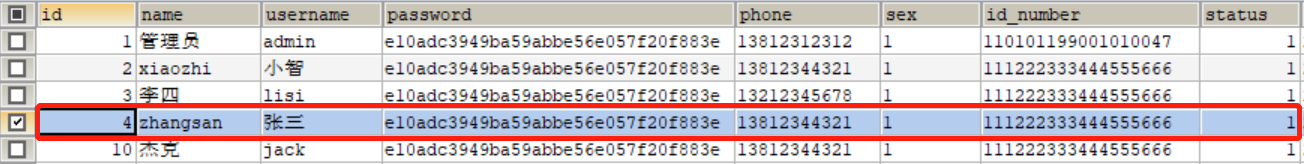

开始测试

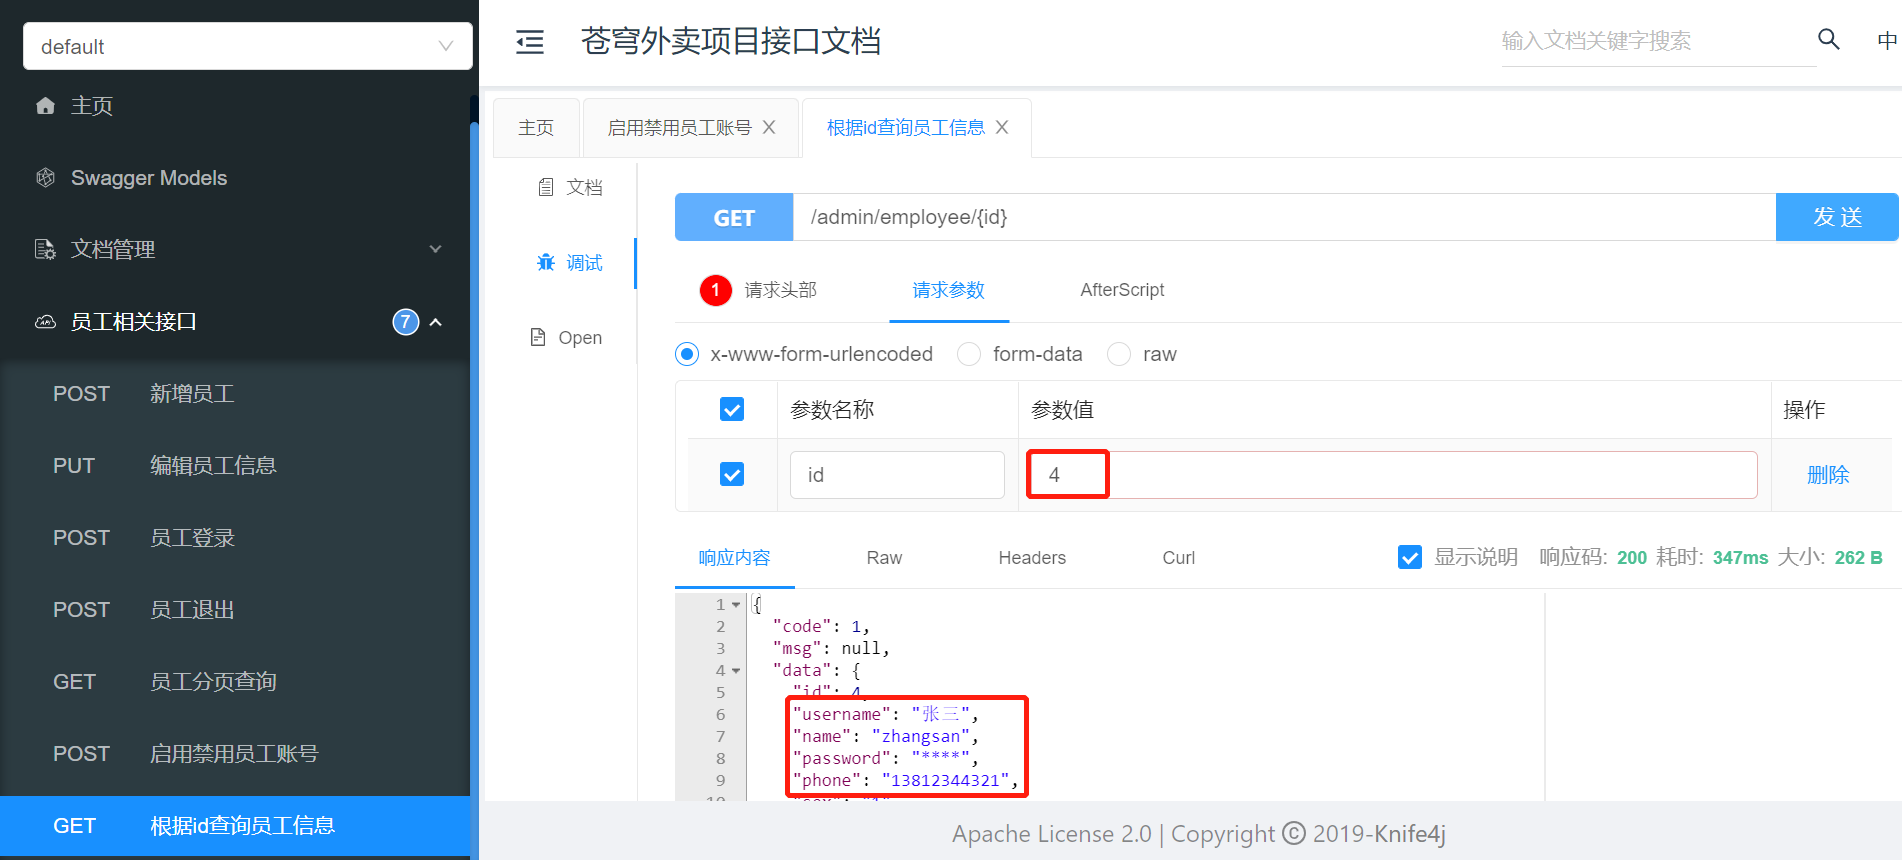 

获取到了id=4的相关员工信息

**2). 编辑员工信息**

修改id=4的员工信息，**name**由**zhangsan**改为**张三丰**，**username**由**张三**改为**zhangsanfeng**。

 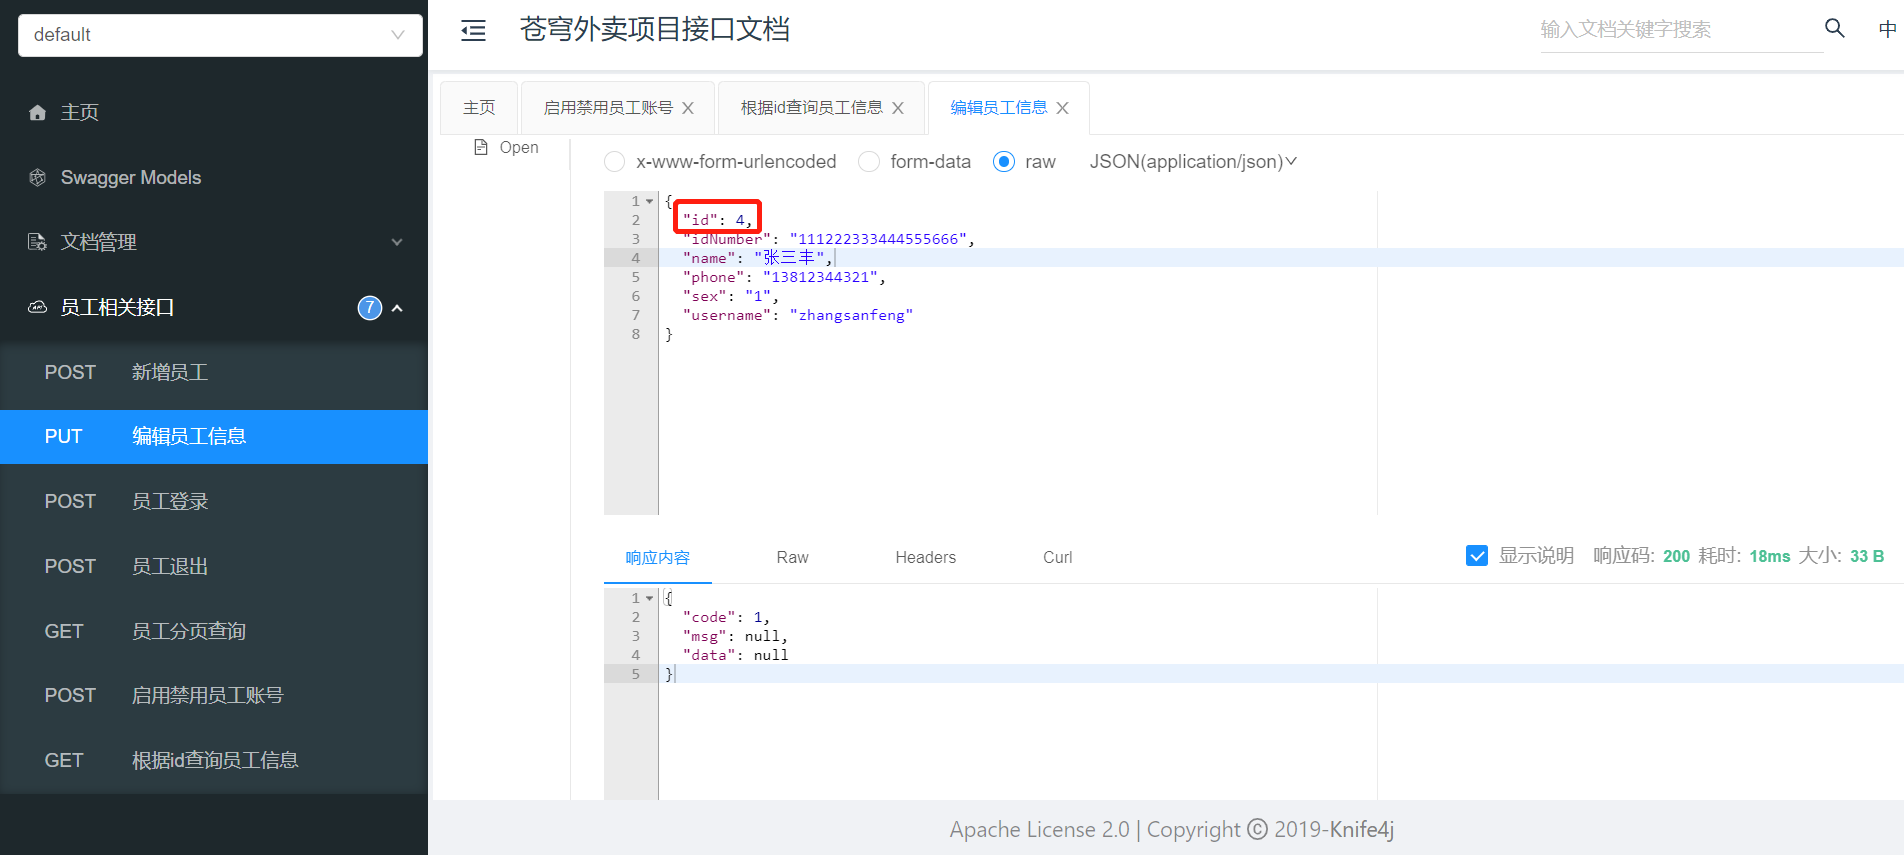 

查看employee表数据

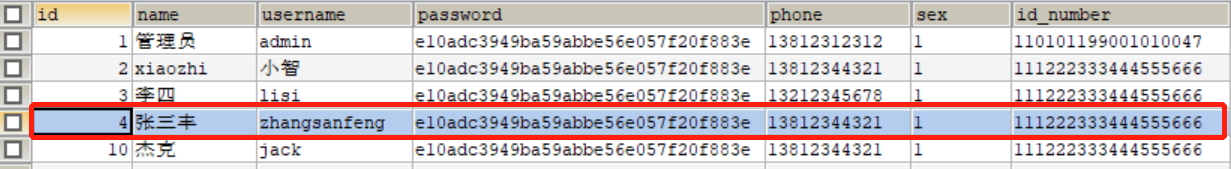


#### 4.3.2 前后端联调测试

进入到员工列表查询

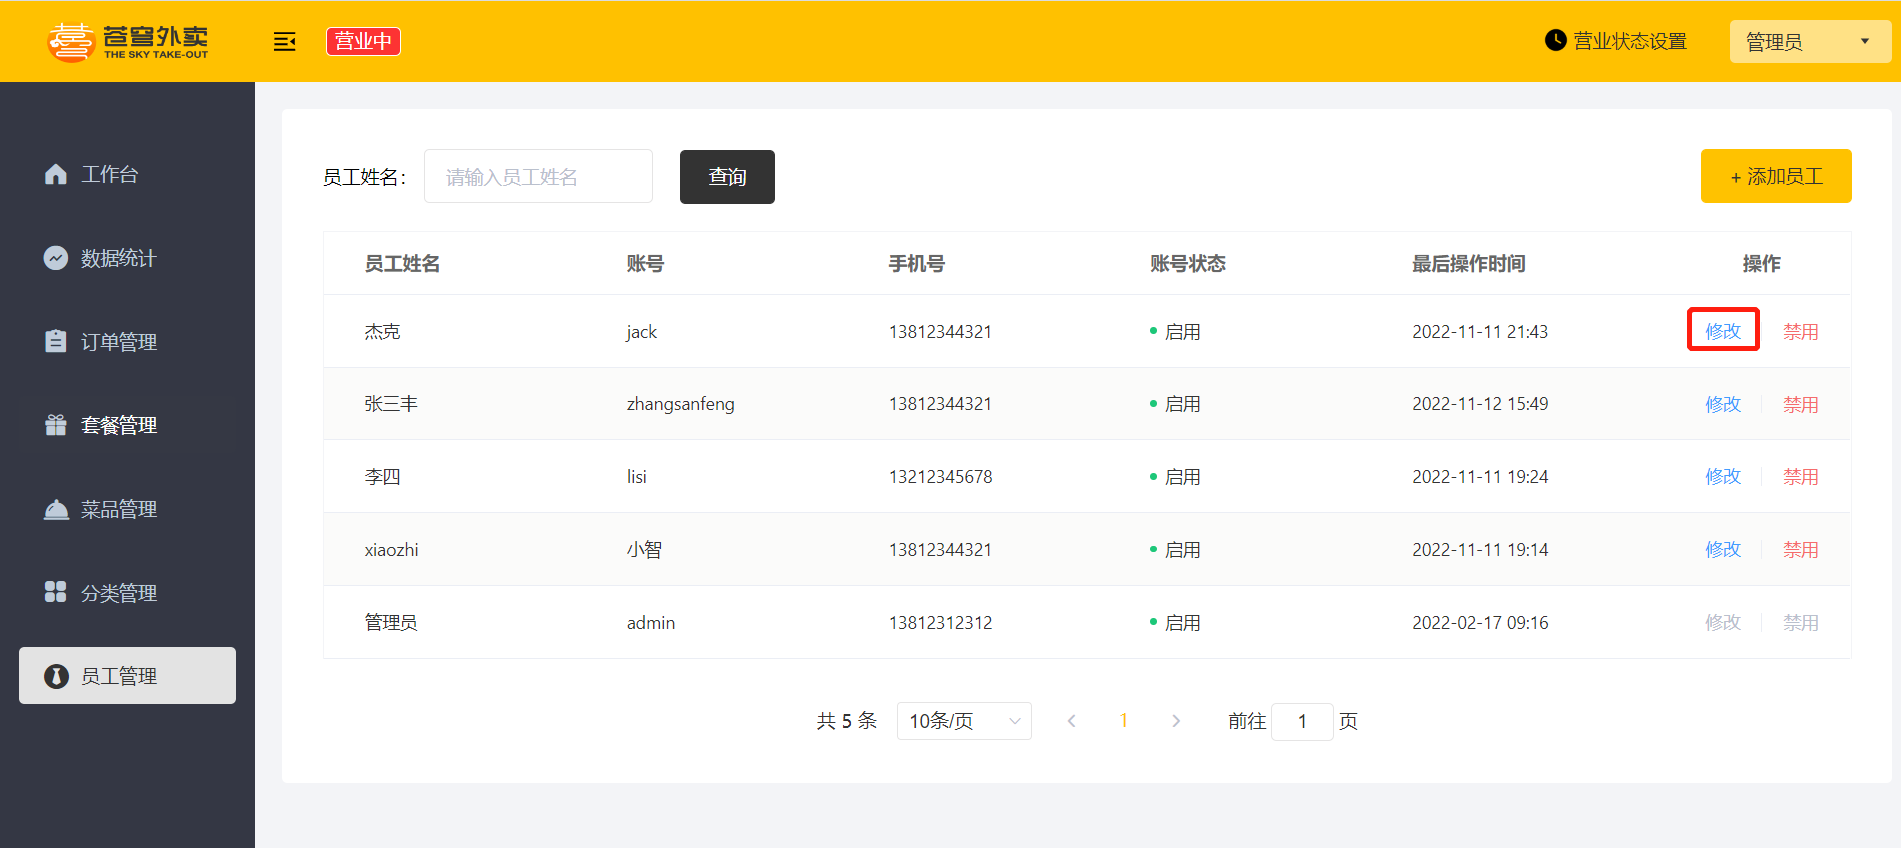 

对员工姓名为杰克的员工数据修改，点击修改，数据已回显

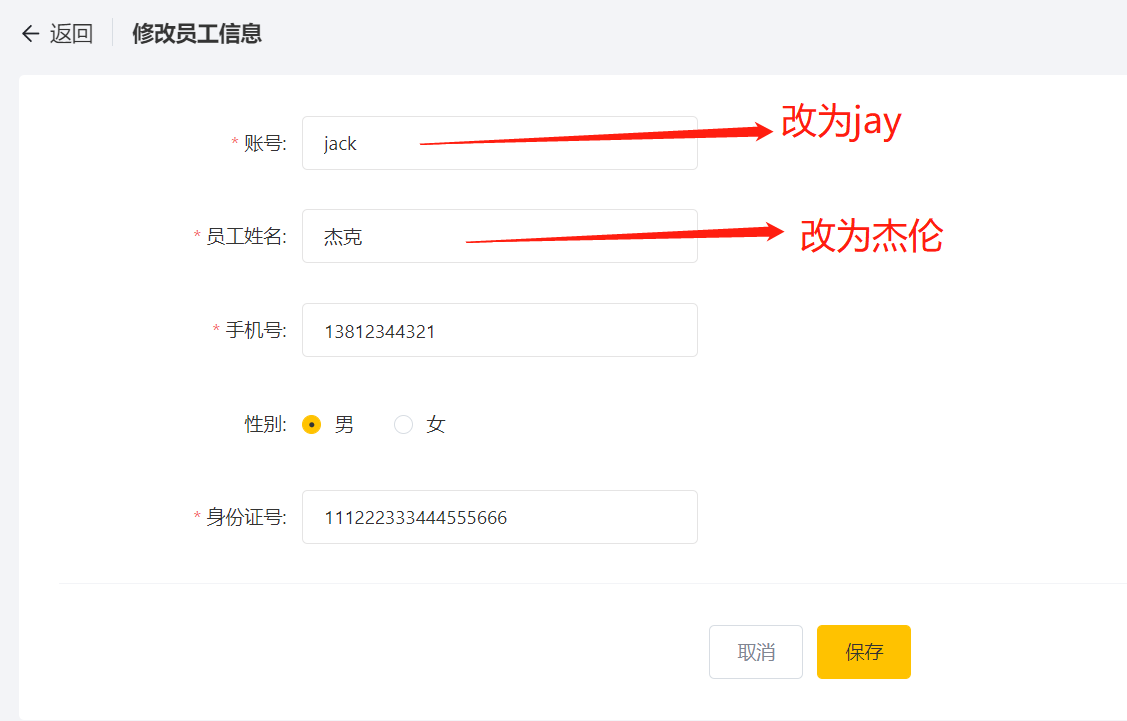 

修改后，点击保存

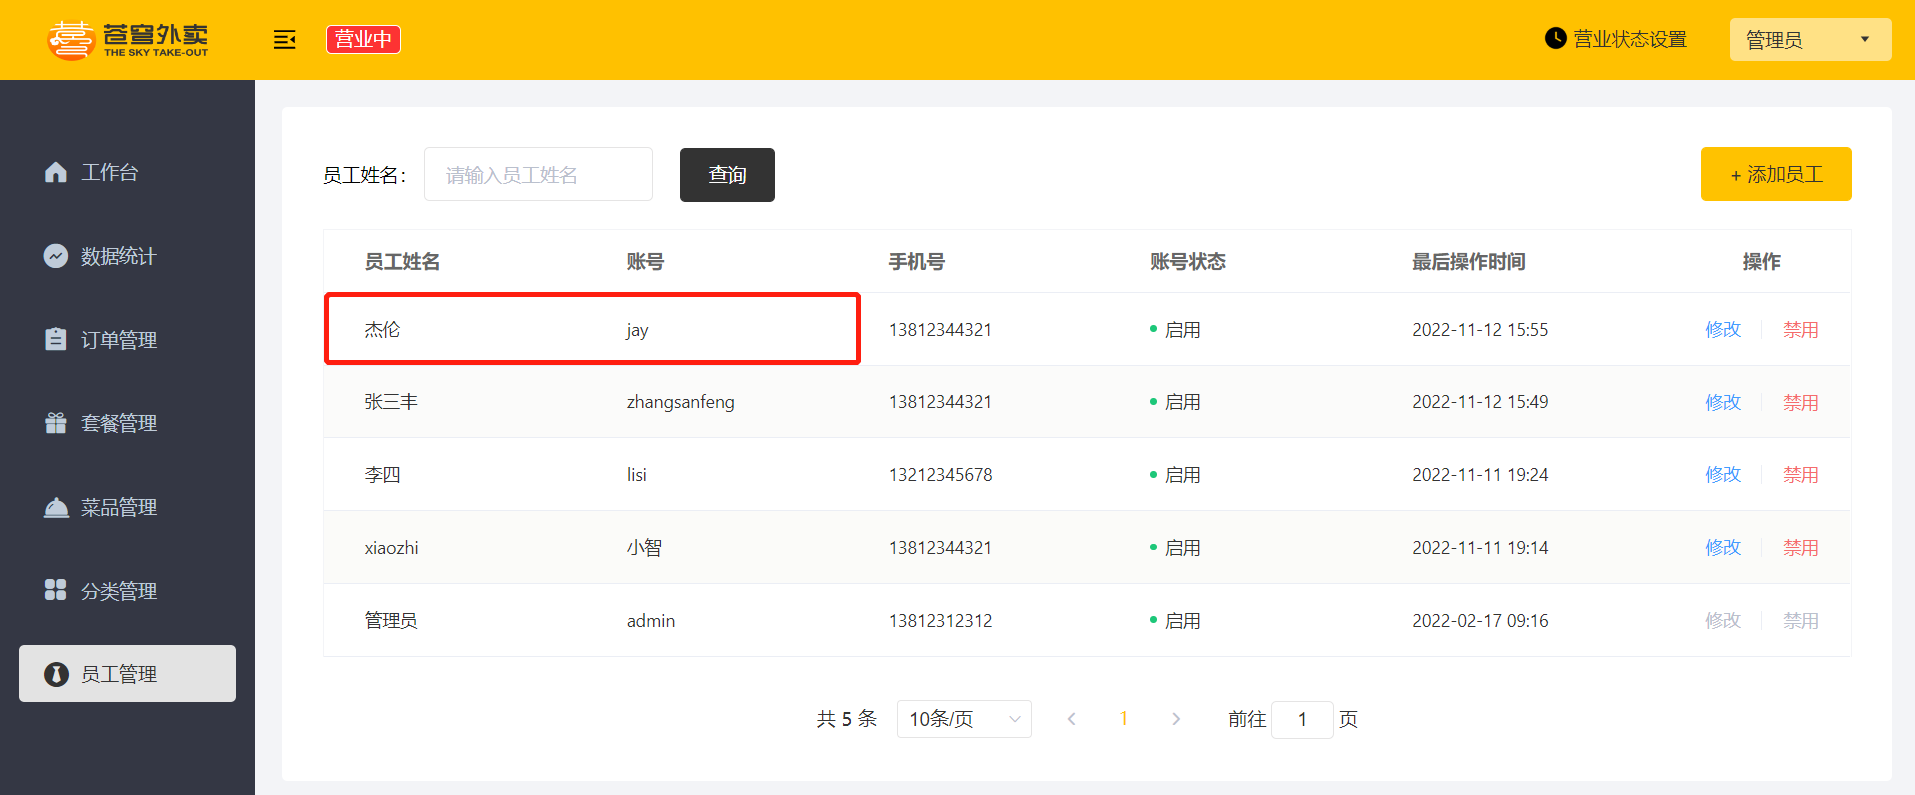


### 编辑后核对哪些字段（补充）

查询现有员工，修改一个普通字段，再重新回显，确认更新成功。核对createTime/createUser保持不变，updateTime/updateUser发生变化，password和status没有被普通编辑改动。

重复用户名应得到业务错误；不存在的id应按接口约定处理；真实身份证号和手机号不要填入共享截图或日志。


### 4.4 代码提交

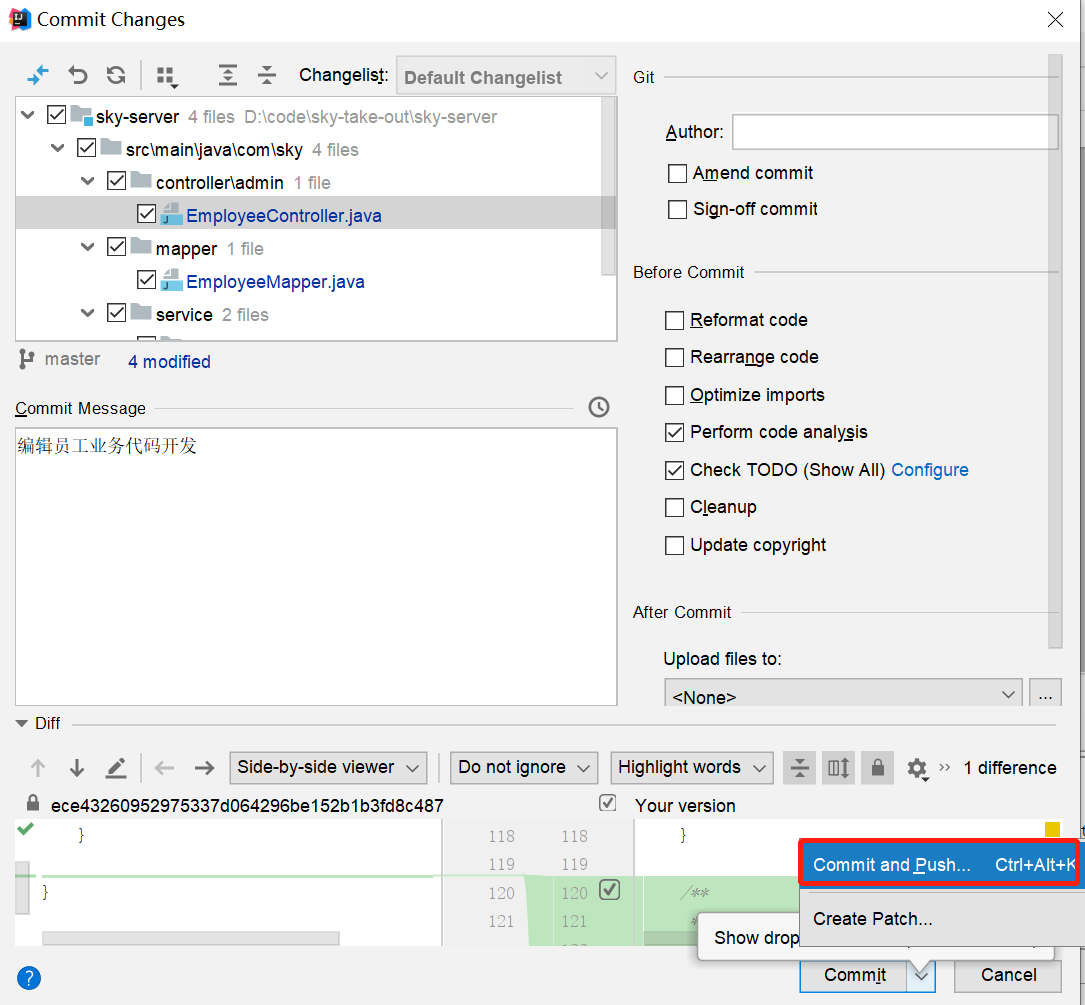 

后续步骤和上述功能代码提交一致，不再赘述。


## 5. 导入分类模块功能代码

> **PPT对照：** 第77—85页。


### 5.1 需求分析与设计

> **PPT对照：** 第78—81页。

#### 5.1.1 产品原型

后台系统中可以管理分类信息，分类包括两种类型，分别是 **菜品分类** 和 **套餐分类** 。

先来分析**菜品分类**相关功能。

**新增菜品分类：**当我们在后台系统中添加菜品时需要选择一个菜品分类，在移动端也会按照菜品分类来展示对应的菜品。

**菜品分类分页查询：**系统中的分类很多的时候，如果在一个页面中全部展示出来会显得比较乱，不便于查看，所以一般的系统中都会以分页的方式来展示列表数据。

**根据id删除菜品分类：**在分类管理列表页面，可以对某个分类进行删除操作。需要注意的是当分类关联了菜品或者套餐时，此分类不允许删除。

**修改菜品分类：**在分类管理列表页面点击修改按钮，弹出修改窗口，在修改窗口回显分类信息并进行修改，最后点击确定按钮完成修改操作。

**启用禁用菜品分类：**在分类管理列表页面，可以对某个分类进行启用或者禁用操作。

**分类类型查询：**当点击分类类型下拉框时，从数据库中查询所有的菜品分类数据进行展示。


**分类管理原型：**

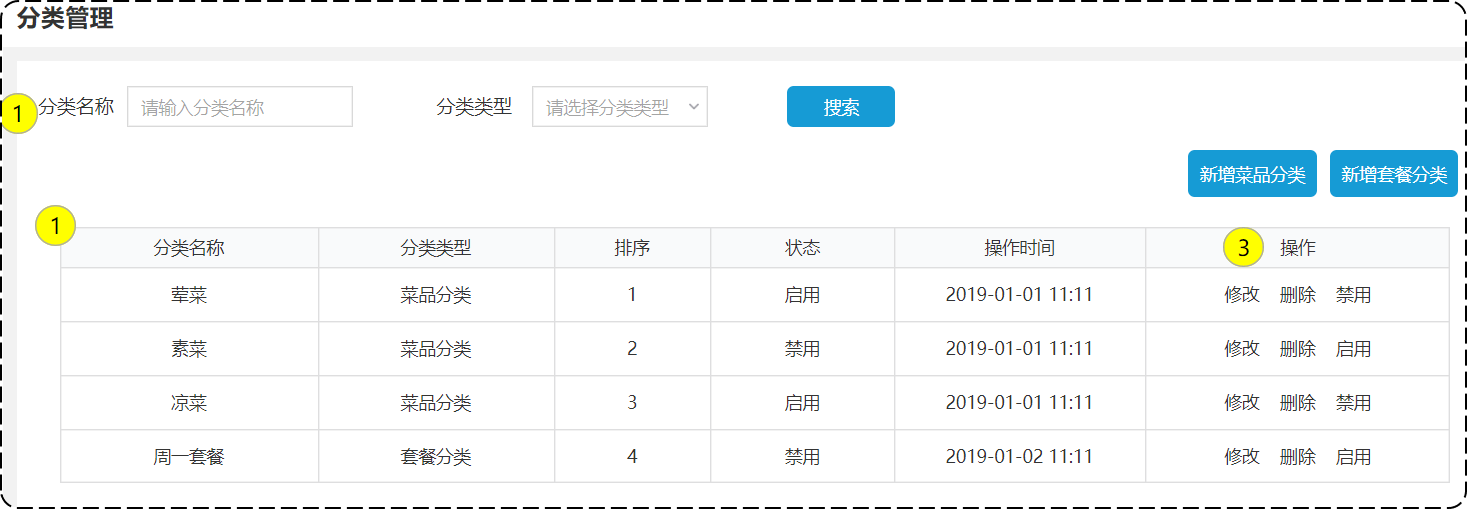 

**业务规则：**

- 分类名称必须是唯一的
- 分类按照类型可以分为菜品分类和套餐分类
- 新添加的分类状态默认为“禁用”


#### 5.1.2 接口设计

根据上述原型图分析，菜品分类模块共涉及6个接口。

- 新增分类
- 分类分页查询
- 根据id删除分类
- 修改分类
- 启用禁用分类
- 根据类型查询分类

接下来，详细地分析每个接口。

找到资料-->项目接口文档-->苍穹外卖-管理端接口.html

**1). 新增分类**

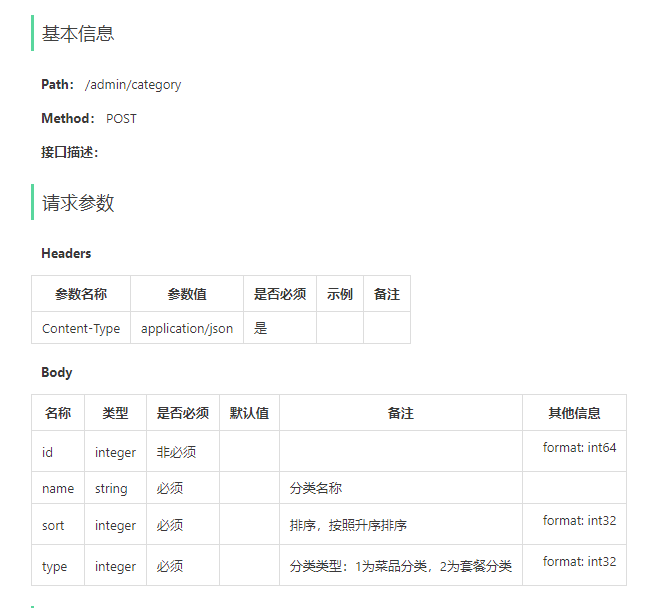 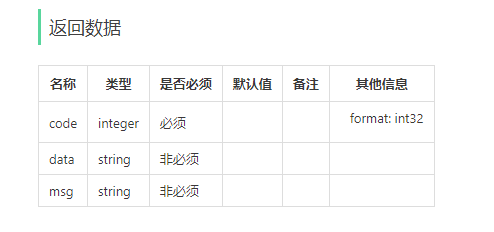

**2). 分类分页查询**

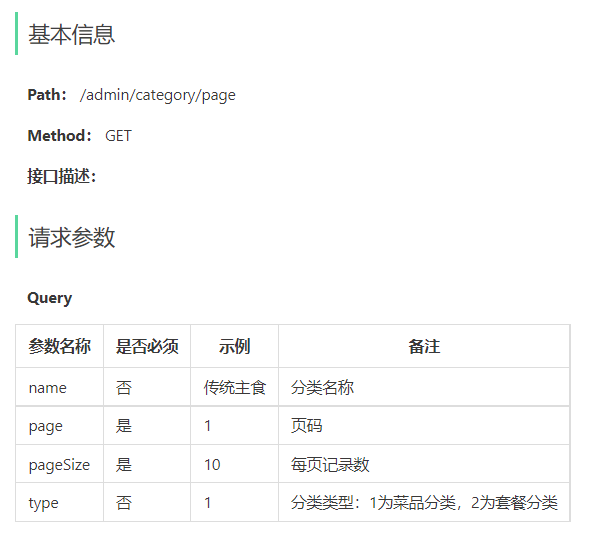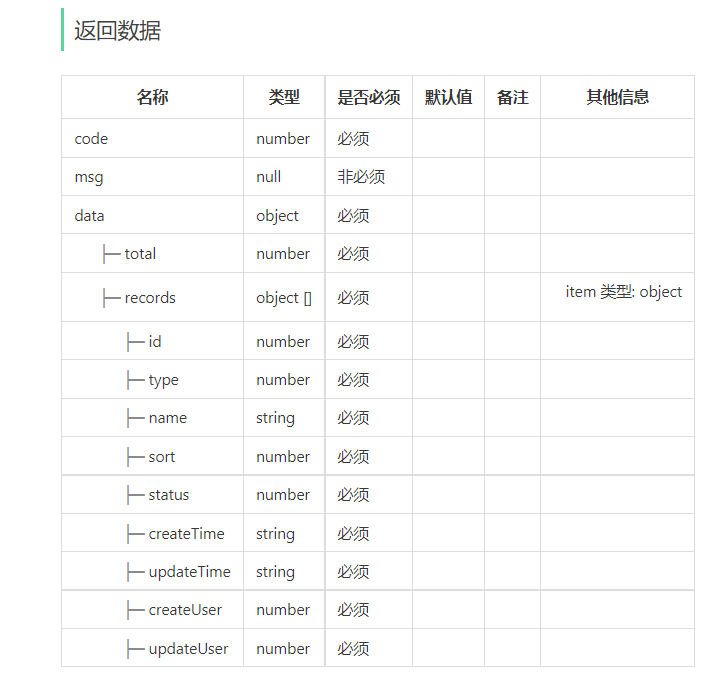

**3). 根据id删除分类**

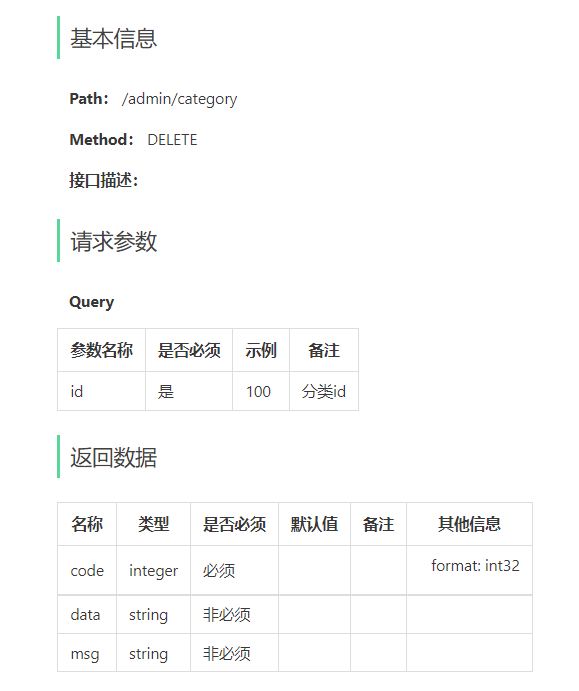 

**4). 修改分类**

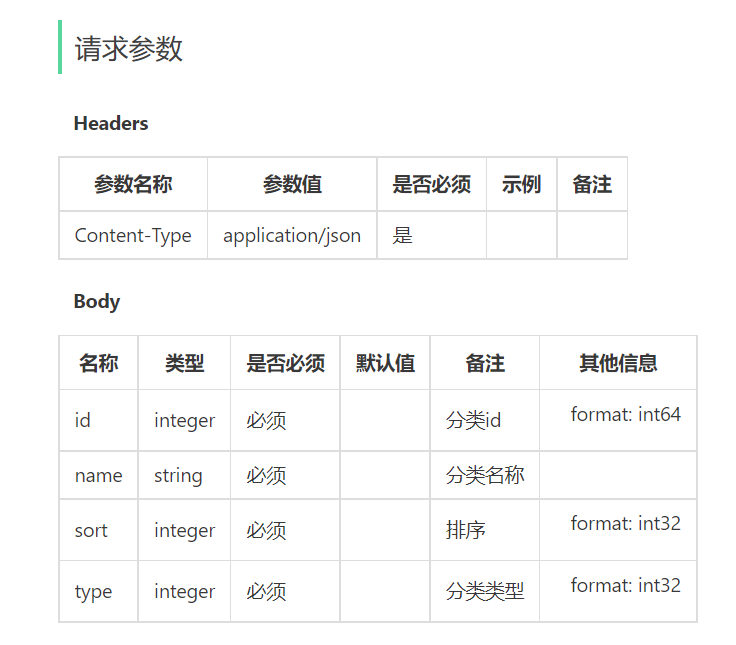 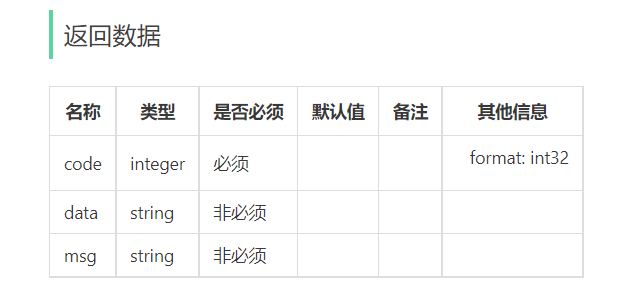

**5). 启用禁用分类**

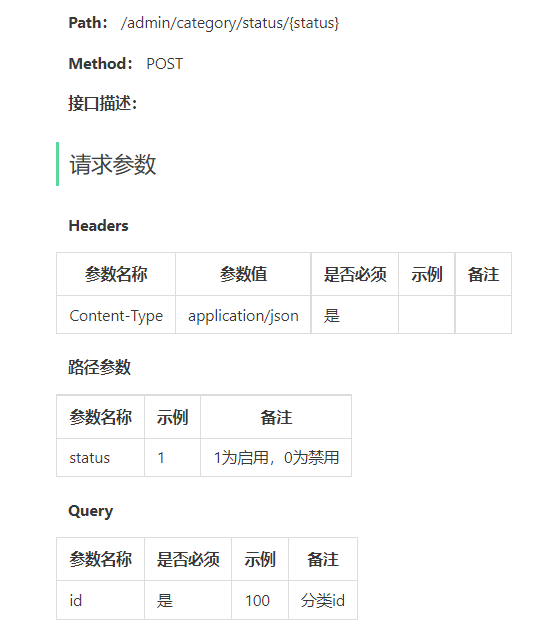 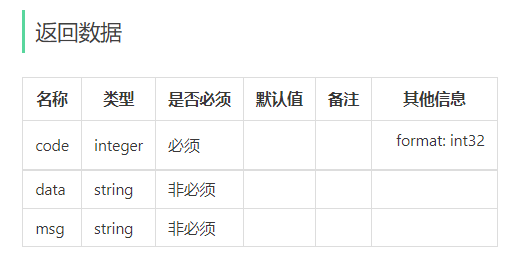

**6). 根据类型查询分类**

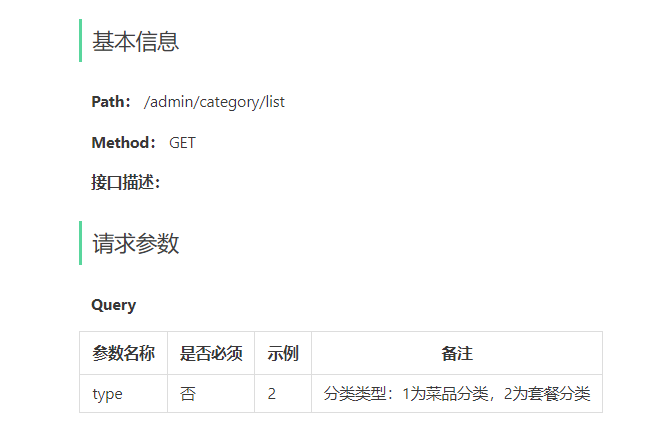 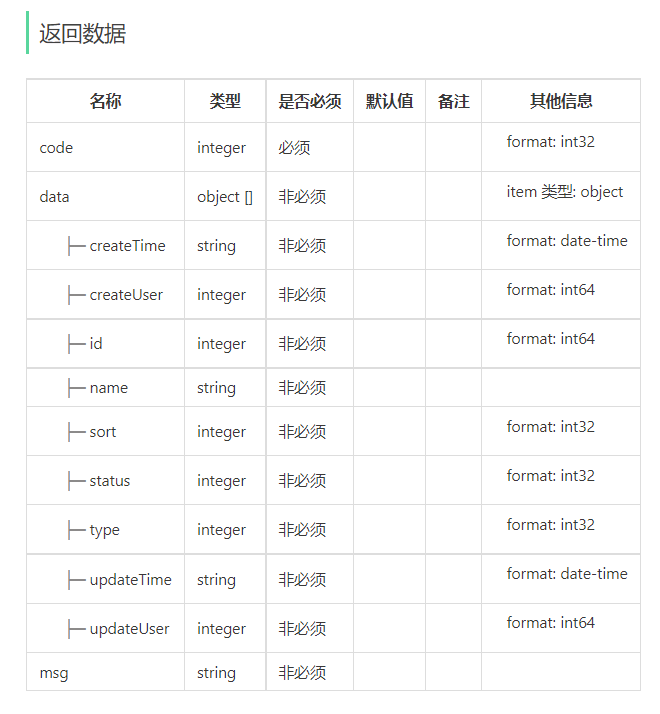

#### 5.1.3 表设计

**category表结构：**

| **字段名**  | **数据类型** | **说明**     | **备注**            |
| ----------- | ------------ | ------------ | ------------------- |
| id          | bigint       | 主键         | 自增                |
| name        | varchar(32)  | 分类名称     | 唯一                |
| type        | int          | 分类类型     | 1菜品分类 2套餐分类 |
| sort        | int          | 排序字段     | 用于分类数据的排序  |
| status      | int          | 状态         | 1启用 0禁用         |
| create_time | datetime     | 创建时间     |                     |
| update_time | datetime     | 最后修改时间 |                     |
| create_user | bigint       | 创建人id     |                     |
| update_user | bigint       | 最后修改人id |                     |


### 分类规则要与员工区分（补充）

| 属性 | 员工 | 分类 |
| --- | --- | --- |
| 新增默认状态 | 启用1 | 禁用0 |
| 唯一字段 | username | name，按课程全表唯一约束 |
| 主要类型 | 后台员工账号 | type=1菜品，type=2套餐 |
| 展示排序 | 创建时间倒序 | sort升序，再按创建时间倒序 |
| 删除规则 | 本章未开发员工删除 | 关联菜品或套餐时禁止删除 |

分类分页接口用于维护列表，可显示启用和禁用记录；分类 `/list` 接口使用 `where status = 1`，用于选择可用分类。不能把禁用分类暂时不出现在下拉框，误判成新增失败。

管理端Controller的分类列表提供给管理页面使用；用户端浏览接口将在后续章节实现，不应直接开放整个管理接口。


### 5.2 代码导入

> **PPT对照：** 第83页。

导入资料中的分类管理模块功能代码即可

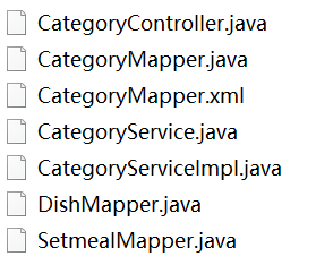 

可按照mapper-->service-->controller依次导入，这样代码不会显示相应的报错。

进入到sky-server模块中

#### 5.2.1 Mapper层

**DishMapper.java**

```java
package com.sky.mapper;

import org.apache.ibatis.annotations.Mapper;
import org.apache.ibatis.annotations.Select;

@Mapper
public interface DishMapper {

    /**
     * 根据分类id查询菜品数量
     * @param categoryId
     * @return
     */
    @Select("select count(id) from dish where category_id = #{categoryId}")
    Integer countByCategoryId(Long categoryId);

}

```

**SetmealMapper.java**

```java
package com.sky.mapper;

import org.apache.ibatis.annotations.Mapper;
import org.apache.ibatis.annotations.Select;

@Mapper
public interface SetmealMapper {

    /**
     * 根据分类id查询套餐的数量
     * @param id
     * @return
     */
    @Select("select count(id) from setmeal where category_id = #{categoryId}")
    Integer countByCategoryId(Long id);

}
```

**CategoryMapper.java**

```java
package com.sky.mapper;

import com.github.pagehelper.Page;
import com.sky.dto.CategoryPageQueryDTO;
import com.sky.entity.Category;
import org.apache.ibatis.annotations.Delete;
import org.apache.ibatis.annotations.Insert;
import org.apache.ibatis.annotations.Mapper;

import java.util.List;

@Mapper
public interface CategoryMapper {

    /**
     * 插入数据
     * @param category
     */
    @Insert("insert into category(type, name, sort, status, create_time, update_time, create_user, update_user)" +
            " VALUES" +
            " (#{type}, #{name}, #{sort}, #{status}, #{createTime}, #{updateTime}, #{createUser}, #{updateUser})")
    void insert(Category category);

    /**
     * 分页查询
     * @param categoryPageQueryDTO
     * @return
     */
    Page<Category> pageQuery(CategoryPageQueryDTO categoryPageQueryDTO);

    /**
     * 根据id删除分类
     * @param id
     */
    @Delete("delete from category where id = #{id}")
    void deleteById(Long id);

    /**
     * 根据id修改分类
     * @param category
     */
    void update(Category category);

    /**
     * 根据类型查询分类
     * @param type
     * @return
     */
    List<Category> list(Integer type);
}
```

**CategoryMapper.xml**,进入到resources/mapper目录下

```xml
<?xml version="1.0" encoding="UTF-8" ?>
<!DOCTYPE mapper PUBLIC "-//mybatis.org//DTD Mapper 3.0//EN"
        "http://mybatis.org/dtd/mybatis-3-mapper.dtd" >
<mapper namespace="com.sky.mapper.CategoryMapper">

    <select id="pageQuery" resultType="com.sky.entity.Category">
        select * from category
        <where>
            <if test="name != null and name != ''">
                and name like concat('%',#{name},'%')
            </if>
            <if test="type != null">
                and type = #{type}
            </if>
        </where>
        order by sort asc , create_time desc
    </select>

    <update id="update" parameterType="Category">
        update category
        <set>
            <if test="type != null">
                type = #{type},
            </if>
            <if test="name != null">
                name = #{name},
            </if>
            <if test="sort != null">
                sort = #{sort},
            </if>
            <if test="status != null">
                status = #{status},
            </if>
            <if test="updateTime != null">
                update_time = #{updateTime},
            </if>
            <if test="updateUser != null">
                update_user = #{updateUser}
            </if>
        </set>
        where id = #{id}
    </update>

    <select id="list" resultType="Category">
        select * from category
        where status = 1
        <if test="type != null">
            and type = #{type}
        </if>
        order by sort asc,create_time desc
    </select>
</mapper>

```


#### 5.2.2 Service层

**CategoryService.java**

```java
package com.sky.service;

import com.sky.dto.CategoryDTO;
import com.sky.dto.CategoryPageQueryDTO;
import com.sky.entity.Category;
import com.sky.result.PageResult;
import java.util.List;

public interface CategoryService {

    /**
     * 新增分类
     * @param categoryDTO
     */
    void save(CategoryDTO categoryDTO);

    /**
     * 分页查询
     * @param categoryPageQueryDTO
     * @return
     */
    PageResult pageQuery(CategoryPageQueryDTO categoryPageQueryDTO);

    /**
     * 根据id删除分类
     * @param id
     */
    void deleteById(Long id);

    /**
     * 修改分类
     * @param categoryDTO
     */
    void update(CategoryDTO categoryDTO);

    /**
     * 启用、禁用分类
     * @param status
     * @param id
     */
    void startOrStop(Integer status, Long id);

    /**
     * 根据类型查询分类
     * @param type
     * @return
     */
    List<Category> list(Integer type);
}

```

**EmployeeServiceImpl.java**

```java
package com.sky.service.impl;

import com.github.pagehelper.Page;
import com.github.pagehelper.PageHelper;
import com.sky.constant.MessageConstant;
import com.sky.constant.PasswordConstant;
import com.sky.constant.StatusConstant;
import com.sky.context.BaseContext;
import com.sky.dto.EmployeeDTO;
import com.sky.dto.EmployeeLoginDTO;
import com.sky.dto.EmployeePageQueryDTO;
import com.sky.entity.Employee;
import com.sky.exception.AccountLockedException;
import com.sky.exception.AccountNotFoundException;
import com.sky.exception.PasswordErrorException;
import com.sky.mapper.EmployeeMapper;
import com.sky.result.PageResult;
import com.sky.service.EmployeeService;
import org.springframework.beans.BeanUtils;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.stereotype.Service;
import org.springframework.util.DigestUtils;

import java.time.LocalDateTime;
import java.util.List;

@Service
public class EmployeeServiceImpl implements EmployeeService {

    @Autowired
    private EmployeeMapper employeeMapper;

    /**
     * 员工登录
     *
     * @param employeeLoginDTO
     * @return
     */
    public Employee login(EmployeeLoginDTO employeeLoginDTO) {
        String username = employeeLoginDTO.getUsername();
        String password = employeeLoginDTO.getPassword();

        //1、根据用户名查询数据库中的数据
        Employee employee = employeeMapper.getByUsername(username);

        //2、处理各种异常情况（用户名不存在、密码不对、账号被锁定）
        if (employee == null) {
            //账号不存在
            throw new AccountNotFoundException(MessageConstant.ACCOUNT_NOT_FOUND);
        }

        //密码比对
        // TODO 后期需要进行md5加密，然后再进行比对
        password = DigestUtils.md5DigestAsHex(password.getBytes());
        if (!password.equals(employee.getPassword())) {
            //密码错误
            throw new PasswordErrorException(MessageConstant.PASSWORD_ERROR);
        }

        if (employee.getStatus() == StatusConstant.DISABLE) {
            //账号被锁定
            throw new AccountLockedException(MessageConstant.ACCOUNT_LOCKED);
        }

        //3、返回实体对象
        return employee;
    }

    /**
     * 新增员工
     *
     * @param employeeDTO
     */
    public void save(EmployeeDTO employeeDTO) {
        Employee employee = new Employee();

        //对象属性拷贝
        BeanUtils.copyProperties(employeeDTO, employee);

        //设置账号的状态，默认正常状态 1表示正常 0表示锁定
        employee.setStatus(StatusConstant.ENABLE);

        //设置密码，默认密码123456
        employee.setPassword(DigestUtils.md5DigestAsHex(PasswordConstant.DEFAULT_PASSWORD.getBytes()));

        //设置当前记录的创建时间和修改时间
        employee.setCreateTime(LocalDateTime.now());
        employee.setUpdateTime(LocalDateTime.now());

        //设置当前记录创建人id和修改人id
        employee.setCreateUser(BaseContext.getCurrentId());//目前写个假数据，后期修改
        employee.setUpdateUser(BaseContext.getCurrentId());

        employeeMapper.insert(employee);
    }

    /**
     * 分页查询
     *
     * @param employeePageQueryDTO
     * @return
     */
    public PageResult pageQuery(EmployeePageQueryDTO employeePageQueryDTO) {
        // select * from employee limit 0,10
        //开始分页查询
        PageHelper.startPage(employeePageQueryDTO.getPage(), employeePageQueryDTO.getPageSize());

        Page<Employee> page = employeeMapper.pageQuery(employeePageQueryDTO);

        long total = page.getTotal();
        List<Employee> records = page.getResult();

        return new PageResult(total, records);
    }

    /**
     * 启用禁用员工账号
     *
     * @param status
     * @param id
     */
    public void startOrStop(Integer status, Long id) {
        Employee employee = Employee.builder()
                .status(status)
                .id(id)
                .build();

        employeeMapper.update(employee);
    }

    /**
     * 根据id查询员工
     *
     * @param id
     * @return
     */
    public Employee getById(Long id) {
        Employee employee = employeeMapper.getById(id);
        employee.setPassword("****");
        return employee;
    }

    /**
     * 编辑员工信息
     *
     * @param employeeDTO
     */
    public void update(EmployeeDTO employeeDTO) {
        Employee employee = new Employee();
        BeanUtils.copyProperties(employeeDTO, employee);

        employee.setUpdateTime(LocalDateTime.now());
        employee.setUpdateUser(BaseContext.getCurrentId());

        employeeMapper.update(employee);
    }

}
```


#### 5.2.3 Controller层

**CategoryController.java**

```java
package com.sky.controller.admin;

import com.sky.dto.CategoryDTO;
import com.sky.dto.CategoryPageQueryDTO;
import com.sky.entity.Category;
import com.sky.result.PageResult;
import com.sky.result.Result;
import com.sky.service.CategoryService;
import io.swagger.annotations.Api;
import io.swagger.annotations.ApiOperation;
import lombok.extern.slf4j.Slf4j;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.web.bind.annotation.*;
import java.util.List;

/**
 * 分类管理
 */
@RestController
@RequestMapping("/admin/category")
@Api(tags = "分类相关接口")
@Slf4j
public class CategoryController {

    @Autowired
    private CategoryService categoryService;

    /**
     * 新增分类
     * @param categoryDTO
     * @return
     */
    @PostMapping
    @ApiOperation("新增分类")
    public Result<String> save(@RequestBody CategoryDTO categoryDTO){
        log.info("新增分类：{}", categoryDTO);
        categoryService.save(categoryDTO);
        return Result.success();
    }

    /**
     * 分类分页查询
     * @param categoryPageQueryDTO
     * @return
     */
    @GetMapping("/page")
    @ApiOperation("分类分页查询")
    public Result<PageResult> page(CategoryPageQueryDTO categoryPageQueryDTO){
        log.info("分页查询：{}", categoryPageQueryDTO);
        PageResult pageResult = categoryService.pageQuery(categoryPageQueryDTO);
        return Result.success(pageResult);
    }

    /**
     * 删除分类
     * @param id
     * @return
     */
    @DeleteMapping
    @ApiOperation("删除分类")
    public Result<String> deleteById(Long id){
        log.info("删除分类：{}", id);
        categoryService.deleteById(id);
        return Result.success();
    }

    /**
     * 修改分类
     * @param categoryDTO
     * @return
     */
    @PutMapping
    @ApiOperation("修改分类")
    public Result<String> update(@RequestBody CategoryDTO categoryDTO){
        categoryService.update(categoryDTO);
        return Result.success();
    }

    /**
     * 启用、禁用分类
     * @param status
     * @param id
     * @return
     */
    @PostMapping("/status/{status}")
    @ApiOperation("启用禁用分类")
    public Result<String> startOrStop(@PathVariable("status") Integer status, Long id){
        categoryService.startOrStop(status,id);
        return Result.success();
    }

    /**
     * 根据类型查询分类
     * @param type
     * @return
     */
    @GetMapping("/list")
    @ApiOperation("根据类型查询分类")
    public Result<List<Category>> list(Integer type){
        List<Category> list = categoryService.list(type);
        return Result.success(list);
    }
}
```

全部导入完毕后，进行编译

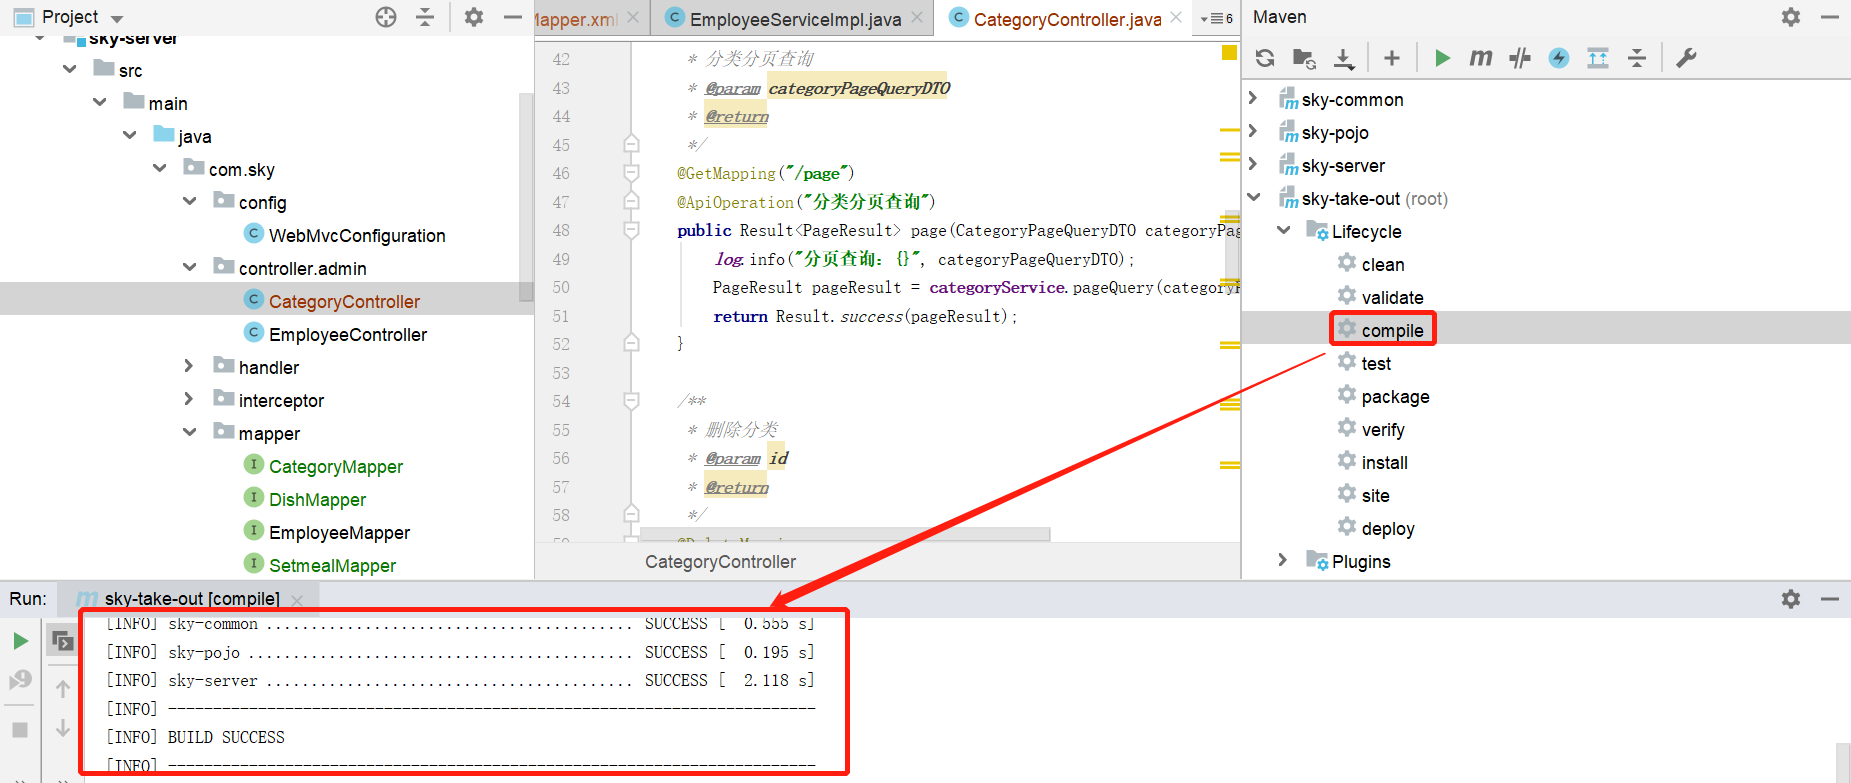


### 分类实现补齐（勘误与补充）

原讲义这一节贴了EmployeeServiceImpl，缺少分类实现。应保留已有员工类，另创建 `com.sky.service.impl.CategoryServiceImpl` 实现CategoryService。下面按原Mapper接口和六个业务方法补齐，不是修改原讲义代码。

#### DTO与异常约定

初始工程已提供对应DTO时直接复用。根据接口截图，CategoryDTO需要 `Long id`、`String name`、`Integer type`、`Integer sort`；CategoryPageQueryDTO需要 `int page`、`int pageSize`、`String name`、`Integer type`。type是可选查询参数，不能用默认0表达“没传”。实体Category还包含状态与审计字段。

为了使补充示例明确，使用独立的 `CategoryOperationException` 返回业务错误。课程已有分类业务异常和处理器时，替换为既有异常并复用统一处理，不重复建立另一套体系。

```java
package com.sky.exception;

public class CategoryOperationException extends RuntimeException {
    public CategoryOperationException(String message) {
        super(message);
    }
}
```

在现有GlobalExceptionHandler内加入以下方法；这个方法与唯一键异常处理互补。

```java
@ExceptionHandler(com.sky.exception.CategoryOperationException.class)
public Result<Void> handleCategoryOperation(
        com.sky.exception.CategoryOperationException ex) {
    return Result.error(ex.getMessage());
}
```

#### CategoryServiceImpl补充示例

```java
package com.sky.service.impl;

import com.github.pagehelper.Page;
import com.github.pagehelper.PageHelper;
import com.sky.constant.StatusConstant;
import com.sky.context.BaseContext;
import com.sky.dto.CategoryDTO;
import com.sky.dto.CategoryPageQueryDTO;
import com.sky.entity.Category;
import com.sky.exception.CategoryOperationException;
import com.sky.mapper.CategoryMapper;
import com.sky.mapper.DishMapper;
import com.sky.mapper.SetmealMapper;
import com.sky.result.PageResult;
import com.sky.service.CategoryService;
import org.springframework.beans.BeanUtils;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.stereotype.Service;
import org.springframework.transaction.annotation.Transactional;

import java.time.LocalDateTime;
import java.util.List;

@Service
public class CategoryServiceImpl implements CategoryService {
    @Autowired
    private CategoryMapper categoryMapper;
    @Autowired
    private DishMapper dishMapper;
    @Autowired
    private SetmealMapper setmealMapper;

    @Override
    public void save(CategoryDTO dto) {
        if (dto == null || dto.getName() == null || dto.getName().trim().isEmpty()
                || dto.getType() == null || dto.getSort() == null) {
            throw new CategoryOperationException("分类名称、类型和排序不能为空");
        }
        checkType(dto.getType());
        Category category = new Category();
        BeanUtils.copyProperties(dto, category);
        category.setId(null);
        category.setName(dto.getName().trim());
        category.setStatus(StatusConstant.DISABLE);
        LocalDateTime now = LocalDateTime.now();
        Long operatorId = currentEmployeeId();
        category.setCreateTime(now);
        category.setUpdateTime(now);
        category.setCreateUser(operatorId);
        category.setUpdateUser(operatorId);
        categoryMapper.insert(category);
    }

    @Override
    public PageResult pageQuery(CategoryPageQueryDTO dto) {
        // 100是本补充示例的页大小上限，应按实际接口约定配置。
        if (dto == null || dto.getPage() < 1
                || dto.getPageSize() < 1 || dto.getPageSize() > 100) {
            throw new CategoryOperationException("分页参数不合法");
        }
        checkType(dto.getType());
        PageHelper.startPage(dto.getPage(), dto.getPageSize());
        Page<Category> page = categoryMapper.pageQuery(dto);
        return new PageResult(page.getTotal(), page.getResult());
    }

    @Override
    @Transactional
    public void deleteById(Long id) {
        checkId(id);
        if (dishMapper.countByCategoryId(id) > 0) {
            throw new CategoryOperationException("当前分类关联了菜品，不能删除");
        }
        if (setmealMapper.countByCategoryId(id) > 0) {
            throw new CategoryOperationException("当前分类关联了套餐，不能删除");
        }
        categoryMapper.deleteById(id);
    }

    @Override
    public void update(CategoryDTO dto) {
        if (dto == null) {
            throw new CategoryOperationException("分类参数不能为空");
        }
        checkId(dto.getId());
        checkType(dto.getType());
        if (dto.getName() != null && dto.getName().trim().isEmpty()) {
            throw new CategoryOperationException("分类名称不能为空字符串");
        }
        Category category = new Category();
        BeanUtils.copyProperties(dto, category);
        if (dto.getName() != null) {
            category.setName(dto.getName().trim());
        }
        category.setUpdateTime(LocalDateTime.now());
        category.setUpdateUser(currentEmployeeId());
        categoryMapper.update(category);
    }

    @Override
    public void startOrStop(Integer status, Long id) {
        checkId(id);
        if (status == null || (status != 0 && status != 1)) {
            throw new CategoryOperationException("分类状态只允许0或1");
        }
        Category category = new Category();
        category.setId(id);
        category.setStatus(status);
        category.setUpdateTime(LocalDateTime.now());
        category.setUpdateUser(currentEmployeeId());
        categoryMapper.update(category);
    }

    @Override
    public List<Category> list(Integer type) {
        checkType(type);
        return categoryMapper.list(type);
    }

    private void checkId(Long id) {
        if (id == null || id <= 0) {
            throw new CategoryOperationException("分类id不合法");
        }
    }

    private void checkType(Integer type) {
        if (type != null && type != 1 && type != 2) {
            throw new CategoryOperationException("分类类型只允许1或2");
        }
    }

    private Long currentEmployeeId() {
        Long id = BaseContext.getCurrentId();
        if (id == null) {
            throw new CategoryOperationException("缺少当前登录员工上下文");
        }
        return id;
    }
}
```

该示例使用原讲义的void Mapper方法。不存在的正整数id仍可能影响0行；若要求明确报错，应在Mapper补充存在性查询或改成返回影响行数。字段长度、排序范围、操作权限与关联后能否修改type也要按业务规则校验。

`@Transactional`使方法内的数据库操作参加事务，不能单独消除“检查后又有人新增关联”的竞态。严格并发完整性还需数据库约束、锁或统一写入规则。本章先掌握业务检查与异常返回。

#### Mapper参数名勘误

原SetmealMapper的方法参数名是 `id`，SQL占位符写的是 `#{categoryId}`。单个简单类型参数在部分MyBatis用法中仍能解析，不能一概断言必然报错；但明确命名更便于后续维护，可改为：

```java
@Select("select count(id) from setmeal where category_id = #{categoryId}")
Integer countByCategoryId(
        @org.apache.ibatis.annotations.Param("categoryId") Long categoryId);
```

Mapper XML里的 `parameterType="Category"`、`resultType="Category"`需要配置类型别名；未配置别名时使用 `com.sky.entity.Category`。导入顺序可按DTO/实体、Mapper与XML、Service接口和实现、Controller推进，避免漏掉实现类导致注入失败。


### 5.3 功能测试

> **PPT对照：** 第85页。

重启服务，访问http://localhost:80,进入分类管理

**分页查询：**

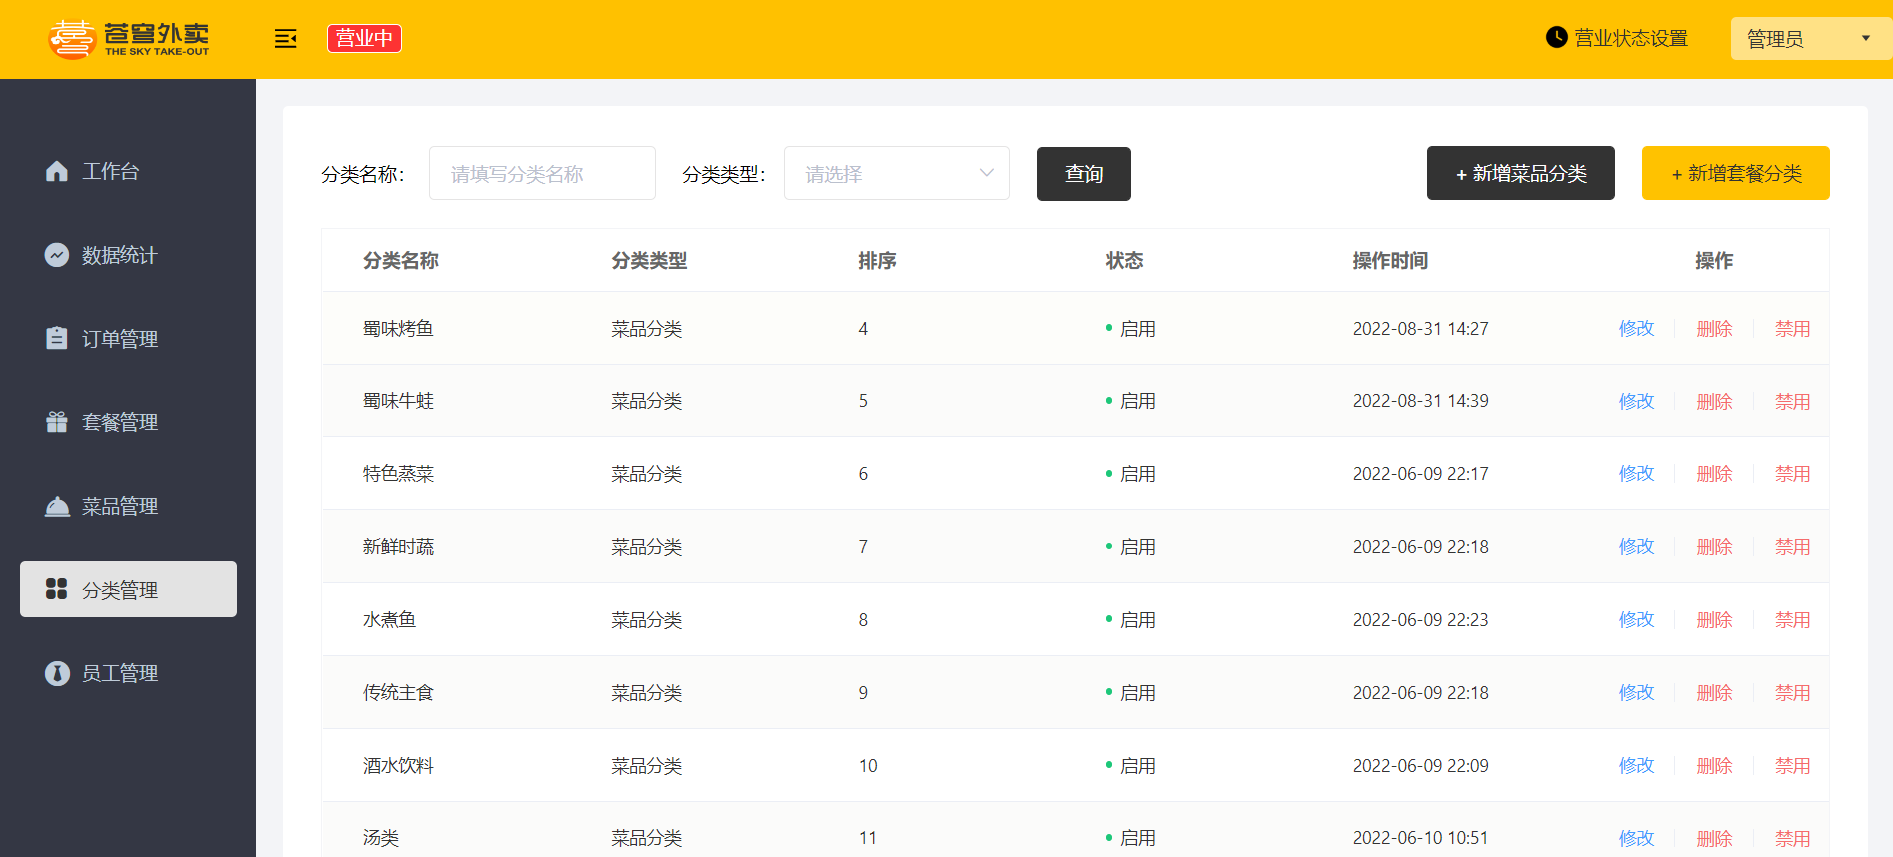 

**分类类型：**

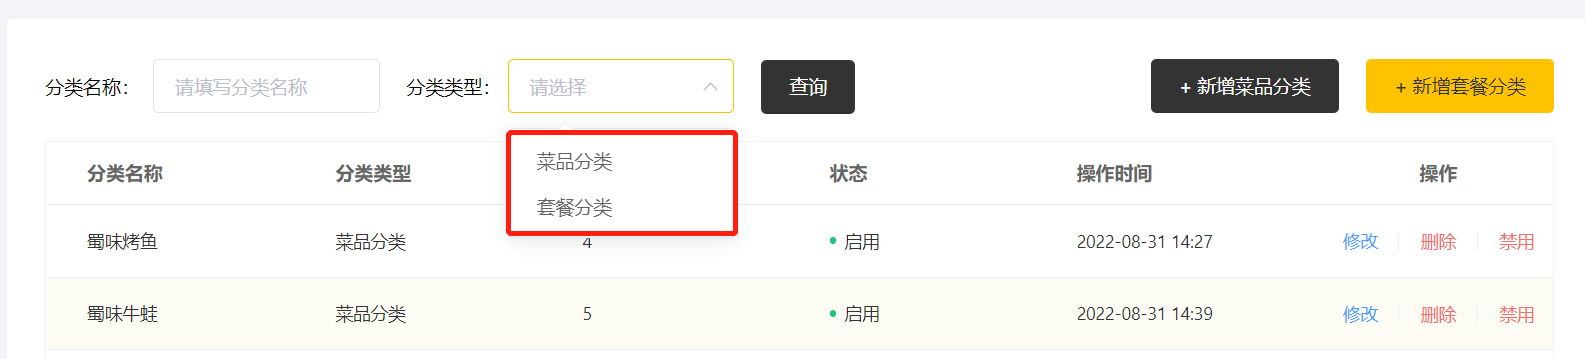 

**启用禁用：**

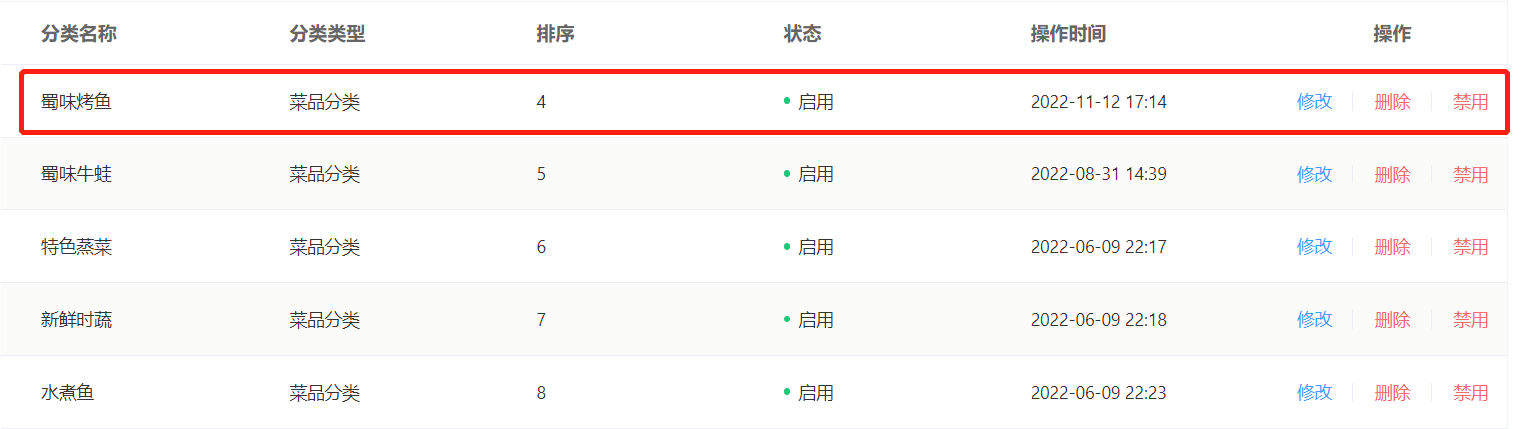 

点击禁用

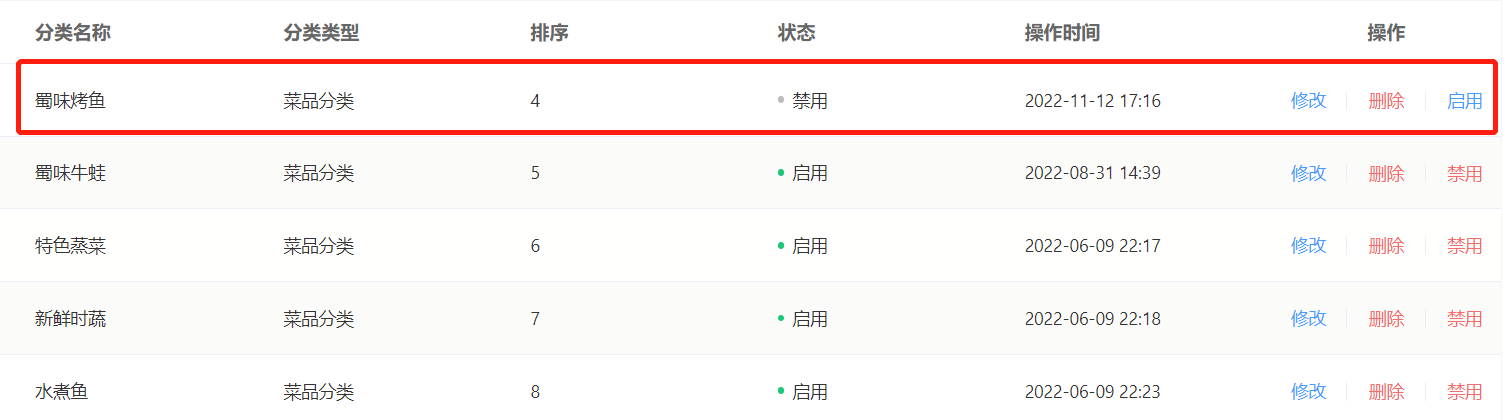 

**修改：**

回显

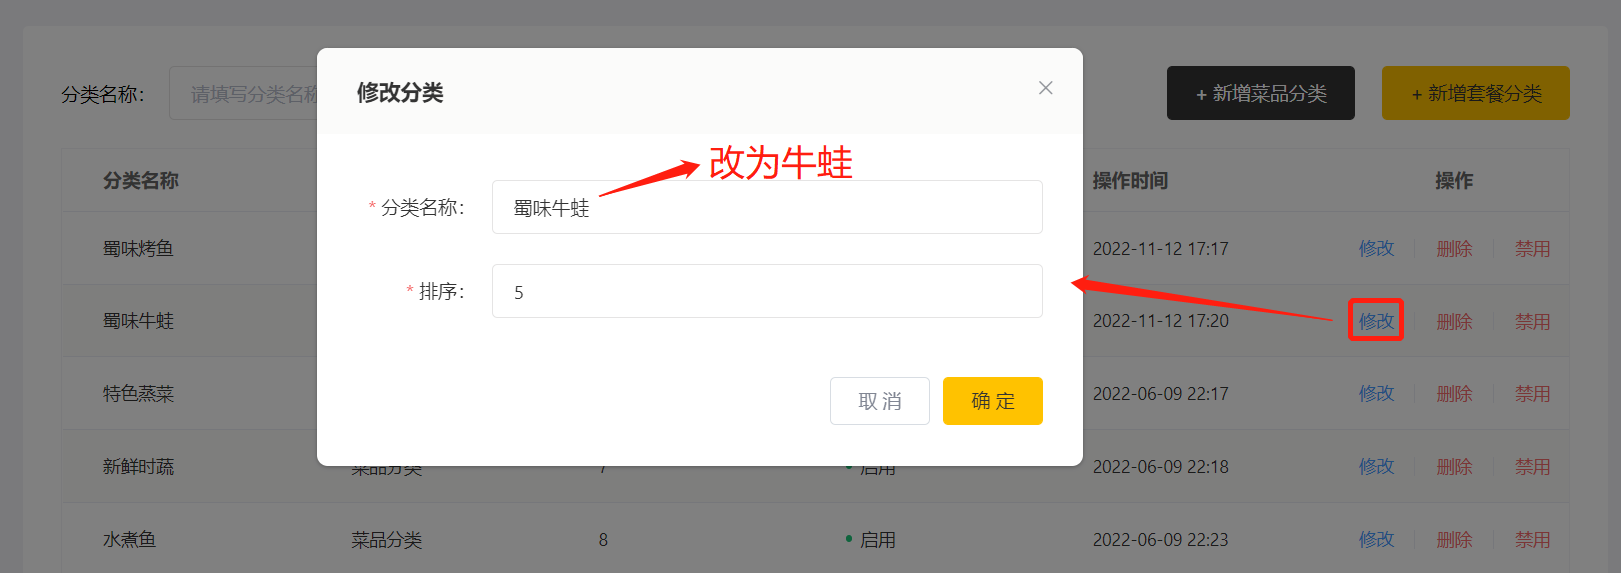  

修改后

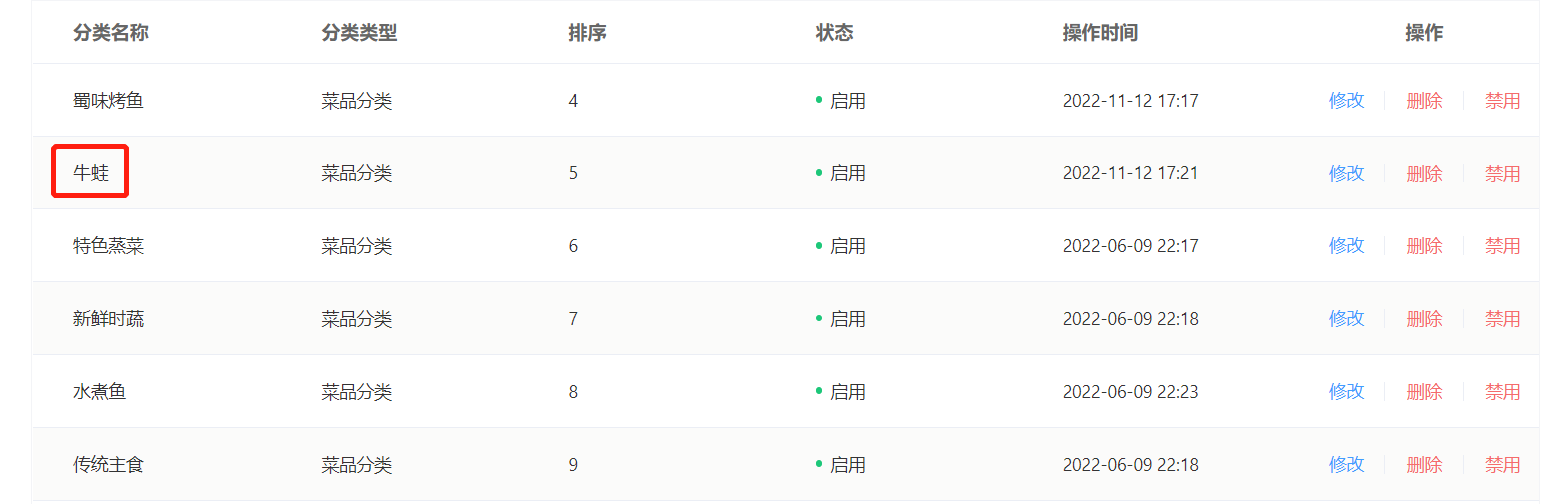

**新增：**

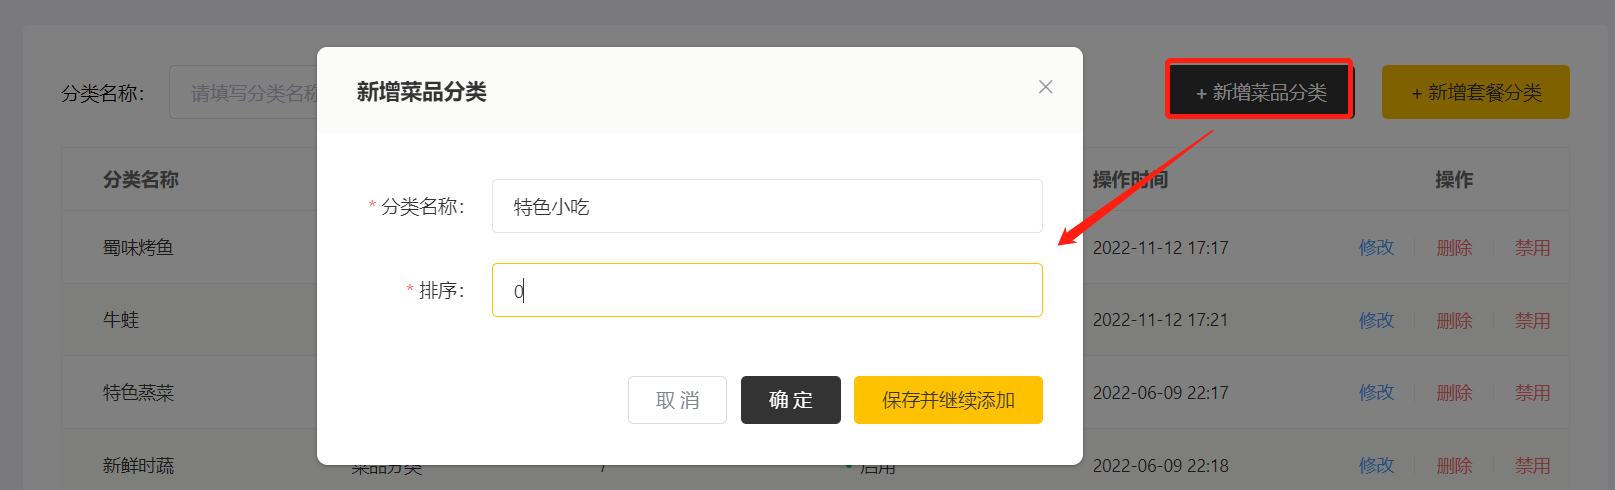 

点击确定，查询列表

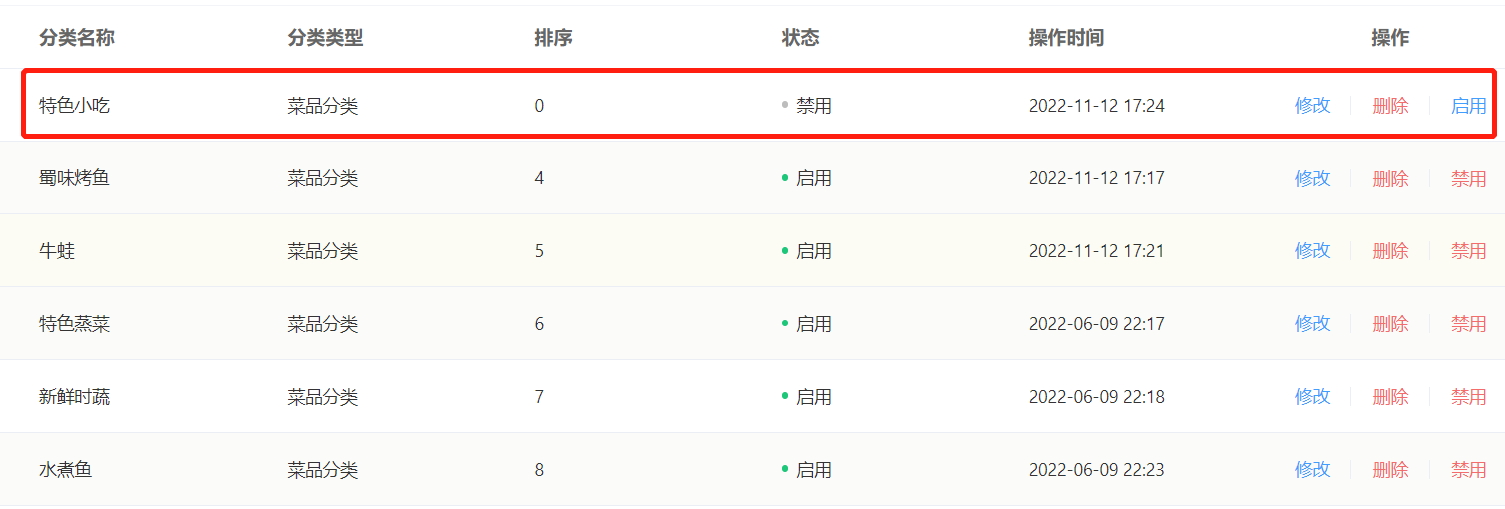 

**删除：**

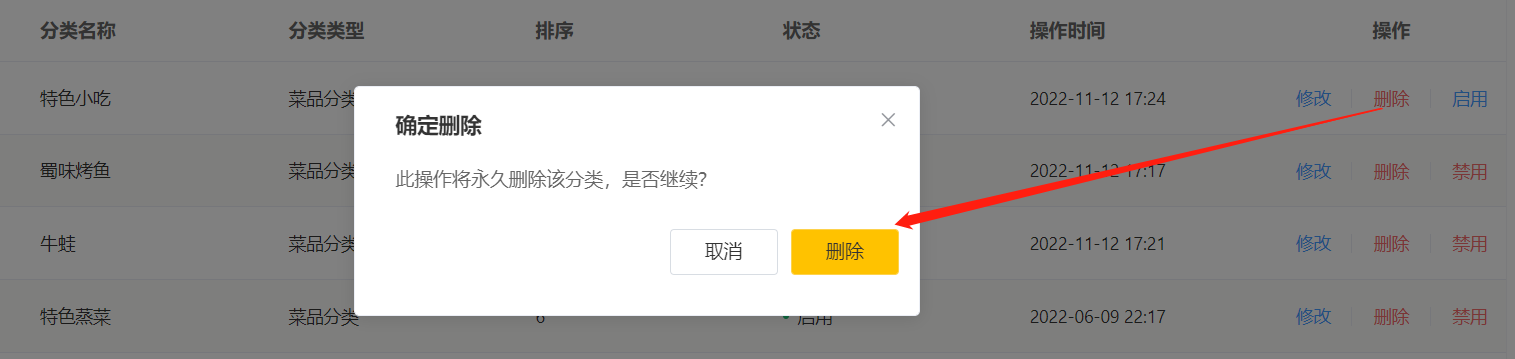 

删除后，查询分类列表

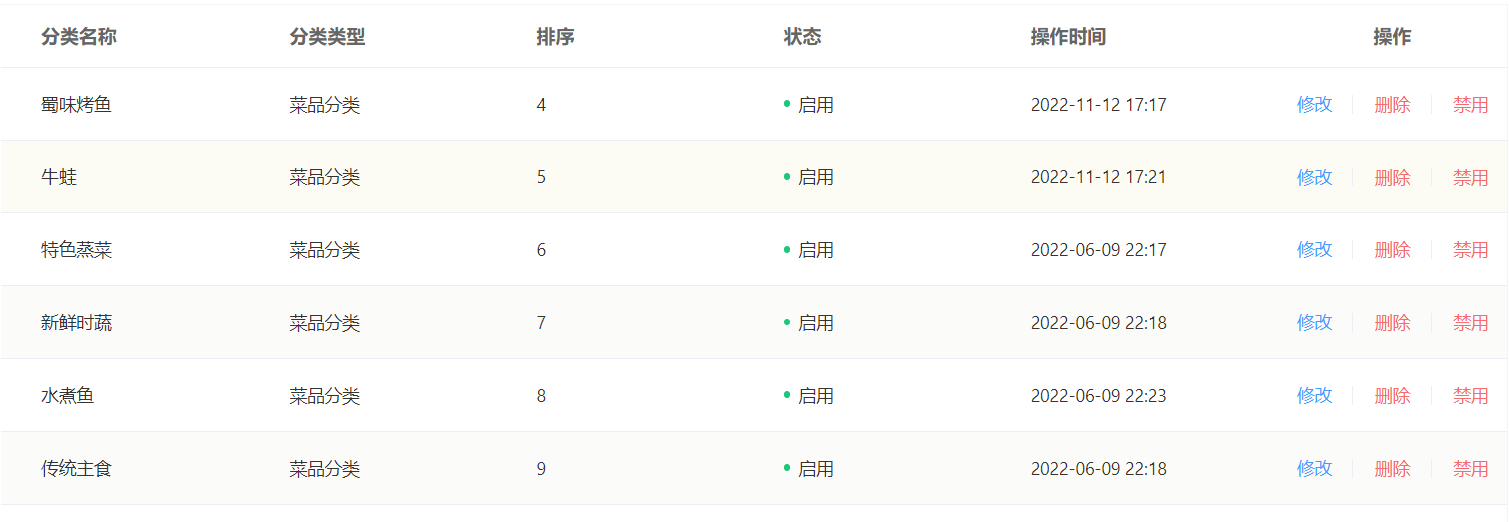 

删除成功


### 分类测试矩阵（补充）

| 操作 | 核对结果 |
| --- | --- |
| 新增分类 | 默认status=0，操作者来自当前员工，名称不可重复 |
| 分页 | 名称、类型筛选正确，sort升序，返回total与records |
| 启用分类 | status变为1，同类型 `/list` 中可见 |
| 禁用分类 | 管理分页仍可维护，`/list` 不再返回 |
| 修改分类 | 名称与排序变化，创建字段保持不变 |
| 删除空分类 | 数据消失，关联记录无变化 |
| 删除关联菜品的分类 | 返回业务错误，分类保持存在 |
| 删除关联套餐的分类 | 返回业务错误，分类保持存在 |

不能只点一次删除空分类，就认为关联保护已经实现。先在测试库确认目标关联关系，再分别验证菜品与套餐两条分支。


### 5.4 代码提交

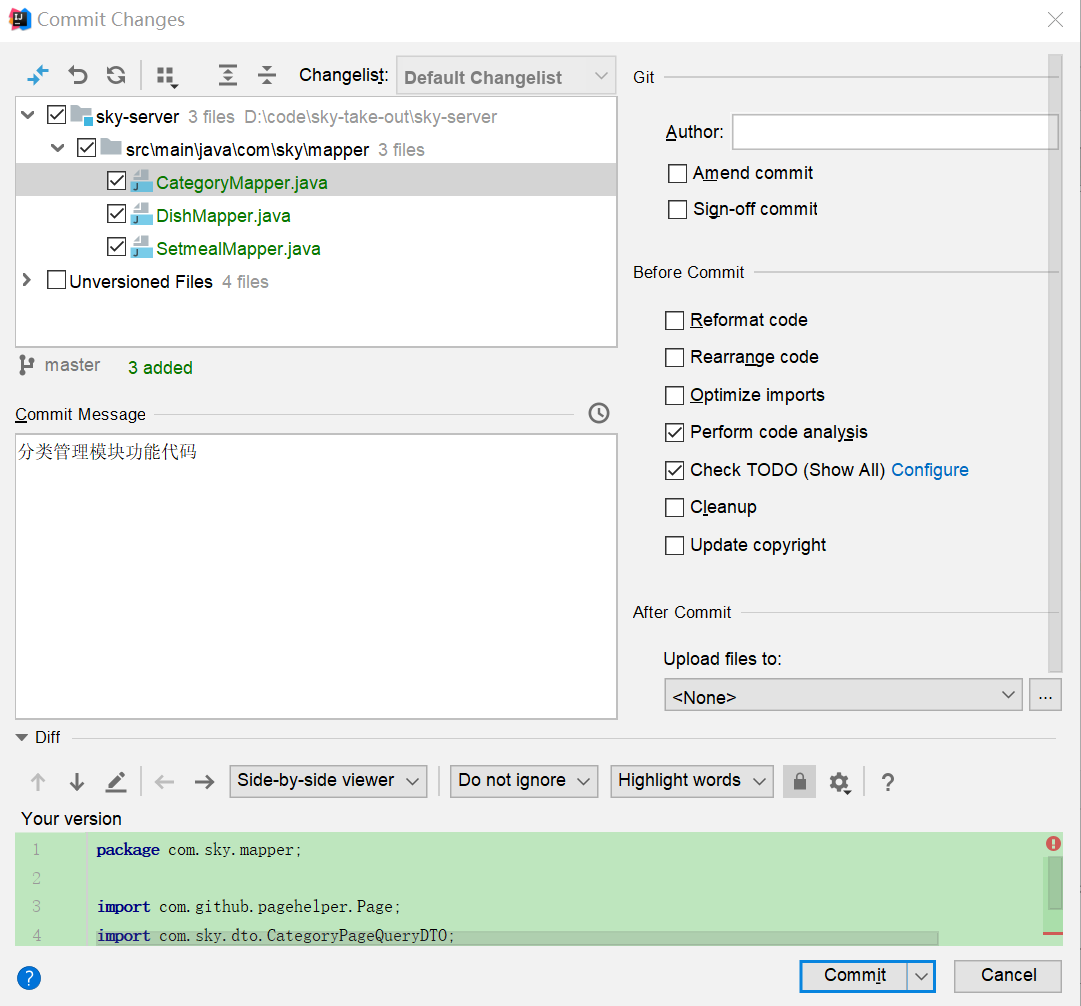 

后续步骤和上述功能代码提交一致，不再赘述。


## 复习速查与本章验收（补充）

| 知识点 | 核心记忆 |
| --- | --- |
| DTO | 只接收允许修改的字段，服务端控制审计字段 |
| 新增员工 | 默认启用、课程默认密码、用户名唯一 |
| JWT与BaseContext | 拦截器验签提取id，Service读id，请求结束清理 |
| PageHelper | startPage后紧接Mapper查询，total不是当前页条数 |
| 动态SQL | where处理条件，set拼接非null字段并去掉末尾逗号 |
| 日期转换 | 消息转换器选ObjectMapper，格式由序列化配置决定 |
| 编辑 | 先回显，再保存；不更新创建信息、密码与状态 |
| 分类 | 类型1菜品/2套餐，默认禁用，按sort升序 |
| 删除分类 | 查询菜品与套餐关联数量，关联存在则禁止删除 |

### 常见问题排查

| 表现 | 检查方向 |
| --- | --- |
| 接口401、断点没到Controller | token请求头、过期时间、JWT校验 |
| 用户名重复出现500 | 唯一键异常类型、全局异常处理 |
| 创建人总是10或为空 | Service固定值、BaseContext设置、清理时机 |
| 分页查出全部数据 | PageHelper依赖与紧邻的Mapper查询 |
| Mapper找不到statement | namespace、id、XML位置与扫描配置 |
| 日期仍显示成数组或不含秒 | 实际ObjectMapper、JavaTime序列化与格式 |
| 按id回显出现空指针 | getById返回null却继续操作 |
| 分类Controller注入失败 | CategoryServiceImpl遗漏或包扫描不覆盖 |
| 禁用分类下拉框看不到 | `/list`只返回启用项，属预期行为 |
| 有关联的分类仍能删除 | 删除是否经过Service，两类关联检查是否齐全 |

### 跟练验收

- [ ] 取得有效token后，新增员工成功，数据库审计字段正确。
- [ ] 重复用户名返回业务错误，敏感字段不进入普通日志。
- [ ] 无token、过期token无法访问受保护接口。
- [ ] ThreadLocal请求结束清理，不把身份遗留给下一次请求。
- [ ] 员工分页的筛选、total、翻页与日期格式符合约定。
- [ ] 禁用员工不能再次登录；明确已有token的处理策略。
- [ ] 编辑回显和保存都正确，不改变password、status与创建信息。
- [ ] 分类六个接口都可访问，CategoryServiceImpl已正确接入业务工程。
- [ ] 分类新增默认禁用，列表与可用分类下拉框的范围正确。
- [ ] 关联菜品或套餐的分类均不能删除，空分类可删除。

### 自测问题

1. 为什么DTO不能完全替代业务校验？
2. 为什么“先查询用户名不存在”仍需要数据库唯一约束？
3. BaseContext中的员工id和请求参数中的员工id有什么不同？
4. ThreadLocal为什么需要remove？异步任务能否直接读取它？
5. GET分页、POST状态切换和PUT编辑分别从哪里接收参数？
6. total和records的数量有什么区别？
7. 动态update如何表达“不改字段”？如何表达“清空字段”？
8. 修改数据库status为什么不会自动撤销已签发的JWT？
9. 分类分页能看到禁用项，但分类list看不到，为什么？
10. 只检查菜品数量、不检查套餐数量，分类删除会遗漏什么规则？

下一章进入菜品管理，继续使用DTO、Service业务检查、MyBatis映射与接口联调，并处理菜品和口味等关联数据。
